**Import Libraries & Configure Environment**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy import stats
from collections import Counter, defaultdict
from datetime import timedelta
import warnings

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment setup completed successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("NetworkX version:", nx.__version__)

Environment setup completed successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3
NetworkX version: 3.6.1


# **STEP 1: DATASET LOADING**

**Load the Dataset**

In [ ]:
from google.colab import files
uploaded = files.upload()



Saving Procurement_data.csv to Procurement_data.csv


In [ ]:
# Get uploaded filename
file_name = next(iter(uploaded))

# Load dataset
raw_df = pd.read_csv(file_name, low_memory=False)

print("Dataset loaded successfully.")
print("-" * 60)

print("File name       :", file_name)
print("Rows            :", raw_df.shape[0])
print("Columns         :", raw_df.shape[1])

print("\nColumn names:")
print(list(raw_df.columns))

print("\nFirst 5 rows:")
display(raw_df.head())

Dataset loaded successfully.
------------------------------------------------------------
File name       : Procurement_data.csv
Rows            : 344504
Columns         : 32

Column names:
['Creation Date', 'Purchase Date', 'Fiscal Year', 'LPA Number', 'Purchase Order Number', 'Requisition Number', 'Acquisition Type', 'Sub-Acquisition Type', 'Acquisition Method', 'Sub-Acquisition Method', 'Department Name', 'Supplier Code', 'Supplier Name', 'Supplier Qualifications', 'Supplier Zip Code', 'CalCard', 'Item Name', 'Item Description', 'Quantity', 'Unit Price', 'Total Price', 'Classification Codes', 'Normalized UNSPSC', 'Commodity Title', 'Class', 'Class Title', 'Family', 'Family Title', 'Segment', 'Segment Title', 'Location', 'REMOVE AMERISOURCE']

First 5 rows:


,Creation Date,Purchase Date,Fiscal Year,LPA Number,Purchase Order Number,Requisition Number,Acquisition Type,Sub-Acquisition Type,Acquisition Method,Sub-Acquisition Method,Department Name,Supplier Code,Supplier Name,Supplier Qualifications,Supplier Zip Code,CalCard,Item Name,Item Description,Quantity,Unit Price,Total Price,Classification Codes,Normalized UNSPSC,Commodity Title,Class,Class Title,Family,Family Title,Segment,Segment Title,Location,REMOVE AMERISOURCE
0,8/27/2013,NaN,2013-2014,7-12-70-26,REQ0011118,REQ0011118,IT Goods,NaN,WSCA/Coop,NaN,"Consumer Affairs, Department of",1740272.0,Pitney Bowes,NaN,NaN,NO,USB,USB,1.0,$1.00,$1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1/29/2014,NaN,2013-2014,NaN,REQ0011932,REQ0011932,NON-IT Goods,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",1760085.0,Rodea Auto Tech,NaN,NaN,NO,Tire Disposal,Tire Disposal,2.0,$2.00,$4.00,76121504,76121504.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11/1/2013,NaN,2013-2014,NaN,REQ0011476,REQ0011476,IT Services,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",17224.0,"Smile Business Products, Inc",NaN,95841,NO,Labor,Labor,4.5,$150.00,$675.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95841\n(38.662263, -121.346136)",NaN
3,6/13/2014,6/5/2014,2013-2014,NaN,4500236642,NaN,NON-IT Goods,NaN,Informal Competitive,NaN,Correctional Health Care Services,1754462.0,ASHAN INC,CA-MB CA-SB,91436,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"91436\n(34.151642, -118.49051)",NaN
4,3/12/2014,3/12/2014,2013-2014,1-10-75-60A,4500221028,NaN,NON-IT Goods,NaN,Statewide Contract,NaN,"Corrections and Rehabilitation, Department of",1087660.0,Technology Integration Group,NaN,95814,NO,Toner,Toner,1.0,"$6,080.26","$6,080.26",44103127,44103127.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95814\n(38.580427, -121.494396)",NaN


**Dataset Structure**

In [ ]:
print("DATASET STRUCTURE")
print("-" * 60)

print("Rows    :", f"{raw_df.shape[0]:,}")
print("Columns :", raw_df.shape[1])

print("\nData Types:")
display(raw_df.dtypes.to_frame("Data Type"))

print("\nMemory Usage:")
print(f"{raw_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

DATASET STRUCTURE
------------------------------------------------------------
Rows    : 344,504
Columns : 32

Data Types:


,Data Type
Creation Date,object
Purchase Date,object
Fiscal Year,object
LPA Number,object
Purchase Order Number,object
Requisition Number,object
Acquisition Type,object
Sub-Acquisition Type,object
Acquisition Method,object
Sub-Acquisition Method,object



Memory Usage:
526.55 MB


In [ ]:
# MISSING VALUE ANALYSIS

missing_report = pd.DataFrame({
    "Column": raw_df.columns,
    "Missing_Count": [
        raw_df[col].isna().sum()
        for col in raw_df.columns
    ],
    "Missing_Percentage": [
        round(raw_df[col].isna().mean() * 100, 2)
        for col in raw_df.columns
    ]
})

missing_report = missing_report.sort_values(
    "Missing_Count",
    ascending=False
).reset_index(drop=True)

display(missing_report)

,Column,Missing_Count,Missing_Percentage
0,REMOVE AMERISOURCE,344504,100.00
1,Requisition Number,330138,95.83
2,Sub-Acquisition Method,313621,91.04
3,Sub-Acquisition Type,276170,80.16
4,LPA Number,253607,73.62
5,Supplier Qualifications,202759,58.86
6,Location,70080,20.34
7,Supplier Zip Code,70080,20.34
8,Purchase Date,17421,5.06
9,Family,3293,0.96


**Basic Procurement Statistics**

In [ ]:
print("BASIC PROCUREMENT STATISTICS")
print("-" * 60)

print("Unique Purchase Orders :",
      raw_df["Purchase Order Number"].nunique())

print("Unique Suppliers       :",
      raw_df["Supplier Name"].nunique())

print("Unique Departments     :",
      raw_df["Department Name"].nunique())

print("Unique Supplier Codes  :",
      raw_df["Supplier Code"].nunique())

print("Unique Line Items      :",
      len(raw_df))

BASIC PROCUREMENT STATISTICS
------------------------------------------------------------
Unique Purchase Orders : 197000
Unique Suppliers       : 24728
Unique Departments     : 111
Unique Supplier Codes  : 25235
Unique Line Items      : 344504


**Date Analysis**

In [ ]:
# Convert Purchase Date to datetime for analysis
raw_df["Purchase Date"] = pd.to_datetime(
    raw_df["Purchase Date"],
    errors="coerce"
)

print("PURCHASE DATE ANALYSIS")
print("-" * 60)

print("Earliest Purchase Date :", raw_df["Purchase Date"].min())
print("Latest Purchase Date   :", raw_df["Purchase Date"].max())

print("\nInvalid/Missing Dates  :",
      raw_df["Purchase Date"].isna().sum())

PURCHASE DATE ANALYSIS
------------------------------------------------------------
Earliest Purchase Date : 1911-10-01 00:00:00
Latest Purchase Date   : 2238-02-15 00:00:00

Invalid/Missing Dates  : 17447


**Monetary Field Inspection**

In [ ]:
money_columns = [
    "Unit Price",
    "Total Price"
]

for col in money_columns:
    raw_df[col] = pd.to_numeric(
        raw_df[col],
        errors="coerce"
    )

print("MONETARY FIELD SUMMARY")
print("-" * 60)

display(
    raw_df[money_columns].describe().T
)

MONETARY FIELD SUMMARY
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Unit Price,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Price,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Initial Data Quality Summary**

In [ ]:
print("INITIAL DATA QUALITY SUMMARY")
print("-" * 60)

quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Unique Purchase Orders",
        "Unique Suppliers",
        "Unique Departments",
        "Unique Supplier Codes",
        "Missing Purchase Dates",
        "Missing Supplier Names",
        "Missing Total Prices"
    ],
    "Value": [
        len(raw_df),
        raw_df.shape[1],
        raw_df["Purchase Order Number"].nunique(),
        raw_df["Supplier Name"].nunique(),
        raw_df["Department Name"].nunique(),
        raw_df["Supplier Code"].nunique(),
        raw_df["Purchase Date"].isna().sum(),
        raw_df["Supplier Name"].isna().sum(),
        raw_df["Total Price"].isna().sum()
    ]
})

display(quality_summary)

INITIAL DATA QUALITY SUMMARY
------------------------------------------------------------


,Metric,Value
0,Total Records,344504
1,Total Columns,32
2,Unique Purchase Orders,197000
3,Unique Suppliers,24728
4,Unique Departments,111
5,Unique Supplier Codes,25235
6,Missing Purchase Dates,17447
7,Missing Supplier Names,36
8,Missing Total Prices,344504


# **STEP 2: DATA CLEANING AND PREPROCESSING**

In [ ]:
clean_df = raw_df.copy()

print("Working copy created.")
print("Raw dataset shape   :", raw_df.shape)
print("Working dataset shape:", clean_df.shape)

Working copy created.
Raw dataset shape   : (344504, 32)
Working dataset shape: (344504, 32)


**REMOVE COMPLETELY EMPTY COLUMNS**

In [ ]:
empty_columns = [
    col for col in clean_df.columns
    if clean_df[col].isna().all()
]

print("Completely empty columns:")
print(empty_columns)

clean_df = clean_df.drop(columns=empty_columns)

print("\nColumns removed:", len(empty_columns))
print("Remaining columns:", clean_df.shape[1])

Completely empty columns:
['Unit Price', 'Total Price', 'REMOVE AMERISOURCE']

Columns removed: 3
Remaining columns: 29


**Clean Monetary Fields**

In [ ]:
import io

def clean_money(series):
    """
    Convert monetary values stored as strings
    into numeric values.
    """
    return pd.to_numeric(
        series.astype(str)
              .str.replace(",", "", regex=False)
              .str.replace("$", "", regex=False)
              .str.strip()
              .replace({
                  "": np.nan,
                  "nan": np.nan,
                  "None": np.nan
              }),
        errors="coerce"
    )

temp_df_money = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    usecols=["Unit Price", "Total Price"],
    dtype=str, # Ensure they are read as strings
    low_memory=False
)

clean_df["Unit Price"] = clean_money(temp_df_money["Unit Price"])
clean_df["Total Price"] = clean_money(temp_df_money["Total Price"])

print("Monetary fields cleaned.")
print("-" * 60)

display(
    clean_df[["Unit Price", "Total Price"]].describe().T
)

print("\nMissing values after conversion:")

display(
    clean_df[["Unit Price", "Total Price"]]
    .isna()
    .sum()
    .to_frame("Missing Count")
)


Monetary fields cleaned.
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Unit Price,343036.0,435152.372424,2.145598e+07,0.0,35.0000,554.86,10125.0,7.337038e+09
Total Price,343036.0,439282.312920,2.145602e+07,0.0,307.9725,3603.60,14750.0,7.337038e+09



Missing values after conversion:


,Missing Count
Unit Price,1468
Total Price,1468


**Clean Quantity**

In [ ]:
clean_df["Quantity"] = pd.to_numeric(
    clean_df["Quantity"],
    errors="coerce"
)

print("Quantity cleaned.")

display(
    clean_df["Quantity"].describe()
)

Quantity cleaned.


,Quantity
count,3.444740e+05
mean,1.945776e+03
std,9.819831e+04
min,1.000000e-04
25%,1.000000e+00
50%,1.000000e+00
75%,6.000000e+00
max,2.000000e+07


**Proper Purchase Date Cleaning**

In [ ]:
clean_df["Purchase Date"] = pd.to_datetime(
    clean_df["Purchase Date"],
    errors="coerce"
)

print("Purchase Date converted to datetime.")
print("-" * 60)

print("Raw converted minimum:",
      clean_df["Purchase Date"].min())

print("Raw converted maximum:",
      clean_df["Purchase Date"].max())

Purchase Date converted to datetime.
------------------------------------------------------------
Raw converted minimum: 1911-10-01 00:00:00
Raw converted maximum: 2238-02-15 00:00:00


**Validate Procurement Dates**

In [ ]:
VALID_START = pd.Timestamp("2012-01-01")
VALID_END   = pd.Timestamp("2015-12-31")

clean_df["Valid_Purchase_Date"] = (
    clean_df["Purchase Date"].between(
        VALID_START,
        VALID_END
    )
)

print("Date validation completed.")
print("-" * 60)

print("Valid dates   :",
      clean_df["Valid_Purchase_Date"].sum())

print("Invalid dates :",
      (~clean_df["Valid_Purchase_Date"]).sum())

print("Missing dates:",
      clean_df["Purchase Date"].isna().sum())

Date validation completed.
------------------------------------------------------------
Valid dates   : 318962
Invalid dates : 25542
Missing dates: 17447


**Handle Invalid Purchase Dates**

In [ ]:
before_rows = len(clean_df)

clean_df = clean_df[
    clean_df["Valid_Purchase_Date"]
].copy()

after_rows = len(clean_df)

print("Purchase-date filtering completed.")
print("-" * 60)

print("Rows before filtering :", f"{before_rows:,}")
print("Rows after filtering  :", f"{after_rows:,}")
print("Rows removed          :", f"{before_rows - after_rows:,}")

Purchase-date filtering completed.
------------------------------------------------------------
Rows before filtering : 344,504
Rows after filtering  : 318,962
Rows removed          : 25,542


**Supplier Field Cleaning**

In [ ]:
text_columns = [
    "Supplier Name",
    "Department Name",
    "Purchase Order Number",
    "Item Name",
    "Item Description"
]

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
    )

print("Text fields normalized.")

Text fields normalized.


**Supplier Code Cleaning**

In [ ]:
def normalize_supplier_code(value):
    if pd.isna(value):
        return pd.NA

    try:
        value = float(value)

        if value.is_integer():
            return str(int(value))

        return str(value)

    except:
        return str(value).strip()


clean_df["Supplier Code"] = (
    clean_df["Supplier Code"]
    .apply(normalize_supplier_code)
    .astype("string")
)

print("Supplier codes normalized.")

print("\nMissing supplier codes:",
      clean_df["Supplier Code"].isna().sum())

print("Missing supplier names:",
      clean_df["Supplier Name"].isna().sum())

Supplier codes normalized.

Missing supplier codes: 36
Missing supplier names: 36


**Final Cleaning Quality Check**

In [ ]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Raw Rows",
        "Clean Rows",
        "Rows Removed",
        "Raw Columns",
        "Clean Columns",
        "Missing Purchase Dates",
        "Missing Supplier Names",
        "Missing Supplier Codes",
        "Missing Unit Prices",
        "Missing Total Prices",
        "Missing Quantities"
    ],
    "Value": [
        len(raw_df),
        len(clean_df),
        len(raw_df) - len(clean_df),
        raw_df.shape[1],
        clean_df.shape[1],
        clean_df["Purchase Date"].isna().sum(),
        clean_df["Supplier Name"].isna().sum(),
        clean_df["Supplier Code"].isna().sum(),
        clean_df["Unit Price"].isna().sum(),
        clean_df["Total Price"].isna().sum(),
        clean_df["Quantity"].isna().sum()
    ]
})

display(cleaning_summary)

,Metric,Value
0,Raw Rows,344504
1,Clean Rows,318962
2,Rows Removed,25542
3,Raw Columns,32
4,Clean Columns,32
5,Missing Purchase Dates,0
6,Missing Supplier Names,36
7,Missing Supplier Codes,36
8,Missing Unit Prices,1151
9,Missing Total Prices,1151


**Verify Monetary Fields Again**

In [ ]:
print("CLEANED MONETARY DATA")
print("-" * 60)

display(
    clean_df[
        ["Unit Price", "Total Price"]
    ].describe().T
)

print("\nSample monetary values:")

display(
    clean_df[
        ["Unit Price", "Total Price"]
    ].head(10)
)

CLEANED MONETARY DATA
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Unit Price,317811.0,204559.840101,1.591851e+07,0.0,35.45,572.85,10000.005,7.337038e+09
Total Price,317811.0,208517.417666,1.591862e+07,0.0,332.00,3887.54,14566.280,7.337038e+09



Sample monetary values:


,Unit Price,Total Price
3,NaN,NaN
4,6080.26,6080.26
5,NaN,NaN
7,400000.00,400000.00
9,21.65,86.60
12,NaN,NaN
13,314.99,1259.96
17,0.60,24.00
18,12587.05,12587.05
19,199.00,199.00


**Check Duplicate Line Items**

In [ ]:
duplicate_rows = clean_df.duplicated().sum()

print("DUPLICATE LINE-ITEM CHECK")
print("-" * 60)

print("Total records       :", f"{len(clean_df):,}")
print("Duplicate rows      :", f"{duplicate_rows:,}")
print(
    "Duplicate percentage:",
    f"{(duplicate_rows / len(clean_df)) * 100:.4f}%"
)

DUPLICATE LINE-ITEM CHECK
------------------------------------------------------------
Total records       : 318,962
Duplicate rows      : 2,026
Duplicate percentage: 0.6352%


**Check Purchase Order Integrity**

In [ ]:
po_line_counts = (
    clean_df
    .groupby("Purchase Order Number")
    .size()
)

print("PURCHASE ORDER STRUCTURE")
print("-" * 60)

print("Unique Purchase Orders:",
      po_line_counts.shape[0])

print("\nLine items per PO:")
display(po_line_counts.describe())

print("\nPOs with multiple line items:",
      (po_line_counts > 1).sum())

PURCHASE ORDER STRUCTURE
------------------------------------------------------------
Unique Purchase Orders: 187080

Line items per PO:


,0
count,187080.000000
mean,1.704950
std,7.082365
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,602.000000



POs with multiple line items: 30362


**Check Price Consistency**

In [ ]:
price_check = clean_df[
    clean_df["Quantity"].notna() &
    clean_df["Unit Price"].notna() &
    clean_df["Total Price"].notna()
].copy()

price_check["Calculated_Total"] = (
    price_check["Quantity"] *
    price_check["Unit Price"]
)

price_check["Price_Difference"] = (
    price_check["Total Price"] -
    price_check["Calculated_Total"]
)

price_check["Relative_Difference"] = np.where(
    price_check["Calculated_Total"] != 0,
    abs(price_check["Price_Difference"]) /
    abs(price_check["Calculated_Total"]),
    np.nan
)

print("PRICE CONSISTENCY CHECK")
print("-" * 60)

print("Records checked:",
      f"{len(price_check):,}")

print(
    "Exact/near exact matches:",
    (
        price_check["Relative_Difference"] <= 0.01
    ).sum()
)

print(
    "Differences > 1%:",
    (
        price_check["Relative_Difference"] > 0.01
    ).sum()
)

print(
    "Differences > 5%:",
    (
        price_check["Relative_Difference"] > 0.05
    ).sum()
)

PRICE CONSISTENCY CHECK
------------------------------------------------------------
Records checked: 317,811
Exact/near exact matches: 311560
Differences > 1%: 578
Differences > 5%: 140


**Final Data Cleaning Summary**

In [ ]:
print("FINAL DATA CLEANING SUMMARY")
print("-" * 60)

print(f"Original records        : {len(raw_df):,}")
print(f"Analytical records      : {len(clean_df):,}")
print(f"Records removed         : {len(raw_df) - len(clean_df):,}")

print(f"\nOriginal columns        : {raw_df.shape[1]}")
print(f"Analytical columns      : {clean_df.shape[1]}")

print("\nKey missing values:")
print("Supplier Name :", clean_df["Supplier Name"].isna().sum())
print("Supplier Code :", clean_df["Supplier Code"].isna().sum())
print("Quantity      :", clean_df["Quantity"].isna().sum())
print("Unit Price    :", clean_df["Unit Price"].isna().sum())
print("Total Price   :", clean_df["Total Price"].isna().sum())
print("Purchase Date :", clean_df["Purchase Date"].isna().sum())

print("\nData types:")
print("Purchase Date :", clean_df["Purchase Date"].dtype)
print("Quantity      :", clean_df["Quantity"].dtype)
print("Unit Price    :", clean_df["Unit Price"].dtype)
print("Total Price   :", clean_df["Total Price"].dtype)

FINAL DATA CLEANING SUMMARY
------------------------------------------------------------
Original records        : 344,504
Analytical records      : 318,962
Records removed         : 25,542

Original columns        : 32
Analytical columns      : 32

Key missing values:
Supplier Name : 36
Supplier Code : 36
Quantity      : 30
Unit Price    : 1151
Total Price   : 1151
Purchase Date : 0

Data types:
Purchase Date : datetime64[ns]
Quantity      : float64
Unit Price    : float64
Total Price   : float64


# **STEP 3 — ENTITY RESOLUTION**

**Line Item ID**

In [ ]:
clean_df = clean_df.reset_index(drop=True)

clean_df["Line_Item_ID"] = (
    "LINE_" +
    clean_df.index.astype(str).str.zfill(6)
)

print("ENTITY RESOLUTION")
print("-" * 60)

print("Line Items:", clean_df["Line_Item_ID"].nunique())
print("Missing Line Item IDs:", clean_df["Line_Item_ID"].isna().sum())

ENTITY RESOLUTION
------------------------------------------------------------
Line Items: 318962
Missing Line Item IDs: 0


**Purchase Order ID**

In [ ]:
po_codes, po_uniques = pd.factorize(
    clean_df["Purchase Order Number"],
    sort=True
)

clean_df["PO_ID"] = (
    "PO_" +
    pd.Series(po_codes, index=clean_df.index)
    .astype(str)
    .str.zfill(6)
)

print("Purchase Order IDs created.")
print("Unique PO IDs:", clean_df["PO_ID"].nunique())
print("Missing PO IDs:", clean_df["PO_ID"].isna().sum())

print("\nOriginal unique PO numbers:",
      clean_df["Purchase Order Number"].nunique())

Purchase Order IDs created.
Unique PO IDs: 187080
Missing PO IDs: 0

Original unique PO numbers: 187080


**Department ID**

In [ ]:
dept_codes, dept_uniques = pd.factorize(
    clean_df["Department Name"],
    sort=True
)

clean_df["Department_ID"] = (
    "DEPT_" +
    pd.Series(dept_codes, index=clean_df.index)
    .astype(str)
    .str.zfill(3)
)

print("Department IDs created.")
print("Unique Department IDs:",
      clean_df["Department_ID"].nunique())

print("Missing Department IDs:",
      clean_df["Department_ID"].isna().sum())

print("\nOriginal unique departments:",
      clean_df["Department Name"].nunique())

Department IDs created.
Unique Department IDs: 108
Missing Department IDs: 0

Original unique departments: 108


**Supplier ID**

In [ ]:
supplier_code_clean = clean_df["Supplier Code"].copy()

# Normalize supplier code
supplier_code_clean = (
    supplier_code_clean
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Create fallback identifiers for missing supplier codes
missing_supplier = supplier_code_clean.isna()

supplier_code_clean.loc[missing_supplier] = (
    "UNKNOWN_" +
    clean_df.index[missing_supplier].astype(str)
)

clean_df["Supplier_ID"] = (
    "VENDOR_" +
    supplier_code_clean.astype(str)
)

print("Supplier IDs created.")
print("Unique Supplier IDs:",
      clean_df["Supplier_ID"].nunique())

print("Missing Supplier IDs:",
      clean_df["Supplier_ID"].isna().sum())

print("Fallback supplier IDs:",
      missing_supplier.sum())

Supplier IDs created.
Unique Supplier IDs: 24260
Missing Supplier IDs: 0
Fallback supplier IDs: 36


**Verify Entity Relationships**

In [ ]:
print("ENTITY RESOLUTION VALIDATION")
print("-" * 60)

entity_checks = pd.DataFrame({
    "Entity": [
        "Line Items",
        "Purchase Orders",
        "Departments",
        "Suppliers"
    ],
    "Unique Count": [
        clean_df["Line_Item_ID"].nunique(),
        clean_df["PO_ID"].nunique(),
        clean_df["Department_ID"].nunique(),
        clean_df["Supplier_ID"].nunique()
    ],
    "Missing IDs": [
        clean_df["Line_Item_ID"].isna().sum(),
        clean_df["PO_ID"].isna().sum(),
        clean_df["Department_ID"].isna().sum(),
        clean_df["Supplier_ID"].isna().sum()
    ]
})

display(entity_checks)

ENTITY RESOLUTION VALIDATION
------------------------------------------------------------


,Entity,Unique Count,Missing IDs
0,Line Items,318962,0
1,Purchase Orders,187080,0
2,Departments,108,0
3,Suppliers,24260,0


**Verify PO Mapping**

In [ ]:
po_mapping_check = (
    clean_df
    .groupby("Purchase Order Number")["PO_ID"]
    .nunique()
)

print("PO MAPPING VALIDATION")
print("-" * 60)

print(
    "PO numbers mapped to multiple PO IDs:",
    (po_mapping_check > 1).sum()
)

print(
    "PO numbers mapped to exactly one PO ID:",
    (po_mapping_check == 1).sum()
)

print(
    "Total PO numbers:",
    len(po_mapping_check)
)

PO MAPPING VALIDATION
------------------------------------------------------------
PO numbers mapped to multiple PO IDs: 0
PO numbers mapped to exactly one PO ID: 187080
Total PO numbers: 187080


**Supplier Code ↔ Supplier Name Consistency**

In [ ]:
supplier_name_counts = (
    clean_df
    .dropna(subset=["Supplier Code"])
    .groupby("Supplier Code")["Supplier Name"]
    .nunique()
)

multiple_names = supplier_name_counts[
    supplier_name_counts > 1
]

print("SUPPLIER ENTITY CONSISTENCY")
print("-" * 60)

print(
    "Supplier codes mapped to multiple names:",
    len(multiple_names)
)

if len(multiple_names) > 0:
    display(
        multiple_names
        .sort_values(ascending=False)
        .head(10)
        .to_frame("Number_of_Names")
    )
else:
    print(
        "Each supplier code maps consistently "
        "to one supplier name."
    )

SUPPLIER ENTITY CONSISTENCY
------------------------------------------------------------
Supplier codes mapped to multiple names: 0
Each supplier code maps consistently to one supplier name.


**Supplier Name ↔ Supplier Code Analysis**

In [ ]:
supplier_code_counts = (
    clean_df
    .dropna(subset=["Supplier Name"])
    .groupby("Supplier Name")["Supplier Code"]
    .nunique()
)

multiple_codes = supplier_code_counts[
    supplier_code_counts > 1
]

print("SUPPLIER NAME → CODE ANALYSIS")
print("-" * 60)

print(
    "Supplier names mapped to multiple codes:",
    len(multiple_codes)
)

print("\nTop examples:")

display(
    multiple_codes
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Number_of_Codes")
)

SUPPLIER NAME → CODE ANALYSIS
------------------------------------------------------------
Supplier names mapped to multiple codes: 411

Top examples:


,Number_of_Codes
Supplier Name,
Pitney Bowes,7
Ferguson Enterprises,6
Department of General Services,5
Empire Safety & Supply,4
AT&T,4
State Controller's Office,4
County of Orange,4
IBM,4
SIEMENS,4


**Final Entity Table**

In [ ]:
entity_reference = clean_df[
    [
        "Line_Item_ID",
        "PO_ID",
        "Purchase Order Number",
        "Department_ID",
        "Department Name",
        "Supplier_ID",
        "Supplier Code",
        "Supplier Name"
    ]
].copy()

print("Entity reference table created.")
print("Rows:", f"{len(entity_reference):,}")

display(entity_reference.head(10))

Entity reference table created.
Rows: 318,962


,Line_Item_ID,PO_ID,Purchase Order Number,Department_ID,Department Name,Supplier_ID,Supplier Code,Supplier Name
0,LINE_000000,PO_107531,4500236642,DEPT_028,Correctional Health Care Services,VENDOR_1754462,1754462,ASHAN INC
1,LINE_000001,PO_100999,4500221028,DEPT_029,"Corrections and Rehabilitation, Department of",VENDOR_1087660,1087660,Technology Integration Group
2,LINE_000002,PO_114297,4500253427,DEPT_028,Correctional Health Care Services,VENDOR_1738777,1738777,WALGREENS SPECIALTY PHARMACY LLC
3,LINE_000003,PO_010418,12-64006.01,DEPT_091,"State Hospitals, Department of",VENDOR_1069280,1069280,David Gallardo
4,LINE_000004,PO_092173,4500200308,DEPT_107,"Water Resources, Department of",VENDOR_1014234,1014234,CLARKE SALES
5,LINE_000005,PO_126955,4500285629,DEPT_028,Correctional Health Care Services,VENDOR_38819,38819,"Livermore Scientific, Inc."
6,LINE_000006,PO_028973,14-280-1263,DEPT_106,"Water Resources Control Board, State",VENDOR_1017216,1017216,GRANITE DATA SOLUTIONS
7,LINE_000007,PO_070947,4500149558,DEPT_029,"Corrections and Rehabilitation, Department of",VENDOR_48199,48199,Fresno Produce Inc.
8,LINE_000008,PO_073396,4500156192,DEPT_029,"Corrections and Rehabilitation, Department of",VENDOR_1327540,1327540,PETER GIAMMANCO
9,LINE_000009,PO_073372,4500156124,DEPT_028,Correctional Health Care Services,VENDOR_45803,45803,OSHA Review Inc


# **STEP 4 — Procurement Baseline Construction**

**Check PO-level consistency**

In [ ]:
po_consistency = clean_df.groupby("PO_ID").agg(
    PO_Number_Count=("Purchase Order Number", "nunique"),
    Date_Count=("Purchase Date", "nunique"),
    Department_Count=("Department_ID", "nunique"),
    Supplier_Count=("Supplier_ID", "nunique")
)

print("PO-LEVEL CONSISTENCY CHECK")
print("-" * 60)

print("POs with multiple dates:",
      (po_consistency["Date_Count"] > 1).sum())

print("POs with multiple departments:",
      (po_consistency["Department_Count"] > 1).sum())

print("POs with multiple suppliers:",
      (po_consistency["Supplier_Count"] > 1).sum())

display(po_consistency.describe())

PO-LEVEL CONSISTENCY CHECK
------------------------------------------------------------
POs with multiple dates: 2827
POs with multiple departments: 2794
POs with multiple suppliers: 2826


,PO_Number_Count,Date_Count,Department_Count,Supplier_Count
count,187080.0,187080.000000,187080.000000,187080.000000
mean,1.0,1.023664,1.016426,1.021675
std,0.0,0.631790,0.139498,0.523304
min,1.0,1.000000,1.000000,1.000000
25%,1.0,1.000000,1.000000,1.000000
50%,1.0,1.000000,1.000000,1.000000
75%,1.0,1.000000,1.000000,1.000000
max,1.0,129.000000,5.000000,132.000000


**Create duplicate line-item flag**

In [ ]:
duplicate_columns = [
    "Purchase Order Number",
    "Purchase Date",
    "Department Name",
    "Supplier Code",
    "Supplier Name",
    "Item Name",
    "Item Description",
    "Quantity",
    "Unit Price",
    "Total Price"
]

clean_df["Exact_Duplicate_Line"] = (
    clean_df.duplicated(subset=duplicate_columns, keep=False)
)

print("EXACT DUPLICATE LINE-ITEM ANALYSIS")
print("-" * 60)

print("Duplicate line-item rows:",
      clean_df["Exact_Duplicate_Line"].sum())

print("Non-duplicate line-item rows:",
      (~clean_df["Exact_Duplicate_Line"]).sum())

EXACT DUPLICATE LINE-ITEM ANALYSIS
------------------------------------------------------------
Duplicate line-item rows: 3525
Non-duplicate line-item rows: 315437


**Build the canonical PO table**

In [ ]:
po_table = (
    clean_df
    .groupby("PO_ID", as_index=False)
    .agg(
        PO_Number=("Purchase Order Number", "first"),
        PO_Date=("Purchase Date", "min"),
        Department_ID=("Department_ID", "first"),
        Department_Name=("Department Name", "first"),
        Supplier_ID=("Supplier_ID", "first"),
        Supplier_Code=("Supplier Code", "first"),
        Supplier_Name=("Supplier Name", "first"),

        Line_Item_Count=("Line_Item_ID", "count"),
        Total_Quantity=("Quantity", "sum"),
        PO_Value=("Total Price", "sum"),
        Avg_Unit_Price=("Unit Price", "mean"),
        Min_Unit_Price=("Unit Price", "min"),
        Max_Unit_Price=("Unit Price", "max"),

        Fiscal_Year=("Fiscal Year", "first"),
        Acquisition_Type=("Acquisition Type", "first"),
        Acquisition_Method=("Acquisition Method", "first"),

        Duplicate_Line_Count=("Exact_Duplicate_Line", "sum")
    )
)

print("CANONICAL PROCUREMENT BASELINE")
print("-" * 60)
print("PO records:", f"{len(po_table):,}")
print("Expected PO records:", f"{clean_df['PO_ID'].nunique():,}")
print("Missing PO IDs:", po_table["PO_ID"].isna().sum())

display(po_table.head(10))

CANONICAL PROCUREMENT BASELINE
------------------------------------------------------------
PO records: 187,080
Expected PO records: 187,080
Missing PO IDs: 0


,PO_ID,PO_Number,PO_Date,Department_ID,Department_Name,Supplier_ID,Supplier_Code,Supplier_Name,Line_Item_Count,Total_Quantity,PO_Value,Avg_Unit_Price,Min_Unit_Price,Max_Unit_Price,Fiscal_Year,Acquisition_Type,Acquisition_Method,Duplicate_Line_Count
0,PO_000000,#14IT-0088,2014-08-12,DEPT_064,"Justice, Department of",VENDOR_1009699,1009699,PR Motley & Associates,3,3.0,5582.33,1860.776667,220.00,4925.00,2014-2015,IT Goods,Informal Competitive,0
1,PO_000001,(11MC-CD366),2012-05-16,DEPT_066,"Managed Health Care, Department of",VENDOR_30134,30134,PATHWAYS INSTITUTE,1,62300.0,60431.00,0.970000,0.97,0.97,2013-2014,NON-IT Services,Informal Competitive,0
2,PO_000002,*132001DP,2013-07-24,DEPT_078,Public Employment Relations Board,VENDOR_15228,15228,THE PRIMARY SOURCE,6,26.0,195.83,7.035000,3.54,10.95,2013-2014,NON-IT Goods,SB/DVBE Option,0
3,PO_000003,*132008DP,2013-09-09,DEPT_078,Public Employment Relations Board,VENDOR_15228,15228,THE PRIMARY SOURCE,7,119.0,2565.87,15.214286,4.54,44.58,2013-2014,NON-IT Goods,SB/DVBE Option,0
4,PO_000004,*CF140422,2014-12-29,DEPT_047,"Forestry and Fire Protection, Department of",VENDOR_3958,3958,Delphin Computer Supply,1,3.0,681.00,227.000000,227.00,227.00,2014-2015,IT Goods,Informal Competitive,0
5,PO_000005,*RR140351,2014-11-21,DEPT_047,"Forestry and Fire Protection, Department of",VENDOR_1755386,1755386,"Western Blue, an NWN Company",4,4.0,1125.85,281.462500,3.00,725.40,2014-2015,IT Goods,Statewide Contract,0
6,PO_000006,-31500002885,2014-12-11,DEPT_102,"Transportation, Department of",VENDOR_47426,47426,BALTAZAR CONSTRUCTION INC,1,3.0,15999.00,5333.000000,5333.00,5333.00,2014-2015,NON-IT Goods,SB/DVBE Option,0
7,PO_000007,0-12-152,2013-01-01,DEPT_069,"Motor Vehicles, Department of",VENDOR_39839,39839,Valenti Construction Inc,1,1.0,13824.00,13824.000000,13824.00,13824.00,2014-2015,NON-IT Services,Formal Competitive,0
8,PO_000008,0-T2076 A10,2013-05-16,DEPT_099,"Toxic Substances Control, Department of",VENDOR_1489000,1489000,United States Environmental Protection Agency,1,1.0,385250.00,385250.000000,385250.00,385250.00,2013-2014,NON-IT Services,Services are specifically exempt by statute,0
9,PO_000009,00-00049-14,2015-05-21,DEPT_092,State Lands Commission,VENDOR_1755837,1755837,PIA,1,1.0,16083.39,16083.390000,16083.39,16083.39,2014-2015,NON-IT Goods,State Programs,0


**Validate the baseline**

In [ ]:
print("BASELINE VALIDATION")
print("-" * 60)

print("Unique POs in clean_df:",
      clean_df["PO_ID"].nunique())

print("Rows in po_table:",
      len(po_table))

print("PO IDs unique:",
      po_table["PO_ID"].is_unique)

print("Missing PO values:",
      po_table["PO_Value"].isna().sum())

print("Zero-value POs:",
      (po_table["PO_Value"] == 0).sum())

print("POs with duplicate source lines:",
      (po_table["Duplicate_Line_Count"] > 0).sum())

print("\nPO VALUE SUMMARY")
display(
    po_table["PO_Value"].describe()
)

BASELINE VALIDATION
------------------------------------------------------------
Unique POs in clean_df: 187080
Rows in po_table: 187080
PO IDs unique: True
Missing PO values: 0
Zero-value POs: 2051
POs with duplicate source lines: 774

PO VALUE SUMMARY


,PO_Value
count,1.870800e+05
mean,3.542288e+05
std,2.155737e+07
min,0.000000e+00
25%,4.303798e+03
50%,1.000000e+04
75%,3.071744e+04
max,7.337038e+09


**Check for missing financial values**

In [ ]:
financial_quality = pd.DataFrame({
    "Metric": [
        "POs",
        "POs with missing PO value",
        "POs with zero PO value",
        "POs with positive PO value",
        "POs with negative PO value",
        "POs with duplicate source lines"
    ],
    "Count": [
        len(po_table),
        po_table["PO_Value"].isna().sum(),
        (po_table["PO_Value"] == 0).sum(),
        (po_table["PO_Value"] > 0).sum(),
        (po_table["PO_Value"] < 0).sum(),
        (po_table["Duplicate_Line_Count"] > 0).sum()
    ]
})

display(financial_quality)

,Metric,Count
0,POs,187080
1,POs with missing PO value,0
2,POs with zero PO value,2051
3,POs with positive PO value,185029
4,POs with negative PO value,0
5,POs with duplicate source lines,774


**Inspect the largest POs**

In [ ]:
top_pos = (
    po_table
    .sort_values("PO_Value", ascending=False)
    .head(10)
)

display(
    top_pos[
        [
            "PO_ID",
            "PO_Number",
            "PO_Date",
            "Department_Name",
            "Supplier_Name",
            "Line_Item_Count",
            "PO_Value"
        ]
    ]
)

,PO_ID,PO_Number,PO_Date,Department_Name,Supplier_Name,Line_Item_Count,PO_Value
6396,PO_006396,11-88134,2012-03-13,"Health Care Services, Department of",Delta Dental of California,1,7.337038e+09
11114,PO_011114,12-89371,2013-08-30,"Health Care Services, Department of",County of Los Angeles,1,3.010053e+09
11087,PO_011087,12-89334,2013-01-01,"Health Care Services, Department of","Health Net Community Solutions, Inc.",10,2.814351e+09
5583,PO_005583,11-10019,2013-05-16,"Public Health, Department of",Ramsell Public Health Rx,3,2.750000e+09
160950,PO_160950,HSR13-57,2015-06-10,"High Speed Rail Authority, California",Unknown,1,1.365336e+09
6304,PO_006304,11-73020-000,2012-04-01,"State Hospitals, Department of",County of Los Angeles,1,9.987836e+08
132955,PO_132955,54758,2012-12-05,"Social Services, Department of",California Student Aid Commission,1,8.037540e+08
161018,PO_161018,HSR14-66,2015-06-29,"High Speed Rail Authority, California",Unknown,1,7.000000e+08
4019,PO_004019,09-86388,2013-02-26,"Health Care Services, Department of",Ca Dept of Developmental Services,1,6.781447e+08
11096,PO_011096,12-89353,2013-09-05,"Health Care Services, Department of",County of Alameda,1,6.191958e+08


**Add PO consistency indicators**

In [ ]:
po_table = po_table.merge(
    po_consistency.reset_index()[
        [
            "PO_ID",
            "Date_Count",
            "Department_Count",
            "Supplier_Count"
        ]
    ],
    on="PO_ID",
    how="left"
)

po_table["Multi_Date_Flag"] = (
    po_table["Date_Count"] > 1
)

po_table["Multi_Department_Flag"] = (
    po_table["Department_Count"] > 1
)

po_table["Multi_Supplier_Flag"] = (
    po_table["Supplier_Count"] > 1
)

print("PO CONSISTENCY FLAGS")
print("-" * 60)

print("Multiple-date POs:",
      po_table["Multi_Date_Flag"].sum())

print("Multiple-department POs:",
      po_table["Multi_Department_Flag"].sum())

print("Multiple-supplier POs:",
      po_table["Multi_Supplier_Flag"].sum())

display(
    po_table[
        [
            "PO_ID",
            "PO_Number",
            "Date_Count",
            "Department_Count",
            "Supplier_Count",
            "Multi_Date_Flag",
            "Multi_Department_Flag",
            "Multi_Supplier_Flag"
        ]
    ]
    .query(
        "Multi_Date_Flag or "
        "Multi_Department_Flag or "
        "Multi_Supplier_Flag"
    )
    .head(10)
)

PO CONSISTENCY FLAGS
------------------------------------------------------------
Multiple-date POs: 2827
Multiple-department POs: 2794
Multiple-supplier POs: 2826


,PO_ID,PO_Number,Date_Count,Department_Count,Supplier_Count,Multi_Date_Flag,Multi_Department_Flag,Multi_Supplier_Flag
186,PO_000186,013-12,2,2,2,True,True,True
4342,PO_004342,1,2,2,2,True,True,True
4360,PO_004360,1.014E+11,35,1,30,True,False,True
4361,PO_004361,1.015E+11,62,1,45,True,False,True
4363,PO_004363,1.01E+11,26,1,25,True,False,True
4366,PO_004366,1.114E+11,25,1,26,True,False,True
4367,PO_004367,1.115E+11,45,1,44,True,False,True
4368,PO_004368,1.11E+11,29,1,28,True,False,True
4370,PO_004370,1.214E+11,31,1,31,True,False,True
4371,PO_004371,1.215E+11,68,1,50,True,False,True


**Final baseline validation**

In [ ]:
print("FINAL PROCUREMENT BASELINE")
print("-" * 60)

print("PO records:", f"{len(po_table):,}")
print("Unique PO IDs:", po_table["PO_ID"].nunique())
print("PO IDs unique:", po_table["PO_ID"].is_unique)

print("\nZero-value POs:",
      (po_table["PO_Value"] == 0).sum())

print("Positive-value POs:",
      (po_table["PO_Value"] > 0).sum())

print("POs with duplicate source lines:",
      (po_table["Duplicate_Line_Count"] > 0).sum())

print("\nConsistency flags:")
print("Multiple dates:", po_table["Multi_Date_Flag"].sum())
print("Multiple departments:", po_table["Multi_Department_Flag"].sum())
print("Multiple suppliers:", po_table["Multi_Supplier_Flag"].sum())

FINAL PROCUREMENT BASELINE
------------------------------------------------------------
PO records: 187,080
Unique PO IDs: 187080
PO IDs unique: True

Zero-value POs: 2051
Positive-value POs: 185029
POs with duplicate source lines: 774

Consistency flags:
Multiple dates: 2827
Multiple departments: 2794
Multiple suppliers: 2826


# **STEP 5 — Synthetic Employee Layer**

**Create Employee Master Table**

In [ ]:
rng = np.random.default_rng(42)

departments = (
    po_table[
        ["Department_ID", "Department_Name"]
    ]
    .drop_duplicates()
    .sort_values("Department_ID")
    .reset_index(drop=True)
)

print("Number of departments:", len(departments))

# Create 350 synthetic employees
NUM_EMPLOYEES = 350

employee_ids = [
    f"EMP_{i:05d}"
    for i in range(1, NUM_EMPLOYEES + 1)
]

# Distribute employees across departments
employee_department_ids = np.resize(
    departments["Department_ID"].values,
    NUM_EMPLOYEES
)

employee_table = pd.DataFrame({
    "Employee_ID": employee_ids,
    "Department_ID": employee_department_ids
})

# Add department names
employee_table = employee_table.merge(
    departments,
    on="Department_ID",
    how="left"
)

print("SYNTHETIC EMPLOYEE MASTER")
print("-" * 60)
print("Employees:", len(employee_table))
print("Departments:", employee_table["Department_ID"].nunique())
print("Missing Department IDs:",
      employee_table["Department_ID"].isna().sum())

display(employee_table.head(10))

Number of departments: 108
SYNTHETIC EMPLOYEE MASTER
------------------------------------------------------------
Employees: 350
Departments: 108
Missing Department IDs: 0


,Employee_ID,Department_ID,Department_Name
0,EMP_00001,DEPT_000,"Administrative Law, Office of"
1,EMP_00002,DEPT_001,"African American Museum, California"
2,EMP_00003,DEPT_002,"Aging, Department of"
3,EMP_00004,DEPT_003,Agricultural Labor Relations Board
4,EMP_00005,DEPT_004,Air Resources Board
5,EMP_00006,DEPT_005,"Alcohol and Drug Programs, Department of"
6,EMP_00007,DEPT_006,"Alcoholic Beverage Control, Department of"
7,EMP_00008,DEPT_007,"Arts Council, California"
8,EMP_00009,DEPT_008,Board of State and Community Corrections
9,EMP_00010,DEPT_009,"Boating and Waterways, Department of"


**Validate employee distribution**

In [ ]:
employee_dept_summary = (
    employee_table
    .groupby(
        ["Department_ID", "Department_Name"]
    )
    .size()
    .reset_index(name="Employee_Count")
)

print("EMPLOYEE DISTRIBUTION")
print("-" * 60)

print("Minimum employees per department:",
      employee_dept_summary["Employee_Count"].min())

print("Maximum employees per department:",
      employee_dept_summary["Employee_Count"].max())

print("Departments with employees:",
      len(employee_dept_summary))

print("Departments without employees:",
      len(departments) - len(employee_dept_summary))

display(employee_dept_summary.head(15))

EMPLOYEE DISTRIBUTION
------------------------------------------------------------
Minimum employees per department: 3
Maximum employees per department: 4
Departments with employees: 108
Departments without employees: 0


,Department_ID,Department_Name,Employee_Count
0,DEPT_000,"Administrative Law, Office of",4
1,DEPT_001,"African American Museum, California",4
2,DEPT_002,"Aging, Department of",4
3,DEPT_003,Agricultural Labor Relations Board,4
4,DEPT_004,Air Resources Board,4
5,DEPT_005,"Alcohol and Drug Programs, Department of",4
6,DEPT_006,"Alcoholic Beverage Control, Department of",4
7,DEPT_007,"Arts Council, California",4
8,DEPT_008,Board of State and Community Corrections,4
9,DEPT_009,"Boating and Waterways, Department of",4


**Assign each PO to a synthetic employee**

In [ ]:
# Create department → employee lookup
dept_employee_map = (
    employee_table
    .groupby("Department_ID")["Employee_ID"]
    .apply(list)
    .to_dict()
)

# Assign each PO to an employee from the same department
po_employee_assignments = []

for dept_id in po_table["Department_ID"]:
    employees = dept_employee_map[dept_id]
    po_employee_assignments.append(
        rng.choice(employees)
    )

po_table["Employee_ID"] = po_employee_assignments

print("PO EMPLOYEE ASSIGNMENT")
print("-" * 60)

print("POs:", len(po_table))
print("Unique employees assigned:",
      po_table["Employee_ID"].nunique())

print("Missing employee assignments:",
      po_table["Employee_ID"].isna().sum())

PO EMPLOYEE ASSIGNMENT
------------------------------------------------------------
POs: 187080
Unique employees assigned: 337
Missing employee assignments: 0


**Verify department consistency**

In [ ]:
employee_department_check = (
    employee_table[
        ["Employee_ID", "Department_ID"]
    ]
    .rename(
        columns={"Department_ID": "Employee_Department_ID"}
    )
)

po_employee_check = po_table.merge(
    employee_department_check,
    on="Employee_ID",
    how="left"
)

po_employee_check["Department_Match"] = (
    po_employee_check["Department_ID"]
    ==
    po_employee_check["Employee_Department_ID"]
)

print("EMPLOYEE–DEPARTMENT CONSISTENCY")
print("-" * 60)

print("Matching assignments:",
      po_employee_check["Department_Match"].sum())

print("Mismatched assignments:",
      (~po_employee_check["Department_Match"]).sum())

print("Missing employee department:",
      po_employee_check["Employee_Department_ID"].isna().sum())

EMPLOYEE–DEPARTMENT CONSISTENCY
------------------------------------------------------------
Matching assignments: 187080
Mismatched assignments: 0
Missing employee department: 0


**Check employee workload**

In [ ]:
employee_workload = (
    po_table
    .groupby("Employee_ID")
    .size()
    .reset_index(name="PO_Count")
)

employee_workload = employee_table.merge(
    employee_workload,
    on="Employee_ID",
    how="left"
)

employee_workload["PO_Count"] = (
    employee_workload["PO_Count"]
    .fillna(0)
    .astype(int)
)

print("EMPLOYEE WORKLOAD")
print("-" * 60)

display(
    employee_workload["PO_Count"].describe()
)

print("\nEmployees with zero POs:",
      (employee_workload["PO_Count"] == 0).sum())

print("Employees with at least one PO:",
      (employee_workload["PO_Count"] > 0).sum())

EMPLOYEE WORKLOAD
------------------------------------------------------------


,PO_Count
count,350.000000
mean,534.514286
std,1512.208061
min,0.000000
25%,15.250000
50%,74.500000
75%,365.750000
max,11769.000000



Employees with zero POs: 13
Employees with at least one PO: 337


**Check PO availability by department**

In [ ]:
dept_po_counts = (
    po_table
    .groupby("Department_ID")
    .size()
    .reset_index(name="PO_Count")
)

dept_employee_counts = (
    employee_table
    .groupby("Department_ID")
    .size()
    .reset_index(name="Employee_Count")
)

dept_capacity_check = dept_employee_counts.merge(
    dept_po_counts,
    on="Department_ID",
    how="left"
)

dept_capacity_check["PO_Count"] = (
    dept_capacity_check["PO_Count"].fillna(0).astype(int)
)

dept_capacity_check["POs_per_Employee"] = (
    dept_capacity_check["PO_Count"]
    / dept_capacity_check["Employee_Count"]
)

print("DEPARTMENT CAPACITY CHECK")
print("-" * 60)

print("Departments:", len(dept_capacity_check))
print("Departments with fewer POs than employees:",
      (
          dept_capacity_check["PO_Count"]
          < dept_capacity_check["Employee_Count"]
      ).sum())

print("\nMinimum POs in a department:",
      dept_capacity_check["PO_Count"].min())

print("Maximum POs in a department:",
      dept_capacity_check["PO_Count"].max())

display(
    dept_capacity_check.sort_values("PO_Count").head(15)
)

DEPARTMENT CAPACITY CHECK
------------------------------------------------------------
Departments: 108
Departments with fewer POs than employees: 4

Minimum POs in a department: 1
Maximum POs in a department: 35033


,Department_ID,Employee_Count,PO_Count,POs_per_Employee
12,DEPT_012,4,1,0.250000
10,DEPT_010,4,2,0.500000
13,DEPT_013,4,2,0.500000
21,DEPT_021,4,2,0.500000
84,DEPT_084,3,4,1.333333
25,DEPT_025,4,5,1.250000
101,DEPT_101,3,5,1.666667
70,DEPT_070,3,11,3.666667
100,DEPT_100,3,13,4.333333
8,DEPT_008,4,14,3.500000


**Balanced employee assignment within departments**


In [ ]:
NUM_EMPLOYEES = 350

dept_stats = (
    po_table
    .groupby(
        ["Department_ID", "Department_Name"]
    )
    .size()
    .reset_index(name="PO_Count")
)

# Start with one employee per department
dept_stats["Employee_Count"] = 1

remaining_employees = NUM_EMPLOYEES - len(dept_stats)

# Allocate remaining employees proportionally to PO volume
weights = (
    dept_stats["PO_Count"]
    / dept_stats["PO_Count"].sum()
)

extra_allocation = (
    weights * remaining_employees
).round().astype(int)

dept_stats["Employee_Count"] += extra_allocation

# Correct rounding so total is exactly 350
difference = NUM_EMPLOYEES - dept_stats["Employee_Count"].sum()

if difference > 0:
    largest_depts = (
        dept_stats
        .sort_values("PO_Count", ascending=False)
        .index[:difference]
    )
    dept_stats.loc[largest_depts, "Employee_Count"] += 1

elif difference < 0:
    removable = (
        dept_stats[
            dept_stats["Employee_Count"] > 1
        ]
        .sort_values("PO_Count", ascending=True)
        .index[:abs(difference)]
    )
    dept_stats.loc[removable, "Employee_Count"] -= 1

print("WORKLOAD-AWARE EMPLOYEE DISTRIBUTION")
print("-" * 60)

print("Total employees:",
      dept_stats["Employee_Count"].sum())

print("Departments:",
      len(dept_stats))

print("Minimum employees in department:",
      dept_stats["Employee_Count"].min())

print("Maximum employees in department:",
      dept_stats["Employee_Count"].max())

display(
    dept_stats.sort_values(
        "PO_Count",
        ascending=False
    ).head(15)
)

WORKLOAD-AWARE EMPLOYEE DISTRIBUTION
------------------------------------------------------------
Total employees: 350
Departments: 108
Minimum employees in department: 1
Maximum employees in department: 47


,Department_ID,Department_Name,PO_Count,Employee_Count
29,DEPT_029,"Corrections and Rehabilitation, Department of",35033,47
28,DEPT_028,Correctional Health Care Services,27588,38
47,DEPT_047,"Forestry and Fire Protection, Department of",14323,21
102,DEPT_102,"Transportation, Department of",12590,18
91,DEPT_091,"State Hospitals, Department of",8214,13
50,DEPT_050,"General Services, Department of",7929,12
94,DEPT_094,"Statewide Health Planning & Development, Offic...",6162,10
56,DEPT_056,"Highway Patrol, California",4096,7
71,DEPT_071,"Parks & Recreation, Department of",3944,6
48,DEPT_048,Franchise Tax Board,3651,6


**Recreate synthetic employee master**

In [ ]:
employee_records = []

employee_counter = 1

for _, row in dept_stats.iterrows():

    for _ in range(int(row["Employee_Count"])):

        employee_records.append({
            "Employee_ID": f"EMP_{employee_counter:05d}",
            "Department_ID": row["Department_ID"],
            "Department_Name": row["Department_Name"]
        })

        employee_counter += 1

employee_table = pd.DataFrame(employee_records)

print("NEW EMPLOYEE MASTER")
print("-" * 60)

print("Employees:",
      len(employee_table))

print("Departments:",
      employee_table["Department_ID"].nunique())

print("Missing Department IDs:",
      employee_table["Department_ID"].isna().sum())

display(employee_table.head(10))

NEW EMPLOYEE MASTER
------------------------------------------------------------
Employees: 350
Departments: 108
Missing Department IDs: 0


,Employee_ID,Department_ID,Department_Name
0,EMP_00001,DEPT_000,"Administrative Law, Office of"
1,EMP_00002,DEPT_001,"African American Museum, California"
2,EMP_00003,DEPT_002,"Aging, Department of"
3,EMP_00004,DEPT_002,"Aging, Department of"
4,EMP_00005,DEPT_003,Agricultural Labor Relations Board
5,EMP_00006,DEPT_004,Air Resources Board
6,EMP_00007,DEPT_004,Air Resources Board
7,EMP_00008,DEPT_004,Air Resources Board
8,EMP_00009,DEPT_005,"Alcohol and Drug Programs, Department of"
9,EMP_00010,DEPT_006,"Alcoholic Beverage Control, Department of"


**Assign POs evenly within each department**

In [ ]:
rng = np.random.default_rng(42)

po_table["Employee_ID"] = None

dept_employee_map = (
    employee_table
    .groupby("Department_ID")["Employee_ID"]
    .apply(list)
    .to_dict()
)

for dept_id, group in po_table.groupby(
    "Department_ID",
    sort=True
):

    employees = np.array(
        dept_employee_map[dept_id]
    )

    po_indices = group.index.to_numpy()

    # Shuffle POs so source ordering does not determine assignment
    shuffled_indices = rng.permutation(po_indices)

    # Repeat employees evenly across the department's POs
    assignments = np.resize(
        employees,
        len(shuffled_indices)
    )

    # Shuffle assignment order
    assignments = rng.permutation(assignments)

    po_table.loc[
        shuffled_indices,
        "Employee_ID"
    ] = assignments

print("BALANCED ASSIGNMENT COMPLETE")
print("-" * 60)

print("POs:", len(po_table))
print("Unique employees assigned:",
      po_table["Employee_ID"].nunique())

print("Missing assignments:",
      po_table["Employee_ID"].isna().sum())

BALANCED ASSIGNMENT COMPLETE
------------------------------------------------------------
POs: 187080
Unique employees assigned: 350
Missing assignments: 0


**Check workload again**

In [ ]:
employee_workload = (
    po_table
    .groupby("Employee_ID")
    .size()
    .reset_index(name="PO_Count")
)

employee_workload = employee_table.merge(
    employee_workload,
    on="Employee_ID",
    how="left"
)

employee_workload["PO_Count"] = (
    employee_workload["PO_Count"]
    .fillna(0)
    .astype(int)
)

print("FINAL EMPLOYEE WORKLOAD")
print("-" * 60)

display(
    employee_workload["PO_Count"].describe()
)

print("Employees with zero POs:",
      (employee_workload["PO_Count"] == 0).sum())

print("Employees with at least one PO:",
      (employee_workload["PO_Count"] > 0).sum())

print("Maximum employee workload:",
      employee_workload["PO_Count"].max())

FINAL EMPLOYEE WORKLOAD
------------------------------------------------------------


,PO_Count
count,350.000000
mean,534.514286
std,235.749232
min,1.000000
25%,474.000000
50%,632.000000
75%,700.000000
max,746.000000


Employees with zero POs: 0
Employees with at least one PO: 350
Maximum employee workload: 746


**Final consistency check**

In [ ]:
employee_department_check = (
    employee_table[
        ["Employee_ID", "Department_ID"]
    ]
    .rename(
        columns={
            "Department_ID":
            "Employee_Department_ID"
        }
    )
)

final_employee_check = po_table.merge(
    employee_department_check,
    on="Employee_ID",
    how="left"
)

final_employee_check["Department_Match"] = (
    final_employee_check["Department_ID"]
    ==
    final_employee_check["Employee_Department_ID"]
)

print("FINAL EMPLOYEE LAYER VALIDATION")
print("-" * 60)

print("POs:",
      len(po_table))

print("Employees:",
      len(employee_table))

print("Unique assigned employees:",
      po_table["Employee_ID"].nunique())

print("Missing Employee IDs:",
      po_table["Employee_ID"].isna().sum())

print("Department mismatches:",
      (~final_employee_check["Department_Match"]).sum())

print("Missing employee department:",
      final_employee_check["Employee_Department_ID"].isna().sum())

FINAL EMPLOYEE LAYER VALIDATION
------------------------------------------------------------
POs: 187080
Employees: 350
Unique assigned employees: 350
Missing Employee IDs: 0
Department mismatches: 0
Missing employee department: 0


# **STEP 6 — Synthetic Invoice Layer**

**Create invoice table**

In [ ]:
invoice_rng = np.random.default_rng(2026)

invoice_table = po_table[
    [
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "PO_Date",
        "PO_Value"
    ]
].copy()

# One invoice per PO
invoice_table["Invoice_ID"] = [
    f"INV_{i:06d}"
    for i in range(1, len(invoice_table) + 1)
]

# Generate invoice lag: 1–30 days after PO date
invoice_lag_days = invoice_rng.integers(
    1, 31, size=len(invoice_table)
)

invoice_table["Invoice_Date"] = (
    invoice_table["PO_Date"]
    + pd.to_timedelta(invoice_lag_days, unit="D")
)

# Baseline invoice amount equals PO value
invoice_table["Invoice_Amount"] = (
    invoice_table["PO_Value"]
)

# Reorder columns
invoice_table = invoice_table[
    [
        "Invoice_ID",
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount",
        "PO_Value"
    ]
]

print("SYNTHETIC INVOICE LAYER")
print("-" * 60)

print("Invoices:", len(invoice_table))
print("Unique Invoice IDs:",
      invoice_table["Invoice_ID"].nunique())

print("Missing Invoice IDs:",
      invoice_table["Invoice_ID"].isna().sum())

print("Missing Invoice Dates:",
      invoice_table["Invoice_Date"].isna().sum())

print("Missing Invoice Amounts:",
      invoice_table["Invoice_Amount"].isna().sum())

display(invoice_table.head(10))

SYNTHETIC INVOICE LAYER
------------------------------------------------------------
Invoices: 187080
Unique Invoice IDs: 187080
Missing Invoice IDs: 0
Missing Invoice Dates: 0
Missing Invoice Amounts: 0


,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Invoice_Date,Invoice_Amount,PO_Value
0,INV_000001,PO_000000,EMP_00233,VENDOR_1009699,2014-09-07,5582.33,5582.33
1,INV_000002,PO_000001,EMP_00236,VENDOR_30134,2012-05-22,60431.00,60431.00
2,INV_000003,PO_000002,EMP_00261,VENDOR_15228,2013-07-25,195.83,195.83
3,INV_000004,PO_000003,EMP_00261,VENDOR_15228,2013-09-29,2565.87,2565.87
4,INV_000005,PO_000004,EMP_00184,VENDOR_3958,2015-01-09,681.00,681.00
5,INV_000006,PO_000005,EMP_00168,VENDOR_1755386,2014-12-06,1125.85,1125.85
6,INV_000007,PO_000006,EMP_00330,VENDOR_47426,2014-12-14,15999.00,15999.00
7,INV_000008,PO_000007,EMP_00243,VENDOR_39839,2013-01-13,13824.00,13824.00
8,INV_000009,PO_000008,EMP_00315,VENDOR_1489000,2013-06-05,385250.00,385250.00
9,INV_000010,PO_000009,EMP_00297,VENDOR_1755837,2015-06-01,16083.39,16083.39


**Validate invoice-to-PO relationship**

In [ ]:
invoice_po_check = (
    invoice_table
    .groupby("PO_ID")
    .size()
)

print("INVOICE–PO RELATIONSHIP")
print("-" * 60)

print("POs:", len(po_table))
print("Invoices:", len(invoice_table))

print("POs with exactly one invoice:",
      (invoice_po_check == 1).sum())

print("POs with multiple invoices:",
      (invoice_po_check > 1).sum())

print("POs with no invoice:",
      len(po_table) - len(invoice_po_check))

INVOICE–PO RELATIONSHIP
------------------------------------------------------------
POs: 187080
Invoices: 187080
POs with exactly one invoice: 187080
POs with multiple invoices: 0
POs with no invoice: 0


**Check invoice lag**

In [ ]:
invoice_table["Invoice_Lag_Days"] = (
    invoice_table["Invoice_Date"]
    - invoice_table.merge(
        po_table[["PO_ID", "PO_Date"]],
        on="PO_ID",
        how="left",
        suffixes=("", "_Original")
    )["PO_Date"]
).dt.days

print("INVOICE TIMING")
print("-" * 60)

display(
    invoice_table["Invoice_Lag_Days"].describe()
)

print("Minimum lag:",
      invoice_table["Invoice_Lag_Days"].min())

print("Maximum lag:",
      invoice_table["Invoice_Lag_Days"].max())

INVOICE TIMING
------------------------------------------------------------


,Invoice_Lag_Days
count,187080.000000
mean,15.471707
std,8.658708
min,1.000000
25%,8.000000
50%,15.000000
75%,23.000000
max,30.000000


Minimum lag: 1
Maximum lag: 30


**Invoice amount validation**

In [ ]:
amount_check = (
    invoice_table["Invoice_Amount"]
    ==
    invoice_table["PO_Value"]
)

print("INVOICE AMOUNT VALIDATION")
print("-" * 60)

print("Invoices matching PO value:",
      amount_check.sum())

print("Invoices not matching PO value:",
      (~amount_check).sum())

print("Zero-value invoices:",
      (invoice_table["Invoice_Amount"] == 0).sum())

print("Positive-value invoices:",
      (invoice_table["Invoice_Amount"] > 0).sum())

INVOICE AMOUNT VALIDATION
------------------------------------------------------------
Invoices matching PO value: 187080
Invoices not matching PO value: 0
Zero-value invoices: 2051
Positive-value invoices: 185029


**Final invoice summary**

In [ ]:
print("FINAL INVOICE LAYER")
print("-" * 60)

print("Invoice records:",
      f"{len(invoice_table):,}")

print("Unique Invoice IDs:",
      invoice_table["Invoice_ID"].nunique())

print("Unique POs:",
      invoice_table["PO_ID"].nunique())

print("Unique employees:",
      invoice_table["Employee_ID"].nunique())

print("Unique suppliers:",
      invoice_table["Supplier_ID"].nunique())

print("\nINVOICE AMOUNT SUMMARY")

display(
    invoice_table["Invoice_Amount"].describe()
)

FINAL INVOICE LAYER
------------------------------------------------------------
Invoice records: 187,080
Unique Invoice IDs: 187080
Unique POs: 187080
Unique employees: 350
Unique suppliers: 23964

INVOICE AMOUNT SUMMARY


,Invoice_Amount
count,1.870800e+05
mean,3.542288e+05
std,2.155737e+07
min,0.000000e+00
25%,4.303798e+03
50%,1.000000e+04
75%,3.071744e+04
max,7.337038e+09


# **STEP 7 — SYNTHETIC PAYMENT LAYER**

**Create the Payment Table**

In [ ]:
payment_rng = np.random.default_rng(2027)

payment_table = invoice_table[
    [
        "Invoice_ID",
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount"
    ]
].copy()

# Generate unique Payment IDs
payment_table["Payment_ID"] = [
    f"PAY_{i:06d}"
    for i in range(1, len(payment_table) + 1)
]

# Generate payment lag between 1 and 45 days
payment_lag_days = payment_rng.integers(
    1,
    46,
    size=len(payment_table)
)

payment_table["Payment_Date"] = (
    payment_table["Invoice_Date"]
    + pd.to_timedelta(payment_lag_days, unit="D")
)

# Baseline payment amount equals invoice amount
payment_table["Payment_Amount"] = payment_table["Invoice_Amount"]

# Arrange columns
payment_table = payment_table[
    [
        "Payment_ID",
        "Invoice_ID",
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "Payment_Date",
        "Payment_Amount",
        "Invoice_Amount"
    ]
]

payment_table.head(10)

,Payment_ID,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Payment_Date,Payment_Amount,Invoice_Amount
0,PAY_000001,INV_000001,PO_000000,EMP_00233,VENDOR_1009699,2014-10-06,5582.33,5582.33
1,PAY_000002,INV_000002,PO_000001,EMP_00236,VENDOR_30134,2012-05-23,60431.00,60431.00
2,PAY_000003,INV_000003,PO_000002,EMP_00261,VENDOR_15228,2013-08-01,195.83,195.83
3,PAY_000004,INV_000004,PO_000003,EMP_00261,VENDOR_15228,2013-10-17,2565.87,2565.87
4,PAY_000005,INV_000005,PO_000004,EMP_00184,VENDOR_3958,2015-01-22,681.00,681.00
5,PAY_000006,INV_000006,PO_000005,EMP_00168,VENDOR_1755386,2014-12-10,1125.85,1125.85
6,PAY_000007,INV_000007,PO_000006,EMP_00330,VENDOR_47426,2015-01-05,15999.00,15999.00
7,PAY_000008,INV_000008,PO_000007,EMP_00243,VENDOR_39839,2013-02-05,13824.00,13824.00
8,PAY_000009,INV_000009,PO_000008,EMP_00315,VENDOR_1489000,2013-07-17,385250.00,385250.00
9,PAY_000010,INV_000010,PO_000009,EMP_00297,VENDOR_1755837,2015-06-22,16083.39,16083.39


**Validate Payment IDs and Missing Values**

In [ ]:
print("SYNTHETIC PAYMENT LAYER")
print("-" * 60)

print(f"Payments: {len(payment_table):,}")
print(f"Unique Payment IDs: {payment_table['Payment_ID'].nunique():,}")
print(f"Missing Payment IDs: {payment_table['Payment_ID'].isna().sum():,}")
print(f"Missing Payment Dates: {payment_table['Payment_Date'].isna().sum():,}")
print(f"Missing Payment Amounts: {payment_table['Payment_Amount'].isna().sum():,}")

SYNTHETIC PAYMENT LAYER
------------------------------------------------------------
Payments: 187,080
Unique Payment IDs: 187,080
Missing Payment IDs: 0
Missing Payment Dates: 0
Missing Payment Amounts: 0


**Validate Invoice–Payment Relationship**

In [ ]:
payment_per_invoice = (
    payment_table
    .groupby("Invoice_ID")
    .size()
)

print("INVOICE–PAYMENT RELATIONSHIP")
print("-" * 60)

print(f"Invoices: {invoice_table['Invoice_ID'].nunique():,}")
print(f"Payments: {payment_table['Payment_ID'].nunique():,}")
print(
    f"Invoices with exactly one payment: "
    f"{(payment_per_invoice == 1).sum():,}"
)
print(
    f"Invoices with multiple payments: "
    f"{(payment_per_invoice > 1).sum():,}"
)
print(
    f"Invoices with no payment: "
    f"{invoice_table['Invoice_ID'].nunique() - payment_per_invoice.size:,}"
)

INVOICE–PAYMENT RELATIONSHIP
------------------------------------------------------------
Invoices: 187,080
Payments: 187,080
Invoices with exactly one payment: 187,080
Invoices with multiple payments: 0
Invoices with no payment: 0


**Payment Timing Validation**

In [ ]:
invoice_date_map = (
    invoice_table
    .set_index("Invoice_ID")["Invoice_Date"]
)

payment_table["Payment_Lag_Days"] = (
    payment_table["Payment_Date"]
    - payment_table["Invoice_ID"].map(invoice_date_map)
).dt.days

print("PAYMENT TIMING")
print("-" * 60)

print(payment_table["Payment_Lag_Days"].describe())

print(
    f"\nMinimum lag: "
    f"{payment_table['Payment_Lag_Days'].min()}"
)

print(
    f"Maximum lag: "
    f"{payment_table['Payment_Lag_Days'].max()}"
)

PAYMENT TIMING
------------------------------------------------------------
count    187080.000000
mean         22.963721
std          12.996324
min           1.000000
25%          12.000000
50%          23.000000
75%          34.000000
max          45.000000
Name: Payment_Lag_Days, dtype: float64

Minimum lag: 1
Maximum lag: 45


**Payment Amount Validation**

In [ ]:
amount_match = np.isclose(
    payment_table["Payment_Amount"],
    payment_table["Invoice_Amount"],
    rtol=0,
    atol=0.01
)

print("PAYMENT AMOUNT VALIDATION")
print("-" * 60)

print(f"Payments matching invoice amount: {amount_match.sum():,}")
print(f"Payments not matching: {(~amount_match).sum():,}")

print(
    f"Zero-value payments: "
    f"{(payment_table['Payment_Amount'] == 0).sum():,}"
)

print(
    f"Positive-value payments: "
    f"{(payment_table['Payment_Amount'] > 0).sum():,}"
)

PAYMENT AMOUNT VALIDATION
------------------------------------------------------------
Payments matching invoice amount: 187,080
Payments not matching: 0
Zero-value payments: 2,051
Positive-value payments: 185,029


**Final Payment Layer Summary**

In [ ]:
print("FINAL PAYMENT LAYER")
print("-" * 60)

print(f"Payment records: {len(payment_table):,}")
print(f"Unique Payment IDs: {payment_table['Payment_ID'].nunique():,}")
print(f"Unique invoices: {payment_table['Invoice_ID'].nunique():,}")
print(f"Unique POs: {payment_table['PO_ID'].nunique():,}")
print(f"Unique employees: {payment_table['Employee_ID'].nunique():,}")
print(f"Unique suppliers: {payment_table['Supplier_ID'].nunique():,}")

print("\nPAYMENT AMOUNT SUMMARY")
print(payment_table["Payment_Amount"].describe())

FINAL PAYMENT LAYER
------------------------------------------------------------
Payment records: 187,080
Unique Payment IDs: 187,080
Unique invoices: 187,080
Unique POs: 187,080
Unique employees: 350
Unique suppliers: 23,964

PAYMENT AMOUNT SUMMARY
count    1.870800e+05
mean     3.542288e+05
std      2.155737e+07
min      0.000000e+00
25%      4.303798e+03
50%      1.000000e+04
75%      3.071744e+04
max      7.337038e+09
Name: Payment_Amount, dtype: float64


# **STEP 8 — CONTROLLED FRAUD SCENARIO INJECTION**

**Create the Fraud Ground-Truth Registry**

In [ ]:
fraud_ground_truth = pd.DataFrame(
    columns=[
        "Case_ID",
        "Scenario",
        "Entity_Type",
        "Entity_ID",
        "Description"
    ]
)

print("FRAUD GROUND-TRUTH REGISTRY")
print("-" * 60)
print(f"Initial ground-truth records: {len(fraud_ground_truth)}")

FRAUD GROUND-TRUTH REGISTRY
------------------------------------------------------------
Initial ground-truth records: 0


In [ ]:
fraud_po_table = po_table.copy()
fraud_invoice_table = invoice_table.copy()
fraud_payment_table = payment_table.copy()

print("FRAUD INJECTION WORKING COPIES")
print("-" * 60)

print(f"PO records: {len(fraud_po_table):,}")
print(f"Invoice records: {len(fraud_invoice_table):,}")
print(f"Payment records: {len(fraud_payment_table):,}")

print("\nOriginal clean tables remain unchanged:")
print(f"PO table: {len(po_table):,}")
print(f"Invoice table: {len(invoice_table):,}")
print(f"Payment table: {len(payment_table):,}")

FRAUD INJECTION WORKING COPIES
------------------------------------------------------------
PO records: 187,080
Invoice records: 187,080
Payment records: 187,080

Original clean tables remain unchanged:
PO table: 187,080
Invoice table: 187,080
Payment table: 187,080


**Create Reproducible Random Generators**

In [ ]:
split_rng = np.random.default_rng(3001)
concentration_rng = np.random.default_rng(3002)
price_rng = np.random.default_rng(3003)
temporal_rng = np.random.default_rng(3004)
round_rng = np.random.default_rng(3005)
duplicate_rng = np.random.default_rng(3006)

print("Fraud injection random generators initialized.")
print("All scenarios use fixed seeds for reproducibility.")

Fraud injection random generators initialized.
All scenarios use fixed seeds for reproducibility.


**Helper Function for Ground Truth**

In [ ]:
def register_fraud_case(
    case_id,
    scenario,
    entity_type,
    entity_id,
    description
):
    global fraud_ground_truth

    fraud_ground_truth.loc[len(fraud_ground_truth)] = [
        case_id,
        scenario,
        entity_type,
        entity_id,
        description
    ]

**Scenario Configuration**

In [ ]:
fraud_scenarios = {
    "SPLIT": {
        "count": 5,
        "entity_type": "PO"
    },
    "DUPLICATE_INVOICE": {
        "count": 5,
        "entity_type": "Invoice"
    },
    "EMPLOYEE_VENDOR_CONCENTRATION": {
        "count": 5,
        "entity_type": "PO"
    },
    "PRICE_MANIPULATION": {
        "count": 5,
        "entity_type": "Invoice"
    },
    "TEMPORAL_SPIKE": {
        "count": 5,
        "entity_type": "Payment"
    },
    "ROUND_NUMBER": {
        "count": 5,
        "entity_type": "Invoice"
    }
}

print("FRAUD SCENARIO CONFIGURATION")
print("-" * 60)

for scenario, config in fraud_scenarios.items():
    print(
        f"{scenario:<30} "
        f"{config['count']} cases | "
        f"{config['entity_type']}"
    )

FRAUD SCENARIO CONFIGURATION
------------------------------------------------------------
SPLIT                          5 cases | PO
DUPLICATE_INVOICE              5 cases | Invoice
EMPLOYEE_VENDOR_CONCENTRATION  5 cases | PO
PRICE_MANIPULATION             5 cases | Invoice
TEMPORAL_SPIKE                 5 cases | Payment
ROUND_NUMBER                   5 cases | Invoice


**PRICE MANIPULATION**

In [ ]:
# Select eligible positive-value invoices
eligible_price = fraud_invoice_table[
    fraud_invoice_table["Invoice_Amount"] > 0
].copy()

# Select 5 invoices reproducibly
selected_price_idx = price_rng.choice(
    eligible_price.index,
    size=5,
    replace=False
)

# Controlled inflation factors: 25%–50%
price_factors = price_rng.uniform(
    1.25,
    1.50,
    size=5
)

price_case_ids = []

for i, (idx, factor) in enumerate(
    zip(selected_price_idx, price_factors),
    start=1
):
    case_id = f"FM_{i:02d}"

    original_amount = fraud_invoice_table.loc[
        idx, "Invoice_Amount"
    ]

    manipulated_amount = round(
        original_amount * factor,
        2
    )

    fraud_invoice_table.loc[
        idx, "Invoice_Amount"
    ] = manipulated_amount

    invoice_id = fraud_invoice_table.loc[
        idx, "Invoice_ID"
    ]

    price_case_ids.append(invoice_id)

    register_fraud_case(
        case_id=case_id,
        scenario="PRICE_MANIPULATION",
        entity_type="Invoice",
        entity_id=invoice_id,
        description=(
            f"Invoice amount increased by "
            f"{(factor - 1) * 100:.2f}% "
            f"relative to the original PO value."
        )
    )

print("PRICE MANIPULATION INJECTION")
print("-" * 60)
print("Cases injected:", len(selected_price_idx))
print("Affected invoices:", price_case_ids)

PRICE MANIPULATION INJECTION
------------------------------------------------------------
Cases injected: 5
Affected invoices: ['INV_165916', 'INV_178017', 'INV_121590', 'INV_011969', 'INV_016315']


**VALIDATION — PRICE MANIPULATION**

In [ ]:
price_check = fraud_invoice_table[
    fraud_invoice_table["Invoice_ID"].isin(price_case_ids)
][
    [
        "Invoice_ID",
        "PO_ID",
        "Invoice_Amount",
        "PO_Value"
    ]
].copy()

price_check["Variance_%"] = (
    (
        price_check["Invoice_Amount"]
        - price_check["PO_Value"]
    )
    / price_check["PO_Value"].replace(0, np.nan)
) * 100

print("INJECTED PRICE MANIPULATION CASES")
print("-" * 60)

display(price_check)

INJECTED PRICE MANIPULATION CASES
------------------------------------------------------------


,Invoice_ID,PO_ID,Invoice_Amount,PO_Value,Variance_%
11968,INV_011969,PO_011968,1156.02,855.62,35.109044
16314,INV_016315,PO_016314,15902.16,10614.00,49.822499
121589,INV_121590,PO_121589,27599.06,19891.25,38.749752
165915,INV_165916,PO_165915,15516.09,10852.96,42.966435
178016,INV_178017,PO_178016,307738.92,220310.00,39.684499


**SYNCHRONIZE PAYMENTS WITH MANIPULATED INVOICES**

In [ ]:
price_invoice_amount_map = (
    fraud_invoice_table
    .set_index("Invoice_ID")["Invoice_Amount"]
)

price_payment_mask = (
    fraud_payment_table["Invoice_ID"]
    .isin(price_case_ids)
)

fraud_payment_table.loc[
    price_payment_mask,
    "Payment_Amount"
] = (
    fraud_payment_table.loc[
        price_payment_mask,
        "Invoice_ID"
    ].map(price_invoice_amount_map)
)

print("PRICE MANIPULATION PAYMENT SYNCHRONIZATION")
print("-" * 60)

print(
    "Payments synchronized:",
    price_payment_mask.sum()
)

print(
    "Payment amount mismatches:",
    (
        ~np.isclose(
            fraud_payment_table["Payment_Amount"],
            fraud_payment_table["Invoice_ID"].map(
                price_invoice_amount_map
            ),
            rtol=0,
            atol=0.01
        )
    ).sum()
)

PRICE MANIPULATION PAYMENT SYNCHRONIZATION
------------------------------------------------------------
Payments synchronized: 5
Payment amount mismatches: 0


**VALIDATION — INVOICE/PAYMENT CONSISTENCY**

In [ ]:
invoice_amount_map = (
    fraud_invoice_table
    .set_index("Invoice_ID")["Invoice_Amount"]
)

check_payment_amount = (
    fraud_payment_table["Invoice_ID"]
    .map(invoice_amount_map)
)

mismatch_count = (
    ~np.isclose(
        fraud_payment_table["Payment_Amount"],
        check_payment_amount,
        rtol=0,
        atol=0.01
    )
).sum()

print("INVOICE–PAYMENT AMOUNT CONSISTENCY")
print("-" * 60)
print(f"Total payments: {len(fraud_payment_table):,}")
print(f"Amount mismatches: {mismatch_count:,}")

INVOICE–PAYMENT AMOUNT CONSISTENCY
------------------------------------------------------------
Total payments: 187,080
Amount mismatches: 0


**DUPLICATE INVOICE INJECTION**

In [ ]:
eligible_duplicate = fraud_invoice_table[
    (fraud_invoice_table["Invoice_Amount"] > 0) &
    (~fraud_invoice_table["Invoice_ID"].isin(price_case_ids))
].copy()

# Select 5 source invoices reproducibly
selected_duplicate_idx = duplicate_rng.choice(
    eligible_duplicate.index,
    size=5,
    replace=False
)

duplicate_source_ids = []

# Current maximum invoice number
existing_invoice_numbers = (
    fraud_invoice_table["Invoice_ID"]
    .str.extract(r"(\d+)$")[0]
    .astype(int)
)

next_invoice_number = existing_invoice_numbers.max() + 1

duplicate_rows = []

for i, idx in enumerate(selected_duplicate_idx, start=1):

    source_row = fraud_invoice_table.loc[idx].copy()

    source_invoice_id = source_row["Invoice_ID"]

    # Create a new normal-looking invoice ID
    new_invoice_id = f"INV_{next_invoice_number:06d}"
    next_invoice_number += 1

    duplicate_row = source_row.copy()
    duplicate_row["Invoice_ID"] = new_invoice_id

    duplicate_rows.append(duplicate_row)
    duplicate_source_ids.append(source_invoice_id)

    register_fraud_case(
        case_id=f"DI_{i:02d}",
        scenario="DUPLICATE_INVOICE",
        entity_type="Invoice",
        entity_id=new_invoice_id,
        description=(
            f"Duplicate invoice characteristics copied from "
            f"source invoice {source_invoice_id}."
        )
    )

# Append duplicate invoice records
duplicate_df = pd.DataFrame(duplicate_rows)

fraud_invoice_table = pd.concat(
    [fraud_invoice_table, duplicate_df],
    ignore_index=True
)

print("DUPLICATE INVOICE INJECTION")
print("-" * 60)

print("Duplicate invoices created:", len(duplicate_df))
print("Source invoices:", duplicate_source_ids)
print(
    "New invoice IDs:",
    duplicate_df["Invoice_ID"].tolist()
)

DUPLICATE INVOICE INJECTION
------------------------------------------------------------
Duplicate invoices created: 5
Source invoices: ['INV_028231', 'INV_081763', 'INV_006584', 'INV_037186', 'INV_055868']
New invoice IDs: ['INV_187081', 'INV_187082', 'INV_187083', 'INV_187084', 'INV_187085']


**VALIDATION — DUPLICATE INVOICES**

In [ ]:
duplicate_check = duplicate_df[
    [
        "Invoice_ID",
        "PO_ID",
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount"
    ]
].copy()

print("INJECTED DUPLICATE INVOICES")
print("-" * 60)

display(duplicate_check)

INJECTED DUPLICATE INVOICES
------------------------------------------------------------


,Invoice_ID,PO_ID,Supplier_ID,Invoice_Date,Invoice_Amount
28230,INV_187081,PO_028230,VENDOR_1790956,2014-10-31,1665513.0
81762,INV_187082,PO_081762,VENDOR_40863,2013-04-22,10954.0
6583,INV_187083,PO_006583,VENDOR_1209040,2012-07-07,75609.6
37185,INV_187084,PO_037185,VENDOR_1732518,2015-02-21,4999.0
55867,INV_187085,PO_055867,VENDOR_1516340,2013-07-13,45000.0


**VALIDATE DUPLICATE CHARACTERISTICS**

In [ ]:
duplicate_validation = []

for source_id, duplicate_id in zip(
    duplicate_source_ids,
    duplicate_df["Invoice_ID"]
):

    source = fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"] == source_id
    ].iloc[0]

    duplicate = fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"] == duplicate_id
    ].iloc[0]

    duplicate_validation.append({
        "Source_Invoice": source_id,
        "Duplicate_Invoice": duplicate_id,
        "Same_Supplier": (
            source["Supplier_ID"] == duplicate["Supplier_ID"]
        ),
        "Same_Date": (
            source["Invoice_Date"] == duplicate["Invoice_Date"]
        ),
        "Same_Amount": (
            source["Invoice_Amount"] == duplicate["Invoice_Amount"]
        ),
        "Same_PO": (
            source["PO_ID"] == duplicate["PO_ID"]
        )
    })

duplicate_validation = pd.DataFrame(duplicate_validation)

display(duplicate_validation)

print("\nVALIDATION")
print("-" * 60)
print(
    "All supplier matches:",
    duplicate_validation["Same_Supplier"].all()
)
print(
    "All date matches:",
    duplicate_validation["Same_Date"].all()
)
print(
    "All amount matches:",
    duplicate_validation["Same_Amount"].all()
)
print(
    "All PO matches:",
    duplicate_validation["Same_PO"].all()
)

,Source_Invoice,Duplicate_Invoice,Same_Supplier,Same_Date,Same_Amount,Same_PO
0,INV_028231,INV_187081,True,True,True,True
1,INV_081763,INV_187082,True,True,True,True
2,INV_006584,INV_187083,True,True,True,True
3,INV_037186,INV_187084,True,True,True,True
4,INV_055868,INV_187085,True,True,True,True



VALIDATION
------------------------------------------------------------
All supplier matches: True
All date matches: True
All amount matches: True
All PO matches: True


**Register Duplicate Ground Truth Check**

In [ ]:
print("CURRENT FRAUD GROUND TRUTH")
print("-" * 60)

display(
    fraud_ground_truth[
        [
            "Case_ID",
            "Scenario",
            "Entity_Type",
            "Entity_ID"
        ]
    ]
)

print("\nTotal registered cases:", len(fraud_ground_truth))
print(
    "Duplicate Invoice cases:",
    (
        fraud_ground_truth["Scenario"]
        == "DUPLICATE_INVOICE"
    ).sum()
)
print(
    "Price Manipulation cases:",
    (
        fraud_ground_truth["Scenario"]
        == "PRICE_MANIPULATION"
    ).sum()
)

CURRENT FRAUD GROUND TRUTH
------------------------------------------------------------


,Case_ID,Scenario,Entity_Type,Entity_ID
0,FM_01,PRICE_MANIPULATION,Invoice,INV_165916
1,FM_02,PRICE_MANIPULATION,Invoice,INV_178017
2,FM_03,PRICE_MANIPULATION,Invoice,INV_121590
3,FM_04,PRICE_MANIPULATION,Invoice,INV_011969
4,FM_05,PRICE_MANIPULATION,Invoice,INV_016315
5,DI_01,DUPLICATE_INVOICE,Invoice,INV_187081
6,DI_02,DUPLICATE_INVOICE,Invoice,INV_187082
7,DI_03,DUPLICATE_INVOICE,Invoice,INV_187083
8,DI_04,DUPLICATE_INVOICE,Invoice,INV_187084
9,DI_05,DUPLICATE_INVOICE,Invoice,INV_187085



Total registered cases: 10
Duplicate Invoice cases: 5
Price Manipulation cases: 5


**EMPLOYEE–VENDOR CONCENTRATION**

In [ ]:
po_work = fraud_po_table.copy()

# Identify employee-vendor combinations already present
existing_pairs = (
    po_work
    .groupby(["Employee_ID", "Supplier_ID"])
    .size()
    .reset_index(name="PO_Count")
)

# Candidate employees with reasonable workload
employee_counts = (
    po_work
    .groupby("Employee_ID")
    .size()
)

candidate_employees = employee_counts[
    employee_counts.between(250, 700)
].index.tolist()

# Candidate suppliers with enough POs
supplier_counts = (
    po_work
    .groupby("Supplier_ID")
    .size()
)

candidate_suppliers = supplier_counts[
    supplier_counts.between(20, 500)
].index.tolist()

print("EMPLOYEE–VENDOR CONCENTRATION TARGET SETUP")
print("-" * 60)
print("Candidate employees:", len(candidate_employees))
print("Candidate suppliers:", len(candidate_suppliers))
print("Existing employee-vendor pairs:", len(existing_pairs))

EMPLOYEE–VENDOR CONCENTRATION TARGET SETUP
------------------------------------------------------------
Candidate employees: 200
Candidate suppliers: 1037
Existing employee-vendor pairs: 87903


**Create Five Controlled Concentration Cases**

In [ ]:
selected_employees = concentration_rng.choice(
    candidate_employees,
    size=5,
    replace=False
)

selected_suppliers = concentration_rng.choice(
    candidate_suppliers,
    size=5,
    replace=False
)

concentration_case_ids = []

for i, (employee_id, supplier_id) in enumerate(
    zip(selected_employees, selected_suppliers),
    start=1
):

    case_id = f"EVC_{i:02d}"

    # Find POs belonging to the selected supplier
    # that can be reassigned to the selected employee.
    eligible_pos = po_work[
        po_work["Supplier_ID"] == supplier_id
    ].index.tolist()

    # Need a sufficiently sized controlled cluster
    if len(eligible_pos) < 12:
        raise ValueError(
            f"Not enough POs for supplier {supplier_id}"
        )

    # Select 10 supplier POs
    selected_po_idx = concentration_rng.choice(
        eligible_pos,
        size=10,
        replace=False
    )

    # Reassign them to the selected employee
    fraud_po_table.loc[
        selected_po_idx,
        "Employee_ID"
    ] = employee_id

    # Store one representative PO as the ground-truth entity
    representative_po = fraud_po_table.loc[
        selected_po_idx[0],
        "PO_ID"
    ]

    concentration_case_ids.append(representative_po)

    register_fraud_case(
        case_id=case_id,
        scenario="EMPLOYEE_VENDOR_CONCENTRATION",
        entity_type="PO",
        entity_id=representative_po,
        description=(
            f"Controlled concentration created between "
            f"{employee_id} and {supplier_id} using "
            f"{len(selected_po_idx)} purchase orders."
        )
    )

print("EMPLOYEE–VENDOR CONCENTRATION INJECTION")
print("-" * 60)

print("Cases injected:", 5)
print("Representative POs:", concentration_case_ids)
print("Target employees:", selected_employees.tolist())
print("Target suppliers:", selected_suppliers.tolist())

EMPLOYEE–VENDOR CONCENTRATION INJECTION
------------------------------------------------------------
Cases injected: 5
Representative POs: ['PO_151585', 'PO_121669', 'PO_152871', 'PO_041547', 'PO_087425']
Target employees: ['EMP_00026', 'EMP_00209', 'EMP_00140', 'EMP_00326', 'EMP_00230']
Target suppliers: ['VENDOR_1026449', 'VENDOR_1017362', 'VENDOR_1743275', 'VENDOR_23836', 'VENDOR_4508']


**VALIDATE CONCENTRATION INJECTION**

In [ ]:
concentration_validation = []

for case_id, po_id in zip(
    [f"EVC_{i:02d}" for i in range(1, 6)],
    concentration_case_ids
):

    row = fraud_po_table[
        fraud_po_table["PO_ID"] == po_id
    ].iloc[0]

    employee_id = row["Employee_ID"]
    supplier_id = row["Supplier_ID"]

    pair_count = (
        fraud_po_table[
            (fraud_po_table["Employee_ID"] == employee_id) &
            (fraud_po_table["Supplier_ID"] == supplier_id)
        ]
        .shape[0]
    )

    concentration_validation.append({
        "Case_ID": case_id,
        "PO_ID": po_id,
        "Employee_ID": employee_id,
        "Supplier_ID": supplier_id,
        "Employee_Vendor_PO_Count": pair_count
    })

concentration_validation = pd.DataFrame(
    concentration_validation
)

display(concentration_validation)

,Case_ID,PO_ID,Employee_ID,Supplier_ID,Employee_Vendor_PO_Count
0,EVC_01,PO_151585,EMP_00026,VENDOR_1026449,11
1,EVC_02,PO_121669,EMP_00209,VENDOR_1017362,10
2,EVC_03,PO_152871,EMP_00140,VENDOR_1743275,10
3,EVC_04,PO_041547,EMP_00326,VENDOR_23836,11
4,EVC_05,PO_087425,EMP_00230,VENDOR_4508,10


**Validate Employee–Vendor Interaction Strength**

In [ ]:
total_pos = len(fraud_po_table)

employee_counts = (
    fraud_po_table
    .groupby("Employee_ID")
    .size()
)

supplier_counts = (
    fraud_po_table
    .groupby("Supplier_ID")
    .size()
)

validation_rows = []

for case_id, po_id in zip(
    [f"EVC_{i:02d}" for i in range(1, 6)],
    concentration_case_ids
):

    row = fraud_po_table[
        fraud_po_table["PO_ID"] == po_id
    ].iloc[0]

    employee_id = row["Employee_ID"]
    supplier_id = row["Supplier_ID"]

    observed = len(
        fraud_po_table[
            (fraud_po_table["Employee_ID"] == employee_id) &
            (fraud_po_table["Supplier_ID"] == supplier_id)
        ]
    )

    employee_total = employee_counts.loc[employee_id]
    supplier_total = supplier_counts.loc[supplier_id]

    expected = (
        employee_total
        * supplier_total
        / total_pos
    )

    interaction_ratio = (
        observed / expected
        if expected > 0
        else np.nan
    )

    excess = observed - expected

    validation_rows.append({
        "Case_ID": case_id,
        "PO_ID": po_id,
        "Employee_ID": employee_id,
        "Supplier_ID": supplier_id,
        "Employee_PO_Count": employee_total,
        "Supplier_PO_Count": supplier_total,
        "Observed": observed,
        "Expected": round(expected, 3),
        "Interaction_Ratio": round(interaction_ratio, 3),
        "Excess": round(excess, 3)
    })

concentration_strength = pd.DataFrame(validation_rows)

display(concentration_strength)

print("\nDETECTABILITY CHECK")
print("-" * 60)

print(
    "Cases with Observed >= 5:",
    (
        concentration_strength["Observed"] >= 5
    ).sum()
)

print(
    "Cases with Interaction Ratio >= 2:",
    (
        concentration_strength["Interaction_Ratio"] >= 2
    ).sum()
)

print(
    "Cases satisfying both:",
    (
        (concentration_strength["Observed"] >= 5) &
        (concentration_strength["Interaction_Ratio"] >= 2)
    ).sum()
)

,Case_ID,PO_ID,Employee_ID,Supplier_ID,Employee_PO_Count,Supplier_PO_Count,Observed,Expected,Interaction_Ratio,Excess
0,EVC_01,PO_151585,EMP_00026,VENDOR_1026449,517,43,11,0.119,92.568,10.881
1,EVC_02,PO_121669,EMP_00209,VENDOR_1017362,495,59,10,0.156,64.058,9.844
2,EVC_03,PO_152871,EMP_00140,VENDOR_1743275,675,32,10,0.115,86.611,9.885
3,EVC_04,PO_041547,EMP_00326,VENDOR_23836,709,347,11,1.315,8.365,9.685
4,EVC_05,PO_087425,EMP_00230,VENDOR_4508,590,29,10,0.091,109.340,9.909



DETECTABILITY CHECK
------------------------------------------------------------
Cases with Observed >= 5: 5
Cases with Interaction Ratio >= 2: 5
Cases satisfying both: 5


**Synchronize Employee IDs**

In [ ]:
po_employee_map = (
    fraud_po_table
    .set_index("PO_ID")["Employee_ID"]
)

# Update invoice employee IDs from modified PO assignments
fraud_invoice_table["Employee_ID"] = (
    fraud_invoice_table["PO_ID"].map(po_employee_map)
)

# Update payment employee IDs from modified PO assignments
fraud_payment_table["Employee_ID"] = (
    fraud_payment_table["PO_ID"].map(po_employee_map)
)

print("EMPLOYEE ID SYNCHRONIZATION")
print("-" * 60)

print(
    "Invoice employee IDs missing:",
    fraud_invoice_table["Employee_ID"].isna().sum()
)

print(
    "Payment employee IDs missing:",
    fraud_payment_table["Employee_ID"].isna().sum()
)

EMPLOYEE ID SYNCHRONIZATION
------------------------------------------------------------
Invoice employee IDs missing: 0
Payment employee IDs missing: 0


**Verify PO → Invoice → Payment Consistency**

In [ ]:
invoice_employee_map = (
    fraud_invoice_table
    .set_index("Invoice_ID")["Employee_ID"]
)

payment_employee_map = (
    fraud_payment_table
    .set_index("Payment_ID")["Employee_ID"]
)

# Invoice employee should match its PO employee
invoice_po_employee = (
    fraud_invoice_table["PO_ID"].map(po_employee_map)
)

invoice_mismatch = (
    fraud_invoice_table["Employee_ID"]
    != invoice_po_employee
).sum()

# Payment employee should match its PO employee
payment_po_employee = (
    fraud_payment_table["PO_ID"].map(po_employee_map)
)

payment_mismatch = (
    fraud_payment_table["Employee_ID"]
    != payment_po_employee
).sum()

print("EMPLOYEE CONSISTENCY VALIDATION")
print("-" * 60)

print(
    "PO–Invoice employee mismatches:",
    invoice_mismatch
)

print(
    "PO–Payment employee mismatches:",
    payment_mismatch
)

EMPLOYEE CONSISTENCY VALIDATION
------------------------------------------------------------
PO–Invoice employee mismatches: 0
PO–Payment employee mismatches: 0


**Split Purchase Injection**

In [ ]:
split_rng = np.random.default_rng(3001)

SPLIT_THRESHOLD = 10000
SPLIT_WINDOW_DAYS = 30

split_base = fraud_po_table[
    (fraud_po_table["PO_Value"] > 0) &
    (fraud_po_table["PO_Value"] < SPLIT_THRESHOLD)
].copy()

split_base["PO_Date"] = pd.to_datetime(split_base["PO_Date"])

# Candidates are grouped by Employee + Supplier
candidate_groups = (
    split_base
    .groupby(["Employee_ID", "Supplier_ID"])
    .filter(lambda x: len(x) >= 3)
)

candidate_groups = candidate_groups.sort_values(
    ["Employee_ID", "Supplier_ID", "PO_Date"]
)

print("Eligible POs:", len(split_base))
print("Candidate employee-supplier POs:", len(candidate_groups))
print("Candidate employee-supplier pairs:",
      candidate_groups.groupby(["Employee_ID", "Supplier_ID"]).ngroups)

Eligible POs: 91439
Candidate employee-supplier POs: 49198
Candidate employee-supplier pairs: 6501


**Find valid split-purchase groups**

In [ ]:
valid_split_groups = []

for (employee_id, supplier_id), group in candidate_groups.groupby(
    ["Employee_ID", "Supplier_ID"]
):
    group = group.sort_values("PO_Date").reset_index(drop=True)

    # Check 3-PO windows
    for i in range(len(group) - 2):
        window = group.iloc[i:i+3]

        date_span = (
            window["PO_Date"].max() -
            window["PO_Date"].min()
        ).days

        combined_value = window["PO_Value"].sum()

        if (
            date_span <= SPLIT_WINDOW_DAYS
            and (window["PO_Value"] < SPLIT_THRESHOLD).all()
            and combined_value > SPLIT_THRESHOLD
        ):
            valid_split_groups.append({
                "Employee_ID": employee_id,
                "Supplier_ID": supplier_id,
                "PO_IDs": window["PO_ID"].tolist(),
                "PO_Dates": window["PO_Date"].tolist(),
                "PO_Values": window["PO_Value"].tolist(),
                "Date_Span_Days": date_span,
                "Combined_Value": combined_value
            })
            break

print("Valid split-purchase groups found:", len(valid_split_groups))

split_candidates = pd.DataFrame(valid_split_groups)

if len(split_candidates) > 0:
    print("\nSample candidates:")
    display(
        split_candidates[
            [
                "Employee_ID",
                "Supplier_ID",
                "PO_IDs",
                "PO_Values",
                "Date_Span_Days",
                "Combined_Value"
            ]
        ].head(10)
    )

Valid split-purchase groups found: 817

Sample candidates:


,Employee_ID,Supplier_ID,PO_IDs,PO_Values,Date_Span_Days,Combined_Value
0,EMP_00006,VENDOR_0,"[PO_031498, PO_029210, PO_029212]","[2220.0, 9850.0, 7606.0]",17,19676.00
1,EMP_00007,VENDOR_11318,"[PO_020178, PO_031779, PO_144816]","[4014.0, 8322.0, 7865.0]",23,20201.00
2,EMP_00008,VENDOR_0,"[PO_031802, PO_144922, PO_031546]","[3477.0, 4880.0, 4999.0]",27,13356.00
3,EMP_00010,VENDOR_1010440,"[PO_022771, PO_022772, PO_022773]","[7500.0, 7500.0, 7500.0]",0,22500.00
4,EMP_00018,VENDOR_1755556,"[PO_143245, PO_143173, PO_143207]","[5328.07, 5200.0, 5328.0]",8,15856.07
5,EMP_00018,VENDOR_2963,"[PO_141771, PO_141766, PO_141990]","[1068.9, 5700.0, 4300.0]",21,11068.90
6,EMP_00020,VENDOR_0,"[PO_037502, PO_138364, PO_064416]","[5183.0, 1544.0, 9900.0]",15,16627.00
7,EMP_00020,VENDOR_1023958,"[PO_002029, PO_002035, PO_002049]","[1992.9, 4671.5, 6459.25]",3,13123.65
8,EMP_00020,VENDOR_1037847,"[PO_000114, PO_000145, PO_000191]","[6400.0, 6625.0, 6105.0]",14,19130.00
9,EMP_00021,VENDOR_1037847,"[PO_034094, PO_034899, PO_037447]","[5162.0, 6855.0, 7748.75]",30,19765.75


**Select 5 clean split-purchase cases**

In [ ]:
# Entity IDs already used by previous fraud scenarios
used_po_ids = set(
    fraud_ground_truth.loc[
        fraud_ground_truth["Entity_Type"] == "PO",
        "Entity_ID"
    ]
)

# Exclude unknown/fallback supplier and previously used POs
split_selection_pool = split_candidates[
    ~split_candidates["Supplier_ID"].str.startswith("VENDOR_0") &
    ~split_candidates["PO_IDs"].apply(
        lambda ids: any(po in used_po_ids for po in ids)
    )
].copy()

print("Clean candidate groups:", len(split_selection_pool))

# Randomly select 5 groups
selected_split = split_selection_pool.sample(
    n=5,
    random_state=3001
).reset_index(drop=True)

display(
    selected_split[
        [
            "Employee_ID",
            "Supplier_ID",
            "PO_IDs",
            "PO_Values",
            "Date_Span_Days",
            "Combined_Value"
        ]
    ]
)

Clean candidate groups: 755


,Employee_ID,Supplier_ID,PO_IDs,PO_Values,Date_Span_Days,Combined_Value
0,EMP_00231,VENDOR_1018638,"[PO_006003, PO_007479, PO_008175]","[7500.0, 5000.0, 5000.0]",24,17500.00
1,EMP_00197,VENDOR_1001584,"[PO_053179, PO_053268, PO_053290]","[6756.65, 187.23, 5776.26]",12,12720.14
2,EMP_00107,VENDOR_11527,"[PO_101033, PO_101897, PO_103012]","[7510.0, 9390.2, 5936.0]",23,22836.20
3,EMP_00246,VENDOR_13935,"[PO_178887, PO_178390, PO_178392]","[6124.2300000000005, 7800.0, 7000.0]",5,20924.23
4,EMP_00282,VENDOR_42395,"[PO_182442, PO_022793, PO_182451]","[4485.17, 7153.16, 3993.76]",15,15632.09


**Register the 5 Split-Purchase Cases**

In [ ]:
for i, row in selected_split.iterrows():

    case_id = f"SP_{i+1:02d}"

    # Register the representative PO as the ground-truth entity
    representative_po = row["PO_IDs"][0]

    description = (
        f"Three POs for employee {row['Employee_ID']} and supplier "
        f"{row['Supplier_ID']} occur within {row['Date_Span_Days']} days. "
        f"Each PO is below ${SPLIT_THRESHOLD:,.0f}, while their combined "
        f"value is ${row['Combined_Value']:,.2f}, exceeding the threshold."
    )

    register_fraud_case(
        case_id,
        "SPLIT_PURCHASE",
        "PO",
        representative_po,
        description
    )

print("Split-purchase cases registered:",
      (fraud_ground_truth["Scenario"] == "SPLIT_PURCHASE").sum())

display(
    fraud_ground_truth[
        fraud_ground_truth["Scenario"] == "SPLIT_PURCHASE"
    ]
)

Split-purchase cases registered: 5


,Case_ID,Scenario,Entity_Type,Entity_ID,Description
15,SP_01,SPLIT_PURCHASE,PO,PO_006003,Three POs for employee EMP_00231 and supplier ...
16,SP_02,SPLIT_PURCHASE,PO,PO_053179,Three POs for employee EMP_00197 and supplier ...
17,SP_03,SPLIT_PURCHASE,PO,PO_101033,Three POs for employee EMP_00107 and supplier ...
18,SP_04,SPLIT_PURCHASE,PO,PO_178887,Three POs for employee EMP_00246 and supplier ...
19,SP_05,SPLIT_PURCHASE,PO,PO_182442,Three POs for employee EMP_00282 and supplier ...


**Strict Validation**

In [ ]:
split_validation = []

for _, row in selected_split.iterrows():

    po_ids = row["PO_IDs"]

    check = fraud_po_table[
        fraud_po_table["PO_ID"].isin(po_ids)
    ].copy()

    date_span = (
        check["PO_Date"].max() -
        check["PO_Date"].min()
    ).days

    combined_value = check["PO_Value"].sum()

    same_employee = check["Employee_ID"].nunique() == 1
    same_supplier = check["Supplier_ID"].nunique() == 1
    below_threshold = (check["PO_Value"] < SPLIT_THRESHOLD).all()
    crosses_threshold = combined_value > SPLIT_THRESHOLD
    within_window = date_span <= SPLIT_WINDOW_DAYS

    passed = all([
        len(check) == 3,
        same_employee,
        same_supplier,
        below_threshold,
        crosses_threshold,
        within_window
    ])

    split_validation.append({
        "Employee_ID": check["Employee_ID"].iloc[0],
        "Supplier_ID": check["Supplier_ID"].iloc[0],
        "PO_IDs": po_ids,
        "PO_Count": len(check),
        "Date_Span_Days": date_span,
        "Combined_Value": combined_value,
        "Same_Employee": same_employee,
        "Same_Supplier": same_supplier,
        "Each_PO_Below_Threshold": below_threshold,
        "Combined_Above_Threshold": crosses_threshold,
        "Within_30_Days": within_window,
        "PASSED": passed
    })

split_validation_df = pd.DataFrame(split_validation)

display(split_validation_df)

print("\n" + "-" * 60)
print("SPLIT-PURCHASE VALIDATION")
print("-" * 60)
print("Cases tested:", len(split_validation_df))
print("Cases passed:", split_validation_df["PASSED"].sum())
print("Cases failed:", (~split_validation_df["PASSED"]).sum())

,Employee_ID,Supplier_ID,PO_IDs,PO_Count,Date_Span_Days,Combined_Value,Same_Employee,Same_Supplier,Each_PO_Below_Threshold,Combined_Above_Threshold,Within_30_Days,PASSED
0,EMP_00231,VENDOR_1018638,"[PO_006003, PO_007479, PO_008175]",3,24,17500.00,True,True,True,True,True,True
1,EMP_00197,VENDOR_1001584,"[PO_053179, PO_053268, PO_053290]",3,12,12720.14,True,True,True,True,True,True
2,EMP_00107,VENDOR_11527,"[PO_101033, PO_101897, PO_103012]",3,23,22836.20,True,True,True,True,True,True
3,EMP_00246,VENDOR_13935,"[PO_178887, PO_178390, PO_178392]",3,5,20924.23,True,True,True,True,True,True
4,EMP_00282,VENDOR_42395,"[PO_182442, PO_022793, PO_182451]",3,15,15632.09,True,True,True,True,True,True



------------------------------------------------------------
SPLIT-PURCHASE VALIDATION
------------------------------------------------------------
Cases tested: 5
Cases passed: 5
Cases failed: 0


**Temporal Spike Baseline**

In [ ]:
payment_daily_counts = (
    fraud_payment_table
    .groupby("Payment_Date")
    .size()
    .sort_index()
)

print("Unique payment dates:", len(payment_daily_counts))
print("Mean daily payments:", payment_daily_counts.mean())
print("Std daily payments:", payment_daily_counts.std())

temporal_threshold = (
    payment_daily_counts.mean()
    + 3 * payment_daily_counts.std()
)

print("3-Sigma spike threshold:", temporal_threshold)

print("\nHighest payment-volume dates:")
display(
    payment_daily_counts
    .sort_values(ascending=False)
    .head(15)
    .rename("Payment_Count")
    .reset_index()
)

Unique payment dates: 1377
Mean daily payments: 135.86056644880173
Std daily payments: 67.3284384606608
3-Sigma spike threshold: 337.84588183078415

Highest payment-volume dates:


,Payment_Date,Payment_Count
0,2013-08-01,306
1,2014-08-11,303
2,2014-08-03,301
3,2013-08-03,299
4,2014-08-16,293
5,2014-07-25,288
6,2013-07-26,286
7,2014-07-31,284
8,2014-08-08,284
9,2014-07-21,280


**ROBUST TEMPORAL BASELINE**

In [ ]:
daily_counts = payment_daily_counts

median_daily = daily_counts.median()

mad_daily = np.median(
    np.abs(daily_counts - median_daily)
)

# Robust z-score
robust_z = (
    0.6745 * (daily_counts - median_daily) / mad_daily
)

robust_temporal_threshold = 3

print("Median daily payments:", median_daily)
print("MAD:", mad_daily)
print("Robust z-score threshold:", robust_temporal_threshold)

temporal_baseline = pd.DataFrame({
    "Payment_Count": daily_counts,
    "Robust_Z": robust_z
})

print("\nHighest robust temporal concentrations:")
display(
    temporal_baseline
    .sort_values("Robust_Z", ascending=False)
    .head(15)
    .reset_index()
)

Median daily payments: 147.0
MAD: 24.0
Robust z-score threshold: 3

Highest robust temporal concentrations:


,Payment_Date,Payment_Count,Robust_Z
0,2013-08-01,306,4.468562
1,2014-08-11,303,4.384250
2,2014-08-03,301,4.328042
3,2013-08-03,299,4.271833
4,2014-08-16,293,4.103208
5,2014-07-25,288,3.962687
6,2013-07-26,286,3.906479
7,2014-07-31,284,3.850271
8,2014-08-08,284,3.850271
9,2014-07-21,280,3.737854


**Select a Target Spike Date**

In [ ]:
# Candidate dates with naturally high temporal concentration
temporal_candidates = (
    temporal_baseline[
        temporal_baseline["Robust_Z"] >= 3
    ]
    .sort_values("Robust_Z", ascending=False)
    .copy()
)

# Select the highest natural spike date
target_spike_date = temporal_candidates.index[0]

print("Selected target spike date:", target_spike_date)
print(
    "Original payment count:",
    payment_daily_counts.loc[target_spike_date]
)
print(
    "Original robust z-score:",
    temporal_baseline.loc[target_spike_date, "Robust_Z"]
)

# Find payments that are not already part of another fraud scenario
used_invoice_ids = set(
    fraud_ground_truth["Entity_ID"][
        fraud_ground_truth["Entity_Type"] == "Invoice"
    ]
)

available_temporal_payments = fraud_payment_table[
    ~fraud_payment_table["Invoice_ID"].isin(used_invoice_ids)
].copy()

print(
    "Available payments for temporal injection:",
    len(available_temporal_payments)
)

Selected target spike date: 2013-08-01 00:00:00
Original payment count: 306
Original robust z-score: 4.4685625
Available payments for temporal injection: 187075


**Select 5 Temporal-Spike Payments**

In [ ]:
# Select 5 payments deterministically
selected_temporal_payments = (
    available_temporal_payments
    .sample(n=5, random_state=3004)
    .reset_index(drop=True)
)

temporal_case_ids = selected_temporal_payments["Payment_ID"].tolist()

print("Selected temporal payments:")
display(
    selected_temporal_payments[
        [
            "Payment_ID",
            "Invoice_ID",
            "PO_ID",
            "Employee_ID",
            "Supplier_ID",
            "Payment_Date",
            "Payment_Amount"
        ]
    ]
)

Selected temporal payments:


,Payment_ID,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Payment_Date,Payment_Amount
0,PAY_171331,INV_171331,PO_171330,EMP_00020,VENDOR_38093,2014-07-19,11135.18
1,PAY_091230,INV_091230,PO_091229,EMP_00116,VENDOR_32470,2013-09-28,2424.60
2,PAY_154021,INV_154021,PO_154020,EMP_00175,VENDOR_1751519,2014-01-15,1334.67
3,PAY_105745,INV_105745,PO_105744,EMP_00050,VENDOR_34872,2014-06-20,109.35
4,PAY_033320,INV_033320,PO_033319,EMP_00255,VENDOR_24931,2015-05-17,1000.00


**Inject Temporal Spike**

In [ ]:
target_spike_date = pd.Timestamp(target_spike_date)

temporal_mask = fraud_payment_table["Payment_ID"].isin(
    temporal_case_ids
)

# Preserve original dates for validation
original_temporal_dates = (
    fraud_payment_table.loc[
        temporal_mask,
        ["Payment_ID", "Payment_Date"]
    ]
    .copy()
)

# Move the 5 selected payments to the target date
fraud_payment_table.loc[
    temporal_mask,
    "Payment_Date"
] = target_spike_date

print("Payments moved:", temporal_mask.sum())
print("Target spike date:", target_spike_date)

print("\nUpdated payment count:")
print(
    fraud_payment_table["Payment_Date"]
    .value_counts()
    .loc[[target_spike_date]]
)

Payments moved: 5
Target spike date: 2013-08-01 00:00:00

Updated payment count:
Payment_Date
2013-08-01    311
Name: count, dtype: int64


**Strict Temporal Validation**

In [ ]:
# Recalculate daily payment counts after injection
post_temporal_counts = (
    fraud_payment_table
    .groupby("Payment_Date")
    .size()
    .sort_index()
)

post_median = post_temporal_counts.median()

post_mad = np.median(
    np.abs(post_temporal_counts - post_median)
)

post_robust_z = (
    0.6745 *
    (post_temporal_counts - post_median) /
    post_mad
)

target_count = post_temporal_counts.loc[target_spike_date]
target_robust_z = post_robust_z.loc[target_spike_date]

# Verify exactly the selected 5 payments are on the target date
moved_check = fraud_payment_table[
    fraud_payment_table["Payment_ID"].isin(temporal_case_ids)
]

all_on_target = (
    moved_check["Payment_Date"] == target_spike_date
).all()

print("TEMPORAL SPIKE VALIDATION")
print("-" * 60)
print("Payments injected:", len(moved_check))
print("Payments on target date:",
      (moved_check["Payment_Date"] == target_spike_date).sum())
print("Target date payment count:", target_count)
print("Target date robust z-score:", round(target_robust_z, 4))
print("Robust z-score threshold:", robust_temporal_threshold)
print("All 5 payments on target date:", all_on_target)
print(
    "Temporal spike detected:",
    target_robust_z >= robust_temporal_threshold
)

TEMPORAL SPIKE VALIDATION
------------------------------------------------------------
Payments injected: 5
Payments on target date: 5
Target date payment count: 311
Target date robust z-score: 4.6091
Robust z-score threshold: 3
All 5 payments on target date: True
Temporal spike detected: True


**Register Temporal Spike Cases**

In [ ]:
for i, payment_id in enumerate(temporal_case_ids, start=1):

    register_fraud_case(
        case_id=f"TS_{i:02d}",
        scenario="TEMPORAL_SPIKE",
        entity_type="Payment",
        entity_id=payment_id,
        description=(
            f"Payment concentrated on {target_spike_date.strftime('%Y-%m-%d')}, "
            f"contributing to an unusually high daily payment concentration "
            f"(robust z-score = {target_robust_z:.4f})."
        )
    )

print(
    "Temporal spike cases registered:",
    (fraud_ground_truth["Scenario"] == "TEMPORAL_SPIKE").sum()
)

display(
    fraud_ground_truth[
        fraud_ground_truth["Scenario"] == "TEMPORAL_SPIKE"
    ]
)

Temporal spike cases registered: 5


,Case_ID,Scenario,Entity_Type,Entity_ID,Description
20,TS_01,TEMPORAL_SPIKE,Payment,PAY_171331,"Payment concentrated on 2013-08-01, contributi..."
21,TS_02,TEMPORAL_SPIKE,Payment,PAY_091230,"Payment concentrated on 2013-08-01, contributi..."
22,TS_03,TEMPORAL_SPIKE,Payment,PAY_154021,"Payment concentrated on 2013-08-01, contributi..."
23,TS_04,TEMPORAL_SPIKE,Payment,PAY_105745,"Payment concentrated on 2013-08-01, contributi..."
24,TS_05,TEMPORAL_SPIKE,Payment,PAY_033320,"Payment concentrated on 2013-08-01, contributi..."


**Find Round-Number Candidates**

In [ ]:
ROUND_MULTIPLE = 10000

# Positive invoices only
round_candidates = fraud_invoice_table[
    fraud_invoice_table["Invoice_Amount"] > 0
].copy()

# Exclude duplicate-invoice copies
round_candidates = round_candidates[
    ~round_candidates["Invoice_ID"].isin(
        fraud_ground_truth.loc[
            fraud_ground_truth["Scenario"] == "DUPLICATE_INVOICE",
            "Entity_ID"
        ]
    )
].copy()

# Check invoices whose current amount is not already a round number
round_candidates = round_candidates[
    (round_candidates["Invoice_Amount"] % ROUND_MULTIPLE) != 0
].copy()

print("Eligible round-number invoices:", len(round_candidates))

# Existing price-manipulation invoices
price_case_ids = fraud_ground_truth.loc[
    fraud_ground_truth["Scenario"] == "PRICE_MANIPULATION",
    "Entity_ID"
].tolist()

print("Existing price-manipulation invoices:", price_case_ids)

print("\nPrice-manipulation invoice details:")
display(
    fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"].isin(price_case_ids)
    ][
        [
            "Invoice_ID",
            "PO_ID",
            "Supplier_ID",
            "Invoice_Amount",
            "PO_Value"
        ]
    ]
)

Eligible round-number invoices: 175564
Existing price-manipulation invoices: ['INV_165916', 'INV_178017', 'INV_121590', 'INV_011969', 'INV_016315']

Price-manipulation invoice details:


,Invoice_ID,PO_ID,Supplier_ID,Invoice_Amount,PO_Value
11968,INV_011969,PO_011968,VENDOR_10742,1156.02,855.62
16314,INV_016315,PO_016314,VENDOR_1755556,15902.16,10614.00
121589,INV_121590,PO_121589,VENDOR_1413540,27599.06,19891.25
165915,INV_165916,PO_165915,VENDOR_0,15516.09,10852.96
178016,INV_178017,PO_178016,VENDOR_1065902,307738.92,220310.00


**Select 3 Overlapping + 2 New Cases**

In [ ]:
# Three price-manipulation invoices chosen for overlap
round_overlap_ids = [
    "INV_016315",
    "INV_121590",
    "INV_178017"
]

# Select two clean invoices that are not involved in any
# previous fraud scenario
used_invoice_ids = set(
    fraud_ground_truth.loc[
        fraud_ground_truth["Entity_Type"] == "Invoice",
        "Entity_ID"
    ]
)

new_round_candidates = round_candidates[
    ~round_candidates["Invoice_ID"].isin(used_invoice_ids)
].copy()

# Prefer reasonably sized invoices so the rounding is meaningful
new_round_candidates = new_round_candidates[
    (new_round_candidates["Invoice_Amount"] >= 5000) &
    (new_round_candidates["Invoice_Amount"] <= 100000)
].copy()

selected_new_round = (
    new_round_candidates
    .sample(n=2, random_state=3005)
    .reset_index(drop=True)
)

round_case_ids = (
    round_overlap_ids +
    selected_new_round["Invoice_ID"].tolist()
)

print("Round-number cases selected:", len(round_case_ids))

print("\nOverlapping price-manipulation cases:")
display(
    fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"].isin(round_overlap_ids)
    ][
        [
            "Invoice_ID",
            "PO_ID",
            "Invoice_Amount",
            "PO_Value"
        ]
    ]
)

print("\nNew round-number cases:")
display(
    selected_new_round[
        [
            "Invoice_ID",
            "PO_ID",
            "Invoice_Amount",
            "PO_Value"
        ]
    ]
)

Round-number cases selected: 5

Overlapping price-manipulation cases:


,Invoice_ID,PO_ID,Invoice_Amount,PO_Value
16314,INV_016315,PO_016314,15902.16,10614.00
121589,INV_121590,PO_121589,27599.06,19891.25
178016,INV_178017,PO_178016,307738.92,220310.00



New round-number cases:


,Invoice_ID,PO_ID,Invoice_Amount,PO_Value
0,INV_123941,PO_123940,39650.00,39650.00
1,INV_109970,PO_109969,5170.32,5170.32


**Inject Round Numbers**

In [ ]:
ROUND_MULTIPLE = 1000

round_amounts = {
    "INV_016315": 16000.00,
    "INV_121590": 28000.00,
    "INV_178017": 308000.00,
    "INV_123941": 40000.00,
    "INV_109970": 5000.00
}

# Preserve original amounts for validation
original_round_amounts = (
    fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"].isin(round_case_ids)
    ][
        ["Invoice_ID", "Invoice_Amount"]
    ]
    .copy()
    .rename(columns={"Invoice_Amount": "Original_Invoice_Amount"})
)

# Inject round-number amounts
for invoice_id, new_amount in round_amounts.items():
    fraud_invoice_table.loc[
        fraud_invoice_table["Invoice_ID"] == invoice_id,
        "Invoice_Amount"
    ] = new_amount

# Synchronize corresponding payment amounts
round_invoice_amount_map = (
    fraud_invoice_table
    .set_index("Invoice_ID")["Invoice_Amount"]
)

round_payment_mask = (
    fraud_payment_table["Invoice_ID"].isin(round_case_ids)
)

fraud_payment_table.loc[
    round_payment_mask,
    "Payment_Amount"
] = (
    fraud_payment_table.loc[
        round_payment_mask, "Invoice_ID"
    ].map(round_invoice_amount_map)
)

print("Round-number invoices modified:",
      fraud_invoice_table["Invoice_ID"].isin(round_case_ids).sum())

print("Payments synchronized:", round_payment_mask.sum())

display(
    fraud_invoice_table[
        fraud_invoice_table["Invoice_ID"].isin(round_case_ids)
    ][
        [
            "Invoice_ID",
            "PO_ID",
            "Invoice_Amount",
            "PO_Value"
        ]
    ]
)

Round-number invoices modified: 5
Payments synchronized: 5


,Invoice_ID,PO_ID,Invoice_Amount,PO_Value
16314,INV_016315,PO_016314,16000.0,10614.00
109969,INV_109970,PO_109969,5000.0,5170.32
121589,INV_121590,PO_121589,28000.0,19891.25
123940,INV_123941,PO_123940,40000.0,39650.00
178016,INV_178017,PO_178016,308000.0,220310.00


**Strict Round-Number Validation**

In [ ]:
round_check = fraud_invoice_table[
    fraud_invoice_table["Invoice_ID"].isin(round_case_ids)
].copy()

# Exact $1,000 multiple check
round_check["Is_Round_1000"] = (
    round_check["Invoice_Amount"] % ROUND_MULTIPLE == 0
)

# Calculate PO–Invoice variance
round_check["Price_Variance_Pct"] = (
    (round_check["Invoice_Amount"] - round_check["PO_Value"])
    / round_check["PO_Value"]
) * 100

# Payment synchronization check
payment_amount_map = (
    fraud_payment_table
    .set_index("Invoice_ID")["Payment_Amount"]
)

round_check["Payment_Amount"] = (
    round_check["Invoice_ID"].map(payment_amount_map)
)

round_check["Payment_Matches"] = (
    round_check["Invoice_Amount"] ==
    round_check["Payment_Amount"]
)

display(
    round_check[
        [
            "Invoice_ID",
            "PO_ID",
            "PO_Value",
            "Invoice_Amount",
            "Payment_Amount",
            "Price_Variance_Pct",
            "Is_Round_1000",
            "Payment_Matches"
        ]
    ]
)

print("\n" + "-" * 60)
print("ROUND-NUMBER VALIDATION")
print("-" * 60)

print("Cases tested:", len(round_check))
print(
    "Exact $1,000 multiples:",
    round_check["Is_Round_1000"].sum()
)
print(
    "Invoice–Payment matches:",
    round_check["Payment_Matches"].sum()
)

# Specifically verify the 3 overlapping price cases
overlap_check = round_check[
    round_check["Invoice_ID"].isin(round_overlap_ids)
]

print(
    "Price-overlap cases retaining >25% variance:",
    (
        overlap_check["Price_Variance_Pct"].abs() > 25
    ).sum()
)

overall_pass = (
    len(round_check) == 5
    and round_check["Is_Round_1000"].all()
    and round_check["Payment_Matches"].all()
    and (
        overlap_check["Price_Variance_Pct"].abs() > 25
    ).all()
)

print("Overall round-number validation:", overall_pass)

,Invoice_ID,PO_ID,PO_Value,Invoice_Amount,Payment_Amount,Price_Variance_Pct,Is_Round_1000,Payment_Matches
16314,INV_016315,PO_016314,10614.00,16000.0,16000.0,50.744300,True,True
109969,INV_109970,PO_109969,5170.32,5000.0,5000.0,-3.294187,True,True
121589,INV_121590,PO_121589,19891.25,28000.0,28000.0,40.765412,True,True
123940,INV_123941,PO_123940,39650.00,40000.0,40000.0,0.882724,True,True
178016,INV_178017,PO_178016,220310.00,308000.0,308000.0,39.803005,True,True



------------------------------------------------------------
ROUND-NUMBER VALIDATION
------------------------------------------------------------
Cases tested: 5
Exact $1,000 multiples: 5
Invoice–Payment matches: 5
Price-overlap cases retaining >25% variance: 3
Overall round-number validation: True


**Register the 5 Round-Number fraud cases**

In [ ]:
round_cases = [
    (
        "RN_01",
        "ROUND_NUMBER",
        "Invoice",
        "INV_016315",
        "Invoice amount rounded to an exact $1,000 multiple after price manipulation."
    ),
    (
        "RN_02",
        "ROUND_NUMBER",
        "Invoice",
        "INV_121590",
        "Invoice amount rounded to an exact $1,000 multiple after price manipulation."
    ),
    (
        "RN_03",
        "ROUND_NUMBER",
        "Invoice",
        "INV_178017",
        "Invoice amount rounded to an exact $1,000 multiple after price manipulation."
    ),
    (
        "RN_04",
        "ROUND_NUMBER",
        "Invoice",
        "INV_123941",
        "Invoice amount changed to an exact $1,000 multiple."
    ),
    (
        "RN_05",
        "ROUND_NUMBER",
        "Invoice",
        "INV_109970",
        "Invoice amount changed to an exact $1,000 multiple."
    )
]

for case in round_cases:
    register_fraud_case(*case)

print("Round-number cases registered:", len(round_cases))
print("Total ground-truth rows:", len(fraud_ground_truth))

display(
    fraud_ground_truth[
        fraud_ground_truth["Scenario"] == "ROUND_NUMBER"
    ]
)

Round-number cases registered: 5
Total ground-truth rows: 30


,Case_ID,Scenario,Entity_Type,Entity_ID,Description
25,RN_01,ROUND_NUMBER,Invoice,INV_016315,"Invoice amount rounded to an exact $1,000 mult..."
26,RN_02,ROUND_NUMBER,Invoice,INV_121590,"Invoice amount rounded to an exact $1,000 mult..."
27,RN_03,ROUND_NUMBER,Invoice,INV_178017,"Invoice amount rounded to an exact $1,000 mult..."
28,RN_04,ROUND_NUMBER,Invoice,INV_123941,"Invoice amount changed to an exact $1,000 mult..."
29,RN_05,ROUND_NUMBER,Invoice,INV_109970,"Invoice amount changed to an exact $1,000 mult..."


**Final Fraud Ground-Truth Validation**

In [ ]:
print("FINAL FRAUD GROUND-TRUTH VALIDATION")
print("-" * 70)

# Scenario counts
scenario_counts = (
    fraud_ground_truth["Scenario"]
    .value_counts()
    .reindex([
        "PRICE_MANIPULATION",
        "DUPLICATE_INVOICE",
        "EMPLOYEE_VENDOR_CONCENTRATION",
        "SPLIT_PURCHASE",
        "TEMPORAL_SPIKE",
        "ROUND_NUMBER"
    ])
)

print("\nCases by scenario:")
print(scenario_counts)

# Total cases
print("\nTotal ground-truth rows:",
      len(fraud_ground_truth))

# Unique entity IDs
print("Unique entity IDs:",
      fraud_ground_truth["Entity_ID"].nunique())

# Entity-type distribution
print("\nEntity types:")
print(fraud_ground_truth["Entity_Type"].value_counts())

# Case ID uniqueness
print("\nDuplicate Case IDs:",
      fraud_ground_truth["Case_ID"].duplicated().sum())

# Exact duplicate ground-truth rows
print("Duplicate ground-truth rows:",
      fraud_ground_truth.duplicated().sum())

# Missing values
print("Missing ground-truth values:",
      fraud_ground_truth.isna().sum().sum())

# Scenario × Entity Type
print("\nScenario / Entity Type:")
display(
    pd.crosstab(
        fraud_ground_truth["Scenario"],
        fraud_ground_truth["Entity_Type"]
    )
)

# Overall validation
expected_counts = all(scenario_counts == 5)

overall_gt_pass = (
    len(fraud_ground_truth) == 30
    and fraud_ground_truth["Entity_ID"].nunique() == 27
    and fraud_ground_truth["Case_ID"].is_unique
    and fraud_ground_truth.duplicated().sum() == 0
    and fraud_ground_truth.isna().sum().sum() == 0
    and expected_counts
)

print("GROUND-TRUTH INTEGRITY:", overall_gt_pass)


FINAL FRAUD GROUND-TRUTH VALIDATION
----------------------------------------------------------------------

Cases by scenario:
Scenario
PRICE_MANIPULATION               5
DUPLICATE_INVOICE                5
EMPLOYEE_VENDOR_CONCENTRATION    5
SPLIT_PURCHASE                   5
TEMPORAL_SPIKE                   5
ROUND_NUMBER                     5
Name: count, dtype: int64

Total ground-truth rows: 30
Unique entity IDs: 27

Entity types:
Entity_Type
Invoice    15
PO         10
Payment     5
Name: count, dtype: int64

Duplicate Case IDs: 0
Duplicate ground-truth rows: 0
Missing ground-truth values: 0

Scenario / Entity Type:


Entity_Type,Invoice,PO,Payment
Scenario,,,
DUPLICATE_INVOICE,5,0,0
EMPLOYEE_VENDOR_CONCENTRATION,0,5,0
PRICE_MANIPULATION,5,0,0
ROUND_NUMBER,5,0,0
SPLIT_PURCHASE,0,5,0
TEMPORAL_SPIKE,0,0,5


GROUND-TRUTH INTEGRITY: True


# **Step 9 — Forensic Analytics**

**Create analysis tables**

In [ ]:
# Transaction-level analysis table
forensic_invoice = fraud_invoice_table.copy()

# Add related payment information
payment_lookup = fraud_payment_table[
    [
        "Invoice_ID",
        "Payment_ID",
        "Payment_Date",
        "Payment_Amount"
    ]
].copy()

forensic_invoice = forensic_invoice.merge(
    payment_lookup,
    on="Invoice_ID",
    how="left"
)

# PO-level analysis table
forensic_po = fraud_po_table.copy()

# Employee–Vendor relationship analysis
forensic_employee_vendor = (
    forensic_po
    .groupby(
        ["Employee_ID", "Supplier_ID"],
        as_index=False
    )
    .agg(
        PO_Count=("PO_ID", "nunique"),
        Total_PO_Value=("PO_Value", "sum"),
        Avg_PO_Value=("PO_Value", "mean"),
        Min_PO_Value=("PO_Value", "min"),
        Max_PO_Value=("PO_Value", "max"),
        First_PO_Date=("PO_Date", "min"),
        Last_PO_Date=("PO_Date", "max")
    )
)


print("FORENSIC ANALYSIS TABLES")
print("-" * 70)

print("\nInvoice-level table:")
print("Rows:", len(forensic_invoice))
print("Columns:", len(forensic_invoice.columns))
print("Unique invoices:", forensic_invoice["Invoice_ID"].nunique())

print("\nPO-level table:")
print("Rows:", len(forensic_po))
print("Columns:", len(forensic_po.columns))
print("Unique POs:", forensic_po["PO_ID"].nunique())

print("\nEmployee–Vendor table:")
print("Rows:", len(forensic_employee_vendor))
print(
    "Unique employees:",
    forensic_employee_vendor["Employee_ID"].nunique()
)
print(
    "Unique suppliers:",
    forensic_employee_vendor["Supplier_ID"].nunique()
)

print("\nMissing values:")
print(
    "Invoice_ID:",
    forensic_invoice["Invoice_ID"].isna().sum()
)
print(
    "PO_ID:",
    forensic_po["PO_ID"].isna().sum()
)
print(
    "Employee_ID:",
    forensic_employee_vendor["Employee_ID"].isna().sum()
)
print(
    "Supplier_ID:",
    forensic_employee_vendor["Supplier_ID"].isna().sum()
)

FORENSIC ANALYSIS TABLES
----------------------------------------------------------------------

Invoice-level table:
Rows: 187085
Columns: 11
Unique invoices: 187085

PO-level table:
Rows: 187080
Columns: 25
Unique POs: 187080

Employee–Vendor table:
Rows: 87888
Unique employees: 350
Unique suppliers: 23964

Missing values:
Invoice_ID: 0
PO_ID: 0
Employee_ID: 0
Supplier_ID: 0


**Add derived forensic fields**

In [ ]:
# Invoice-level features

forensic_invoice["Price_Variance_Pct"] = np.where(
    forensic_invoice["PO_Value"] != 0,
    (
        (forensic_invoice["Invoice_Amount"] -
         forensic_invoice["PO_Value"])
        / forensic_invoice["PO_Value"]
    ) * 100,
    np.nan
)

forensic_invoice["Round_100_Flag"] = (
    forensic_invoice["Invoice_Amount"].notna()
    & (forensic_invoice["Invoice_Amount"] % 100 == 0)
)

forensic_invoice["Round_1000_Flag"] = (
    forensic_invoice["Invoice_Amount"].notna()
    & (forensic_invoice["Invoice_Amount"] % 1000 == 0)
)

forensic_invoice["Round_10000_Flag"] = (
    forensic_invoice["Invoice_Amount"].notna()
    & (forensic_invoice["Invoice_Amount"] % 10000 == 0)
)

forensic_invoice["Invoice_Payment_Amount_Match"] = (
    forensic_invoice["Invoice_Amount"]
    == forensic_invoice["Payment_Amount"]
)

# Payment-level features

forensic_invoice["Payment_Lag_Days"] = (
    forensic_invoice["Payment_Date"]
    - forensic_invoice["Invoice_Date"]
).dt.days

# PO-level features

forensic_po["PO_Value_Absolute"] = forensic_po["PO_Value"].abs()

forensic_po["PO_Month"] = (
    forensic_po["PO_Date"].dt.to_period("M").astype(str)
)

forensic_po["PO_Year"] = (
    forensic_po["PO_Date"].dt.year
)

# Employee–Vendor features


employee_po_counts = (
    forensic_po
    .groupby("Employee_ID")["PO_ID"]
    .nunique()
    .rename("Employee_Total_POs")
)

supplier_po_counts = (
    forensic_po
    .groupby("Supplier_ID")["PO_ID"]
    .nunique()
    .rename("Supplier_Total_POs")
)

forensic_employee_vendor = (
    forensic_employee_vendor
    .merge(
        employee_po_counts,
        on="Employee_ID",
        how="left"
    )
    .merge(
        supplier_po_counts,
        on="Supplier_ID",
        how="left"
    )
)

# Expected interaction based on employee and supplier activity
forensic_employee_vendor["Expected_Interaction"] = (
    forensic_employee_vendor["Employee_Total_POs"]
    * forensic_employee_vendor["Supplier_Total_POs"]
    / len(forensic_po)
)

# Observed / expected ratio
forensic_employee_vendor["Interaction_Ratio"] = np.where(
    forensic_employee_vendor["Expected_Interaction"] > 0,
    forensic_employee_vendor["PO_Count"]
    / forensic_employee_vendor["Expected_Interaction"],
    np.nan
)

print("DERIVED FORENSIC FEATURES CREATED")
print("-" * 70)

print("\nInvoice features:")
print(
    [
        "Price_Variance_Pct",
        "Round_100_Flag",
        "Round_1000_Flag",
        "Round_10000_Flag",
        "Invoice_Payment_Amount_Match",
        "Payment_Lag_Days"
    ]
)

print("\nPO features:")
print(
    [
        "PO_Value_Absolute",
        "PO_Month",
        "PO_Year"
    ]
)

print("\nEmployee–Vendor features:")
print(
    [
        "Employee_Total_POs",
        "Supplier_Total_POs",
        "Expected_Interaction",
        "Interaction_Ratio"
    ]
)

DERIVED FORENSIC FEATURES CREATED
----------------------------------------------------------------------

Invoice features:
['Price_Variance_Pct', 'Round_100_Flag', 'Round_1000_Flag', 'Round_10000_Flag', 'Invoice_Payment_Amount_Match', 'Payment_Lag_Days']

PO features:
['PO_Value_Absolute', 'PO_Month', 'PO_Year']

Employee–Vendor features:
['Employee_Total_POs', 'Supplier_Total_POs', 'Expected_Interaction', 'Interaction_Ratio']


**Basic integrity check**

In [ ]:
print("FORENSIC TABLE INTEGRITY CHECK")
print("-" * 70)

checks = {
    "Invoice rows preserved":
        len(forensic_invoice) == len(fraud_invoice_table),

    "PO rows preserved":
        len(forensic_po) == len(fraud_po_table),

    "Employee–Vendor rows non-empty":
        len(forensic_employee_vendor) > 0,

    "Missing Invoice IDs":
        forensic_invoice["Invoice_ID"].isna().sum() == 0,

    "Missing PO IDs":
        forensic_po["PO_ID"].isna().sum() == 0,

    "Missing Employee IDs":
        forensic_invoice["Employee_ID"].isna().sum() == 0,

    "Missing Supplier IDs":
        forensic_invoice["Supplier_ID"].isna().sum() == 0
}

for check, result in checks.items():
    print(f"{check}: {result}")

print("\nOverall Step status:",
      all(checks.values()))

FORENSIC TABLE INTEGRITY CHECK
----------------------------------------------------------------------
Invoice rows preserved: True
PO rows preserved: True
Employee–Vendor rows non-empty: True
Missing Invoice IDs: True
Missing PO IDs: True
Missing Employee IDs: True
Missing Supplier IDs: True

Overall Step status: True


**Benford's Law**

In [ ]:
# BENFORD'S LAW ANALYSIS

benford_values = forensic_po.loc[
    forensic_po["PO_Value"] > 0,
    "PO_Value"
].dropna()

# Extract first digit
first_digits = (
    benford_values
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace("-", "", regex=False)
    .str.lstrip("0")
    .str[0]
    .astype(int)
)

observed_counts = (
    first_digits
    .value_counts()
    .sort_index()
)

# Benford expected proportions
digits = np.arange(1, 10)

benford_expected_pct = (
    np.log10(1 + 1 / digits) * 100
)

expected_counts = (
    len(first_digits)
    * benford_expected_pct
    / 100
)

benford_results = pd.DataFrame({
    "Digit": digits,
    "Observed_Count": [
        observed_counts.get(d, 0)
        for d in digits
    ],
    "Observed_Percentage": [
        observed_counts.get(d, 0) / len(first_digits) * 100
        for d in digits
    ],
    "Expected_Percentage": benford_expected_pct,
    "Expected_Count": expected_counts
})

benford_results["Deviation_Percentage"] = (
    benford_results["Observed_Percentage"]
    - benford_results["Expected_Percentage"]
)

display(benford_results.round(3))

,Digit,Observed_Count,Observed_Percentage,Expected_Percentage,Expected_Count,Deviation_Percentage
0,1,54303,29.348,30.103,55699.279,-0.755
1,2,27874,15.065,17.609,32581.990,-2.544
2,3,16903,9.135,12.494,23117.289,-3.359
3,4,17317,9.359,9.691,17931.163,-0.332
4,5,19304,10.433,7.918,14650.827,2.515
5,6,14626,7.905,6.695,12387.098,1.210
6,7,13293,7.184,5.799,10730.192,1.385
7,8,11154,6.028,5.115,9464.700,0.913
8,9,10255,5.542,4.576,8466.463,0.967


In [ ]:
#chi-square test
from scipy.stats import chisquare

chi_square_stat, chi_square_p = chisquare(
    f_obs=benford_results["Observed_Count"],
    f_exp=benford_results["Expected_Count"]
)

print("BENFORD'S LAW RESULTS")
print("-" * 70)

print("Positive PO values analysed:", len(first_digits))
print("Chi-square statistic:", round(chi_square_stat, 4))
print("p-value:", chi_square_p)

if chi_square_p < 0.05:
    print("\nInterpretation:")
    print(
        "The first-digit distribution differs significantly "
        "from the Benford expectation."
    )
    print(
        "This is a population-level anomaly signal and does NOT "
        "by itself establish fraud in individual transactions."
    )
else:
    print("\nInterpretation:")
    print(
        "No statistically significant deviation from Benford's "
        "expected first-digit distribution was detected."
    )

BENFORD'S LAW RESULTS
----------------------------------------------------------------------
Positive PO values analysed: 185029
Chi-square statistic: 5580.8098
p-value: 0.0

Interpretation:
The first-digit distribution differs significantly from the Benford expectation.
This is a population-level anomaly signal and does NOT by itself establish fraud in individual transactions.


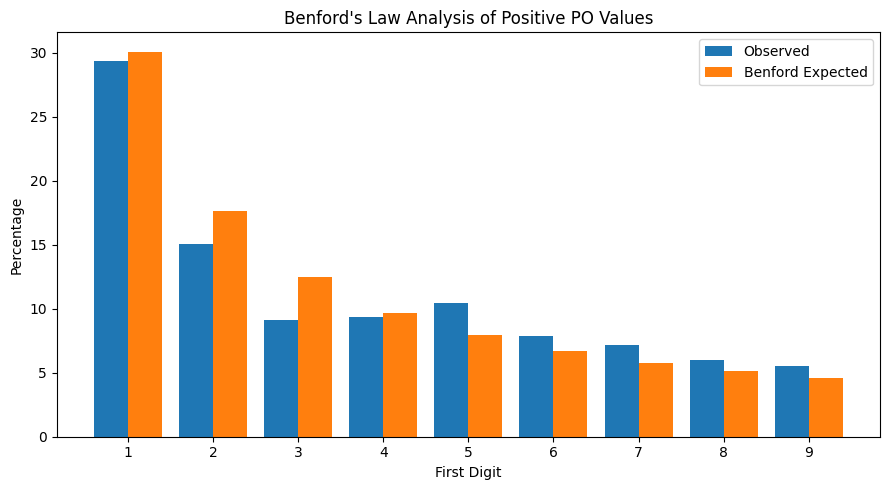

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    benford_results["Digit"] - 0.2,
    benford_results["Observed_Percentage"],
    width=0.4,
    label="Observed"
)

plt.bar(
    benford_results["Digit"] + 0.2,
    benford_results["Expected_Percentage"],
    width=0.4,
    label="Benford Expected"
)

plt.xlabel("First Digit")
plt.ylabel("Percentage")
plt.title("Benford's Law Analysis of Positive PO Values")
plt.xticks(digits)
plt.legend()
plt.tight_layout()
plt.show()

**Duplicate Invoice Detection**

In [ ]:
duplicate_invoice_data = forensic_invoice[
    [
        "Invoice_ID",
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount"
    ]
].copy()

# Keep only positive-value invoices
duplicate_invoice_data = duplicate_invoice_data[
    duplicate_invoice_data["Invoice_Amount"] > 0
].copy()

# Exclude unresolved supplier identity
duplicate_invoice_data = duplicate_invoice_data[
    duplicate_invoice_data["Supplier_ID"] != "VENDOR_0"
].copy()

# Duplicate criterion:
# Same identified supplier + invoice date + invoice amount
duplicate_group_counts = (
    duplicate_invoice_data
    .groupby(
        [
            "Supplier_ID",
            "Invoice_Date",
            "Invoice_Amount"
        ]
    )["Invoice_ID"]
    .nunique()
    .reset_index(name="Invoice_Count")
)

duplicate_groups = duplicate_group_counts[
    duplicate_group_counts["Invoice_Count"] > 1
].copy()

print("REFINED DUPLICATE INVOICE DETECTION")
print("-" * 70)

print("Positive invoices analysed:",
      len(duplicate_invoice_data))

print("Duplicate groups detected:",
      len(duplicate_groups))

print("Invoices involved in duplicate groups:",
      duplicate_groups["Invoice_Count"].sum())

display(
    duplicate_groups
    .sort_values(
        "Invoice_Count",
        ascending=False
    )
    .head(20)
)

REFINED DUPLICATE INVOICE DETECTION
----------------------------------------------------------------------
Positive invoices analysed: 182275
Duplicate groups detected: 495
Invoices involved in duplicate groups: 1024


,Supplier_ID,Invoice_Date,Invoice_Amount,Invoice_Count
28270,VENDOR_1018638,2015-03-14,50000.00,4
166182,VENDOR_4726,2014-07-09,20000.00,3
172763,VENDOR_56613,2013-09-27,1215.20,3
91240,VENDOR_17224,2014-09-14,9638.48,3
27676,VENDOR_1018638,2014-05-31,75000.00,3
27682,VENDOR_1018638,2014-06-03,45000.00,3
91211,VENDOR_17224,2014-08-29,7228.86,3
91204,VENDOR_17224,2014-08-25,7228.86,3
91183,VENDOR_17224,2014-08-15,12048.10,3
88030,VENDOR_1674160,2013-05-31,9279.50,3


In [ ]:
# REFINED DUPLICATE INVOICE TRANSACTIONS

duplicate_keys = duplicate_groups[
    [
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount"
    ]
]

duplicate_invoices = duplicate_invoice_data.merge(
    duplicate_keys,
    on=[
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount"
    ],
    how="inner"
)

duplicate_invoices = duplicate_invoices.sort_values(
    [
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount",
        "Invoice_ID"
    ]
)

print("REFINED DUPLICATE INVOICE TRANSACTIONS")
print("-" * 70)

print("Suspicious invoices:", len(duplicate_invoices))

print(
    "Unique duplicate groups:",
    duplicate_invoices[
        [
            "Supplier_ID",
            "Invoice_Date",
            "Invoice_Amount"
        ]
    ].drop_duplicates().shape[0]
)

display(duplicate_invoices.head(30))

REFINED DUPLICATE INVOICE TRANSACTIONS
----------------------------------------------------------------------
Suspicious invoices: 1024
Unique duplicate groups: 495


,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Invoice_Date,Invoice_Amount
629,INV_086172,PO_086171,EMP_00096,VENDOR_1000173,2013-06-29,71937.31
631,INV_086203,PO_086202,EMP_00121,VENDOR_1000173,2013-06-29,71937.31
630,INV_086177,PO_086176,EMP_00098,VENDOR_1000173,2013-07-03,71937.31
632,INV_086205,PO_086204,EMP_00113,VENDOR_1000173,2013-07-03,71937.31
628,INV_086164,PO_086163,EMP_00085,VENDOR_1000173,2013-07-11,71937.31
633,INV_086208,PO_086207,EMP_00094,VENDOR_1000173,2013-07-11,71937.31
969,INV_177007,PO_177006,EMP_00248,VENDOR_1000633,2012-07-09,33000.00
970,INV_177015,PO_177014,EMP_00249,VENDOR_1000633,2012-07-09,33000.00
973,INV_178402,PO_178401,EMP_00250,VENDOR_1000633,2013-07-19,49000.00
974,INV_178403,PO_178402,EMP_00250,VENDOR_1000633,2013-07-19,49000.00


In [ ]:
# REFINED DETECTOR vs GROUND TRUTH
duplicate_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "DUPLICATE_INVOICE"
].copy()

detected_duplicate_ids = set(
    duplicate_invoices["Invoice_ID"]
)

duplicate_ground_truth["Detected"] = (
    duplicate_ground_truth["Entity_ID"]
    .isin(detected_duplicate_ids)
)

print("REFINED DUPLICATE DETECTOR — GROUND-TRUTH EVALUATION")
print("-" * 70)

print(
    "Ground-truth duplicate cases:",
    len(duplicate_ground_truth)
)

print(
    "Ground-truth cases detected:",
    duplicate_ground_truth["Detected"].sum()
)

print(
    "Ground-truth cases missed:",
    (~duplicate_ground_truth["Detected"]).sum()
)

display(
    duplicate_ground_truth[
        [
            "Case_ID",
            "Entity_ID",
            "Detected"
        ]
    ]
)

duplicate_detection_rate = (
    duplicate_ground_truth["Detected"].mean()
)

print(
    "\nDuplicate detection rate:",
    round(duplicate_detection_rate * 100, 2),
    "%"
)

REFINED DUPLICATE DETECTOR — GROUND-TRUTH EVALUATION
----------------------------------------------------------------------
Ground-truth duplicate cases: 5
Ground-truth cases detected: 5
Ground-truth cases missed: 0


,Case_ID,Entity_ID,Detected
5,DI_01,INV_187081,True
6,DI_02,INV_187082,True
7,DI_03,INV_187083,True
8,DI_04,INV_187084,True
9,DI_05,INV_187085,True



Duplicate detection rate: 100.0 %


In [ ]:
# REFINED DUPLICATE EVIDENCE FLAG

duplicate_invoice_ids = set(
    duplicate_invoices["Invoice_ID"]
)

forensic_invoice["Duplicate_Invoice_Flag"] = (
    forensic_invoice["Invoice_ID"]
    .isin(duplicate_invoice_ids)
)

print("REFINED DUPLICATE EVIDENCE SUMMARY")
print("-" * 70)

print(
    "Invoices flagged as potential duplicates:",
    forensic_invoice["Duplicate_Invoice_Flag"].sum()
)

print(
    "Injected duplicate cases detected:",
    duplicate_ground_truth["Detected"].sum(),
    "/",
    len(duplicate_ground_truth)
)

REFINED DUPLICATE EVIDENCE SUMMARY
----------------------------------------------------------------------
Invoices flagged as potential duplicates: 1024
Injected duplicate cases detected: 5 / 5


**Statistical Outlier Analysis**

In [ ]:
positive_po_values = forensic_po.loc[
    forensic_po["PO_Value"] > 0,
    "PO_Value"
].dropna()

Q1 = positive_po_values.quantile(0.25)
Q3 = positive_po_values.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("STATISTICAL OUTLIER ANALYSIS — IQR METHOD")
print("-" * 70)

print("Positive POs analysed:", len(positive_po_values))
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))

STATISTICAL OUTLIER ANALYSIS — IQR METHOD
----------------------------------------------------------------------
Positive POs analysed: 185029
Q1: 4672.77
Q3: 31350.0
IQR: 26677.23
Lower bound: -35343.07
Upper bound: 71365.84


In [ ]:
# OUTLIER FLAGGING

forensic_po["Statistical_Outlier_Flag"] = (
    forensic_po["PO_Value"] > upper_bound
)

outlier_pos = forensic_po[
    forensic_po["Statistical_Outlier_Flag"]
].copy()

print("STATISTICAL OUTLIER RESULTS")
print("-" * 70)

print("Upper outlier threshold:",
      round(upper_bound, 2))

print("Outlier POs detected:",
      len(outlier_pos))

print(
    "Percentage of positive POs flagged:",
    round(
        len(outlier_pos) /
        len(positive_po_values) * 100,
        2
    ),
    "%"
)

display(
    outlier_pos[
        [
            "PO_ID",
            "PO_Number",
            "PO_Date",
            "Department_Name",
            "Supplier_ID",
            "Supplier_Name",
            "Employee_ID",
            "PO_Value"
        ]
    ]
    .sort_values("PO_Value", ascending=False)
    .head(20)
)

STATISTICAL OUTLIER RESULTS
----------------------------------------------------------------------
Upper outlier threshold: 71365.84
Outlier POs detected: 26778
Percentage of positive POs flagged: 14.47 %


,PO_ID,PO_Number,PO_Date,Department_Name,Supplier_ID,Supplier_Name,Employee_ID,PO_Value
6396,PO_006396,11-88134,2012-03-13,"Health Care Services, Department of",VENDOR_1275360,Delta Dental of California,EMP_00208,7.337038e+09
11114,PO_011114,12-89371,2013-08-30,"Health Care Services, Department of",VENDOR_1010119,County of Los Angeles,EMP_00207,3.010053e+09
11087,PO_011087,12-89334,2013-01-01,"Health Care Services, Department of",VENDOR_1029823,"Health Net Community Solutions, Inc.",EMP_00208,2.814351e+09
5583,PO_005583,11-10019,2013-05-16,"Public Health, Department of",VENDOR_1067047,Ramsell Public Health Rx,EMP_00262,2.750000e+09
160950,PO_160950,HSR13-57,2015-06-10,"High Speed Rail Authority, California",VENDOR_0,Unknown,EMP_00210,1.365336e+09
6304,PO_006304,11-73020-000,2012-04-01,"State Hospitals, Department of",VENDOR_1010119,County of Los Angeles,EMP_00287,9.987836e+08
132955,PO_132955,54758,2012-12-05,"Social Services, Department of",VENDOR_1094180,California Student Aid Commission,EMP_00283,8.037540e+08
161018,PO_161018,HSR14-66,2015-06-29,"High Speed Rail Authority, California",VENDOR_0,Unknown,EMP_00210,7.000000e+08
4019,PO_004019,09-86388,2013-02-26,"Health Care Services, Department of",VENDOR_1018339,Ca Dept of Developmental Services,EMP_00208,6.781447e+08
11096,PO_011096,12-89353,2013-09-05,"Health Care Services, Department of",VENDOR_1038758,County of Alameda,EMP_00208,6.191958e+08


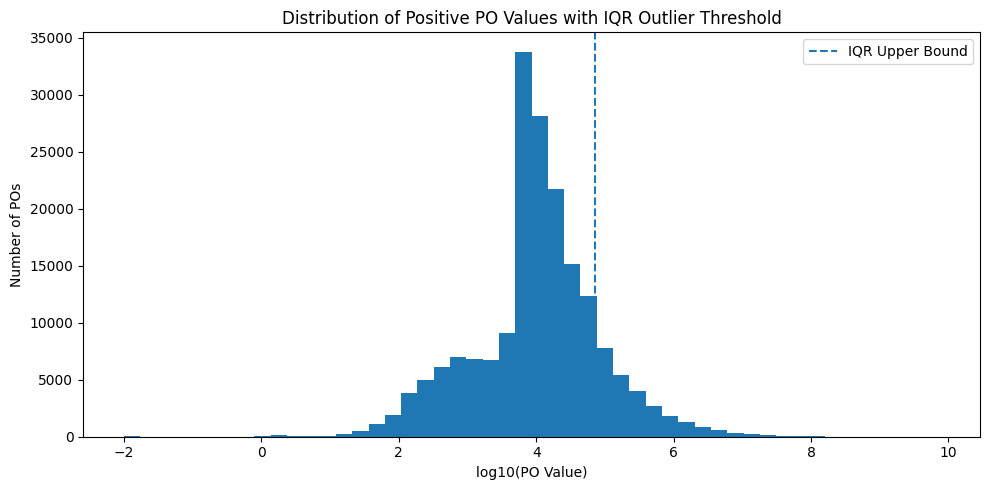

In [ ]:
# OUTLIER DISTRIBUTION

plt.figure(figsize=(10, 5))

plt.hist(
    np.log10(positive_po_values),
    bins=50
)

plt.axvline(
    np.log10(upper_bound),
    linestyle="--",
    label="IQR Upper Bound"
)

plt.xlabel("log10(PO Value)")
plt.ylabel("Number of POs")
plt.title("Distribution of Positive PO Values with IQR Outlier Threshold")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# OUTLIER SEVERITY

# Percentile rank among positive PO values
positive_po_rank = (
    forensic_po.loc[
        forensic_po["PO_Value"] > 0,
        "PO_Value"
    ]
    .rank(pct=True)
)

forensic_po.loc[
    positive_po_rank.index,
    "PO_Value_Percentile"
] = positive_po_rank

# Continuous severity based on distance above IQR threshold
forensic_po["Outlier_Excess_Ratio"] = np.where(
    forensic_po["PO_Value"] > upper_bound,
    (
        forensic_po["PO_Value"] - upper_bound
    ) / upper_bound,
    0
)

print("OUTLIER SEVERITY ANALYSIS")
print("-" * 70)

print("IQR upper threshold:",
      round(upper_bound, 2))

print(
    "Maximum PO percentile:",
    round(
        forensic_po["PO_Value_Percentile"].max() * 100,
        2
    ),
    "%"
)

print(
    "Maximum outlier excess ratio:",
    round(
        forensic_po["Outlier_Excess_Ratio"].max(),
        2
    )
)

print("\nMost extreme positive POs:")

display(
    forensic_po[
        forensic_po["PO_Value"] > 0
    ][
        [
            "PO_ID",
            "PO_Value",
            "PO_Value_Percentile",
            "Statistical_Outlier_Flag",
            "Outlier_Excess_Ratio"
        ]
    ]
    .sort_values(
        "PO_Value",
        ascending=False
    )
    .head(10)
)

OUTLIER SEVERITY ANALYSIS
----------------------------------------------------------------------
IQR upper threshold: 71365.84
Maximum PO percentile: 100.0 %
Maximum outlier excess ratio: 102807.82

Most extreme positive POs:


,PO_ID,PO_Value,PO_Value_Percentile,Statistical_Outlier_Flag,Outlier_Excess_Ratio
6396,PO_006396,7.337038e+09,1.000000,True,102807.816514
11114,PO_011114,3.010053e+09,0.999995,True,42176.778502
11087,PO_011087,2.814351e+09,0.999989,True,39434.545113
5583,PO_005583,2.750000e+09,0.999984,True,38532.839262
160950,PO_160950,1.365336e+09,0.999978,True,19130.503172
6304,PO_006304,9.987836e+08,0.999973,True,13994.260380
132955,PO_132955,8.037540e+08,0.999968,True,11261.446343
161018,PO_161018,7.000000e+08,0.999962,True,9807.613630
4019,PO_004019,6.781447e+08,0.999957,True,9501.371127
11096,PO_011096,6.191958e+08,0.999951,True,8675.360393


In [ ]:
# OUTLIER FORENSIC SUMMARY

outlier_percentage = (
    len(outlier_pos) /
    len(positive_po_values) * 100
)

print("FORENSIC INTERPRETATION — STATISTICAL OUTLIERS")
print("-" * 70)

print(
    f"The IQR method identified {len(outlier_pos):,} "
    f"POs ({outlier_percentage:.2f}% of positive POs) "
    f"above the upper threshold of {upper_bound:,.2f}."
)

print(
    "\nInterpretation:"
)

print(
    "These POs represent unusually high-value procurement "
    "transactions relative to the overall population."
)

print(
    "A statistical outlier is not automatically fraudulent. "
    "High values may be legitimate because of large contracts, "
    "specialized purchases, or operational requirements."
)

print(
    "Therefore, outlier status is treated as a screening "
    "signal and should be corroborated with independent "
    "behavioural, pricing, temporal, duplicate, or "
    "structuring evidence."
)

FORENSIC INTERPRETATION — STATISTICAL OUTLIERS
----------------------------------------------------------------------
The IQR method identified 26,778 POs (14.47% of positive POs) above the upper threshold of 71,365.85.

Interpretation:
These POs represent unusually high-value procurement transactions relative to the overall population.
A statistical outlier is not automatically fraudulent. High values may be legitimate because of large contracts, specialized purchases, or operational requirements.
Therefore, outlier status is treated as a screening signal and should be corroborated with independent behavioural, pricing, temporal, duplicate, or structuring evidence.


**Behavioural Analysis**

In [ ]:
# EMPLOYEE–VENDOR CONCENTRATION ANALYSIS

BEHAVIOR_MIN_OBSERVED = 5
BEHAVIOR_MIN_RATIO = 2
BEHAVIOR_MIN_EXCESS = 5

forensic_employee_vendor["Excess_Interaction"] = (
    forensic_employee_vendor["PO_Count"]
    - forensic_employee_vendor["Expected_Interaction"]
)

concentration_candidates = forensic_employee_vendor[
    (forensic_employee_vendor["PO_Count"] >= BEHAVIOR_MIN_OBSERVED)
    &
    (forensic_employee_vendor["Interaction_Ratio"] >= BEHAVIOR_MIN_RATIO)
    &
    (forensic_employee_vendor["Excess_Interaction"] >= BEHAVIOR_MIN_EXCESS)
].copy()

concentration_candidates = concentration_candidates.sort_values(
    [
        "Interaction_Ratio",
        "Excess_Interaction"
    ],
    ascending=False
)

print("EMPLOYEE–VENDOR CONCENTRATION ANALYSIS")
print("-" * 70)

print("Employee–Vendor relationships analysed:",
      len(forensic_employee_vendor))

print("Concentration candidates detected:",
      len(concentration_candidates))

print(
    "Detection criteria:"
)

print(
    f"Observed POs >= {BEHAVIOR_MIN_OBSERVED}"
)

print(
    f"Interaction ratio >= {BEHAVIOR_MIN_RATIO}"
)

print(
    f"Excess interactions >= {BEHAVIOR_MIN_EXCESS}"
)

display(
    concentration_candidates[
        [
            "Employee_ID",
            "Supplier_ID",
            "PO_Count",
            "Employee_Total_POs",
            "Supplier_Total_POs",
            "Expected_Interaction",
            "Interaction_Ratio",
            "Excess_Interaction",
            "Total_PO_Value"
        ]
    ].head(20)
)

EMPLOYEE–VENDOR CONCENTRATION ANALYSIS
----------------------------------------------------------------------
Employee–Vendor relationships analysed: 87888
Concentration candidates detected: 3704
Detection criteria:
Observed POs >= 5
Interaction ratio >= 2
Excess interactions >= 5


,Employee_ID,Supplier_ID,PO_Count,Employee_Total_POs,Supplier_Total_POs,Expected_Interaction,Interaction_Ratio,Excess_Interaction,Total_PO_Value
199,EMP_00005,VENDOR_1745431,6,57,7,0.002133,2813.233083,5.997867,60250.00
64163,EMP_00276,VENDOR_1049138,10,16,43,0.003678,2719.186047,9.996322,2160000.00
70192,EMP_00298,VENDOR_39872,7,63,11,0.003704,1889.696970,6.996296,9098.47
1481,EMP_00013,VENDOR_1021389,23,125,30,0.020045,1147.424000,22.979955,959830.00
60798,EMP_00261,VENDOR_1015178,6,165,6,0.005292,1133.818182,5.994708,84179.20
3553,EMP_00028,VENDOR_1032318,6,175,6,0.005613,1069.028571,5.994387,521200.00
3575,EMP_00028,VENDOR_1175840,6,175,6,0.005613,1069.028571,5.994387,91162.00
3640,EMP_00028,VENDOR_23908,6,175,6,0.005613,1069.028571,5.994387,140100.00
54909,EMP_00235,VENDOR_1054741,7,222,7,0.008307,842.702703,6.991693,365610.00
27510,EMP_00135,VENDOR_1032339,6,15,91,0.007296,822.329670,5.992704,208142.92


In [ ]:
# BEHAVIOURAL DETECTOR vs GROUND TRUTH

evc_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"]
    == "EMPLOYEE_VENDOR_CONCENTRATION"
].copy()

detected_evc_pairs = set(
    zip(
        concentration_candidates["Employee_ID"],
        concentration_candidates["Supplier_ID"]
    )
)

# Retrieve employee/supplier pair for each ground-truth PO
gt_po_lookup = fraud_po_table.set_index("PO_ID")

evc_ground_truth["Employee_ID"] = (
    evc_ground_truth["Entity_ID"]
    .map(gt_po_lookup["Employee_ID"])
)

evc_ground_truth["Supplier_ID"] = (
    evc_ground_truth["Entity_ID"]
    .map(gt_po_lookup["Supplier_ID"])
)

evc_ground_truth["Detected"] = [
    (emp, sup) in detected_evc_pairs
    for emp, sup in zip(
        evc_ground_truth["Employee_ID"],
        evc_ground_truth["Supplier_ID"]
    )
]

print("BEHAVIOURAL DETECTOR — GROUND-TRUTH EVALUATION")
print("-" * 70)

print(
    "Ground-truth concentration cases:",
    len(evc_ground_truth)
)

print(
    "Ground-truth cases detected:",
    evc_ground_truth["Detected"].sum()
)

print(
    "Ground-truth cases missed:",
    (~evc_ground_truth["Detected"]).sum()
)

display(
    evc_ground_truth[
        [
            "Case_ID",
            "Entity_ID",
            "Employee_ID",
            "Supplier_ID",
            "Detected"
        ]
    ]
)

evc_detection_rate = evc_ground_truth["Detected"].mean()

print(
    "\nBehavioural detection rate:",
    round(evc_detection_rate * 100, 2),
    "%"
)

BEHAVIOURAL DETECTOR — GROUND-TRUTH EVALUATION
----------------------------------------------------------------------
Ground-truth concentration cases: 5
Ground-truth cases detected: 5
Ground-truth cases missed: 0


,Case_ID,Entity_ID,Employee_ID,Supplier_ID,Detected
10,EVC_01,PO_151585,EMP_00026,VENDOR_1026449,True
11,EVC_02,PO_121669,EMP_00209,VENDOR_1017362,True
12,EVC_03,PO_152871,EMP_00140,VENDOR_1743275,True
13,EVC_04,PO_041547,EMP_00326,VENDOR_23836,True
14,EVC_05,PO_087425,EMP_00230,VENDOR_4508,True



Behavioural detection rate: 100.0 %


In [ ]:
# CONTROLLED CONCENTRATION CASE DETAILS

evc_case_details = evc_ground_truth[
    [
        "Case_ID",
        "Entity_ID",
        "Employee_ID",
        "Supplier_ID",
        "Detected"
    ]
].merge(
    forensic_employee_vendor[
        [
            "Employee_ID",
            "Supplier_ID",
            "PO_Count",
            "Employee_Total_POs",
            "Supplier_Total_POs",
            "Expected_Interaction",
            "Interaction_Ratio",
            "Excess_Interaction",
            "Total_PO_Value"
        ]
    ],
    on=["Employee_ID", "Supplier_ID"],
    how="left"
)

print("CONTROLLED EMPLOYEE–VENDOR CONCENTRATION CASES")
print("-" * 70)

display(
    evc_case_details.round(
        {
            "Expected_Interaction": 3,
            "Interaction_Ratio": 3,
            "Excess_Interaction": 3,
            "Total_PO_Value": 2
        }
    )
)

CONTROLLED EMPLOYEE–VENDOR CONCENTRATION CASES
----------------------------------------------------------------------


,Case_ID,Entity_ID,Employee_ID,Supplier_ID,Detected,PO_Count,Employee_Total_POs,Supplier_Total_POs,Expected_Interaction,Interaction_Ratio,Excess_Interaction,Total_PO_Value
0,EVC_01,PO_151585,EMP_00026,VENDOR_1026449,True,11,517,43,0.119,92.568,10.881,1417.38
1,EVC_02,PO_121669,EMP_00209,VENDOR_1017362,True,10,495,59,0.156,64.058,9.844,113095.22
2,EVC_03,PO_152871,EMP_00140,VENDOR_1743275,True,10,675,32,0.115,86.611,9.885,46176.39
3,EVC_04,PO_041547,EMP_00326,VENDOR_23836,True,11,709,347,1.315,8.365,9.685,324128.32
4,EVC_05,PO_087425,EMP_00230,VENDOR_4508,True,10,590,29,0.091,109.340,9.909,455037.68


In [ ]:
# BEHAVIOURAL EVIDENCE FLAG

concentration_pairs = set(
    zip(
        concentration_candidates["Employee_ID"],
        concentration_candidates["Supplier_ID"]
    )
)

forensic_po["Employee_Vendor_Concentration_Flag"] = [
    (emp, sup) in concentration_pairs
    for emp, sup in zip(
        forensic_po["Employee_ID"],
        forensic_po["Supplier_ID"]
    )
]

print("BEHAVIOURAL EVIDENCE SUMMARY")
print("-" * 70)

print(
    "POs associated with concentrated employee–vendor relationships:",
    forensic_po["Employee_Vendor_Concentration_Flag"].sum()
)

print(
    "Injected concentration cases detected:",
    evc_ground_truth["Detected"].sum(),
    "/",
    len(evc_ground_truth)
)

BEHAVIOURAL EVIDENCE SUMMARY
----------------------------------------------------------------------
POs associated with concentrated employee–vendor relationships: 57154
Injected concentration cases detected: 5 / 5


**Temporal Analysis**

In [ ]:
# Daily payment activity

temporal_daily = (
    fraud_payment_table
    .groupby("Payment_Date")
    .agg(
        Payment_Count=("Payment_ID", "count"),
        Total_Payment_Value=("Payment_Amount", "sum")
    )
    .reset_index()
    .sort_values("Payment_Date")
)

print("TEMPORAL PAYMENT ACTIVITY ANALYSIS")
print("-" * 70)

print("Unique payment dates:", len(temporal_daily))
print("Mean daily payments:", round(temporal_daily["Payment_Count"].mean(), 2))
print("Median daily payments:", round(temporal_daily["Payment_Count"].median(), 2))
print("Maximum daily payments:", temporal_daily["Payment_Count"].max())

display(
    temporal_daily
    .sort_values("Payment_Count", ascending=False)
    .head(15)
)

TEMPORAL PAYMENT ACTIVITY ANALYSIS
----------------------------------------------------------------------
Unique payment dates: 1377
Mean daily payments: 135.86
Median daily payments: 147.0
Maximum daily payments: 311


,Payment_Date,Payment_Count,Total_Payment_Value
566,2013-08-01,311,8.438704e+07
941,2014-08-11,303,3.248181e+07
933,2014-08-03,301,4.834577e+07
568,2013-08-03,299,7.147749e+07
946,2014-08-16,293,4.921645e+07
924,2014-07-25,288,1.137924e+08
560,2013-07-26,286,1.689332e+08
930,2014-07-31,284,2.676689e+07
938,2014-08-08,284,5.152599e+07
920,2014-07-21,280,5.822050e+07


In [ ]:
# Robust z-score for temporal anomalies

temporal_median = temporal_daily["Payment_Count"].median()

temporal_mad = (
    temporal_daily["Payment_Count"]
    .sub(temporal_median)
    .abs()
    .median()
)

# Robust z-score
temporal_daily["Robust_Z"] = (
    0.6745
    * (temporal_daily["Payment_Count"] - temporal_median)
    / temporal_mad
)

TEMPORAL_Z_THRESHOLD = 3

temporal_candidates = temporal_daily[
    temporal_daily["Robust_Z"] >= TEMPORAL_Z_THRESHOLD
].copy()

temporal_candidates = temporal_candidates.sort_values(
    "Robust_Z",
    ascending=False
)

print("ROBUST TEMPORAL ANOMALY DETECTION")
print("-" * 70)

print("Median daily payments:", temporal_median)
print("Median Absolute Deviation (MAD):", temporal_mad)
print("Robust z-score threshold:", TEMPORAL_Z_THRESHOLD)
print("Temporal anomaly dates detected:", len(temporal_candidates))

display(
    temporal_candidates[
        [
            "Payment_Date",
            "Payment_Count",
            "Total_Payment_Value",
            "Robust_Z"
        ]
    ].head(20).round({
        "Total_Payment_Value": 2,
        "Robust_Z": 3
    })
)

ROBUST TEMPORAL ANOMALY DETECTION
----------------------------------------------------------------------
Median daily payments: 147.0
Median Absolute Deviation (MAD): 24.0
Robust z-score threshold: 3
Temporal anomaly dates detected: 46


,Payment_Date,Payment_Count,Total_Payment_Value,Robust_Z
566,2013-08-01,311,8.438704e+07,4.609
941,2014-08-11,303,3.248181e+07,4.384
933,2014-08-03,301,4.834577e+07,4.328
568,2013-08-03,299,7.147749e+07,4.272
946,2014-08-16,293,4.921645e+07,4.103
924,2014-07-25,288,1.137924e+08,3.963
560,2013-07-26,286,1.689332e+08,3.906
930,2014-07-31,284,2.676689e+07,3.850
938,2014-08-08,284,5.152599e+07,3.850
920,2014-07-21,280,5.822050e+07,3.738


In [ ]:
# Temporal Detector — Ground-Truth Evaluation

ts_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "TEMPORAL_SPIKE"
].copy()

# Get the payment date for each injected payment
gt_payment_lookup = fraud_payment_table.set_index("Payment_ID")

ts_ground_truth["Payment_Date"] = (
    ts_ground_truth["Entity_ID"]
    .map(gt_payment_lookup["Payment_Date"])
)

# Dates identified by the temporal detector
detected_temporal_dates = set(
    temporal_candidates["Payment_Date"]
)

ts_ground_truth["Detected"] = (
    ts_ground_truth["Payment_Date"]
    .isin(detected_temporal_dates)
)

print("TEMPORAL DETECTOR — GROUND-TRUTH EVALUATION")
print("-" * 70)

print("Ground-truth temporal cases:", len(ts_ground_truth))
print(
    "Ground-truth cases detected:",
    ts_ground_truth["Detected"].sum()
)
print(
    "Ground-truth cases missed:",
    (~ts_ground_truth["Detected"]).sum()
)

display(
    ts_ground_truth[
        [
            "Case_ID",
            "Entity_ID",
            "Payment_Date",
            "Detected"
        ]
    ]
)

ts_detection_rate = ts_ground_truth["Detected"].mean()

print(
    "\nTemporal detection rate:",
    round(ts_detection_rate * 100, 2),
    "%"
)

TEMPORAL DETECTOR — GROUND-TRUTH EVALUATION
----------------------------------------------------------------------
Ground-truth temporal cases: 5
Ground-truth cases detected: 5
Ground-truth cases missed: 0


,Case_ID,Entity_ID,Payment_Date,Detected
20,TS_01,PAY_171331,2013-08-01,True
21,TS_02,PAY_091230,2013-08-01,True
22,TS_03,PAY_154021,2013-08-01,True
23,TS_04,PAY_105745,2013-08-01,True
24,TS_05,PAY_033320,2013-08-01,True



Temporal detection rate: 100.0 %


In [ ]:
# Temporal Evidence Flag

temporal_anomaly_dates = set(
    temporal_candidates["Payment_Date"]
)

fraud_payment_table["Temporal_Anomaly_Flag"] = (
    fraud_payment_table["Payment_Date"]
    .isin(temporal_anomaly_dates)
)

print("TEMPORAL EVIDENCE SUMMARY")
print("-" * 70)

print(
    "Payments occurring on anomalous dates:",
    fraud_payment_table["Temporal_Anomaly_Flag"].sum()
)

print(
    "Injected temporal cases detected:",
    ts_ground_truth["Detected"].sum(),
    "/",
    len(ts_ground_truth)
)

print(
    "Target date payment count:",
    temporal_daily.loc[
        temporal_daily["Payment_Date"] == pd.Timestamp("2013-08-01"),
        "Payment_Count"
    ].iloc[0]
)

TEMPORAL EVIDENCE SUMMARY
----------------------------------------------------------------------
Payments occurring on anomalous dates: 12477
Injected temporal cases detected: 5 / 5
Target date payment count: 311


**PO–Invoice Price Variance Analysis**

In [ ]:
# Calculate and detect significant variance

price_variance_df = forensic_invoice[
    forensic_invoice["PO_ID"].notna()
].copy()

# Bring PO value into invoice-level table
po_value_lookup = forensic_po.set_index("PO_ID")["PO_Value"]

price_variance_df["PO_Value"] = (
    price_variance_df["PO_ID"].map(po_value_lookup)
)

# Calculate percentage variance only for positive PO values
price_variance_df["Price_Variance_Pct"] = np.where(
    price_variance_df["PO_Value"] > 0,
    (
        (price_variance_df["Invoice_Amount"] -
         price_variance_df["PO_Value"])
        / price_variance_df["PO_Value"]
    ) * 100,
    np.nan
)

PRICE_VARIANCE_THRESHOLD = 25

price_variance_candidates = price_variance_df[
    price_variance_df["Price_Variance_Pct"].abs()
    >= PRICE_VARIANCE_THRESHOLD
].copy()

price_variance_candidates = price_variance_candidates.sort_values(
    "Price_Variance_Pct",
    key=lambda x: x.abs(),
    ascending=False
)

print("PO–INVOICE PRICE VARIANCE ANALYSIS")
print("-" * 70)

print(
    "Invoice records analysed:",
    len(price_variance_df)
)

print(
    "Positive-PO records:",
    (price_variance_df["PO_Value"] > 0).sum()
)

print(
    "Variance threshold:",
    f"±{PRICE_VARIANCE_THRESHOLD}%"
)

print(
    "Price variance candidates detected:",
    len(price_variance_candidates)
)

display(
    price_variance_candidates[
        [
            "Invoice_ID",
            "PO_ID",
            "Supplier_ID",
            "Invoice_Amount",
            "PO_Value",
            "Price_Variance_Pct"
        ]
    ].head(20).round({
        "Invoice_Amount": 2,
        "PO_Value": 2,
        "Price_Variance_Pct": 2
    })
)

PO–INVOICE PRICE VARIANCE ANALYSIS
----------------------------------------------------------------------
Invoice records analysed: 187085
Positive-PO records: 185034
Variance threshold: ±25%
Price variance candidates detected: 5


,Invoice_ID,PO_ID,Supplier_ID,Invoice_Amount,PO_Value,Price_Variance_Pct
16314,INV_016315,PO_016314,VENDOR_1755556,16000.00,10614.00,50.74
165915,INV_165916,PO_165915,VENDOR_0,15516.09,10852.96,42.97
121589,INV_121590,PO_121589,VENDOR_1413540,28000.00,19891.25,40.77
178016,INV_178017,PO_178016,VENDOR_1065902,308000.00,220310.00,39.80
11968,INV_011969,PO_011968,VENDOR_10742,1156.02,855.62,35.11


In [ ]:
# Price Variance Detector — Ground-Truth Evaluation

fm_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "PRICE_MANIPULATION"
].copy()

detected_price_invoices = set(
    price_variance_candidates["Invoice_ID"]
)

fm_ground_truth["Detected"] = (
    fm_ground_truth["Entity_ID"]
    .isin(detected_price_invoices)
)

print("PRICE VARIANCE DETECTOR — GROUND-TRUTH EVALUATION")
print("-" * 70)

print(
    "Ground-truth price manipulation cases:",
    len(fm_ground_truth)
)

print(
    "Ground-truth cases detected:",
    fm_ground_truth["Detected"].sum()
)

print(
    "Ground-truth cases missed:",
    (~fm_ground_truth["Detected"]).sum()
)

display(
    fm_ground_truth[
        [
            "Case_ID",
            "Entity_ID",
            "Detected"
        ]
    ]
)

fm_detection_rate = fm_ground_truth["Detected"].mean()

print(
    "\nPrice variance detection rate:",
    round(fm_detection_rate * 100, 2),
    "%"
)

PRICE VARIANCE DETECTOR — GROUND-TRUTH EVALUATION
----------------------------------------------------------------------
Ground-truth price manipulation cases: 5
Ground-truth cases detected: 5
Ground-truth cases missed: 0


,Case_ID,Entity_ID,Detected
0,FM_01,INV_165916,True
1,FM_02,INV_178017,True
2,FM_03,INV_121590,True
3,FM_04,INV_011969,True
4,FM_05,INV_016315,True



Price variance detection rate: 100.0 %


**Split-Purchase / Structuring Analysis**

In [ ]:
# Refined detection

SPLIT_THRESHOLD = 10000
SPLIT_WINDOW_DAYS = 30
SPLIT_MIN_GROUP_SIZE = 2

split_base = forensic_po[
    (forensic_po["PO_Value"] > 0) &
    (forensic_po["PO_Value"] < SPLIT_THRESHOLD) &
    (forensic_po["Supplier_ID"] != "VENDOR_0")
].copy()

split_base = split_base.sort_values(
    ["Employee_ID", "Supplier_ID", "PO_Date", "PO_ID"]
)

split_candidates = []

for (employee_id, supplier_id), group in split_base.groupby(
    ["Employee_ID", "Supplier_ID"]
):

    group = group.sort_values(
        ["PO_Date", "PO_ID"]
    ).reset_index(drop=True)

    for i in range(len(group)):

        start_date = group.loc[i, "PO_Date"]

        window_group = group[
            (group["PO_Date"] >= start_date) &
            (
                group["PO_Date"]
                <= start_date + pd.Timedelta(days=SPLIT_WINDOW_DAYS)
            )
        ].copy()

        if len(window_group) >= SPLIT_MIN_GROUP_SIZE:

            cumulative_value = window_group["PO_Value"].sum()

            if cumulative_value >= SPLIT_THRESHOLD:

                po_ids = tuple(
                    sorted(window_group["PO_ID"].tolist())
                )

                split_candidates.append({
                    "Employee_ID": employee_id,
                    "Supplier_ID": supplier_id,
                    "Start_Date": start_date,
                    "End_Date": window_group["PO_Date"].max(),
                    "PO_Count": len(window_group),
                    "Cumulative_PO_Value": cumulative_value,
                    "PO_IDs": po_ids
                })

split_candidates = pd.DataFrame(split_candidates)

if len(split_candidates) > 0:

    # Remove repeated representations of the same PO cluster
    split_candidates = (
        split_candidates
        .drop_duplicates(subset=["Employee_ID", "Supplier_ID", "PO_IDs"])
        .reset_index(drop=True)
    )

    split_candidates["Window_Days"] = (
        split_candidates["End_Date"]
        - split_candidates["Start_Date"]
    ).dt.days

    split_candidates = split_candidates.sort_values(
        ["Cumulative_PO_Value", "PO_Count"],
        ascending=[False, False]
    ).reset_index(drop=True)

print("REFINED SPLIT-PURCHASE / STRUCTURING ANALYSIS")
print("-" * 70)

print("Split threshold:", SPLIT_THRESHOLD)
print("Time window:", SPLIT_WINDOW_DAYS, "days")
print("Pursuant POs analysed:", len(split_base))
print(
    "Potential split-purchase groups detected:",
    len(split_candidates)
)

display(
    split_candidates[
        [
            "Employee_ID",
            "Supplier_ID",
            "Start_Date",
            "End_Date",
            "Window_Days",
            "PO_Count",
            "Cumulative_PO_Value",
            "PO_IDs"
        ]
    ].head(20)
)

REFINED SPLIT-PURCHASE / STRUCTURING ANALYSIS
----------------------------------------------------------------------
Split threshold: 10000
Time window: 30 days
Pursuant POs analysed: 90317
Potential split-purchase groups detected: 5469


,Employee_ID,Supplier_ID,Start_Date,End_Date,Window_Days,PO_Count,Cumulative_PO_Value,PO_IDs
0,EMP_00241,VENDOR_17224,2013-03-15,2013-03-22,7,10,69644.40,"(PO_183398, PO_183400, PO_183407, PO_183408, P..."
1,EMP_00241,VENDOR_17224,2013-03-18,2013-04-17,30,10,69644.40,"(PO_183400, PO_183407, PO_183408, PO_183410, P..."
2,EMP_00149,VENDOR_17224,2013-06-28,2013-06-28,0,8,66839.65,"(PO_041484, PO_041485, PO_041503, PO_041505, P..."
3,EMP_00241,VENDOR_17224,2013-03-19,2013-04-17,29,8,56075.52,"(PO_183407, PO_183408, PO_183412, PO_183413, P..."
4,EMP_00281,VENDOR_1755386,2015-04-17,2015-04-20,3,8,55663.51,"(PO_064423, PO_064425, PO_064428, PO_064432, P..."
5,EMP_00211,VENDOR_17224,2013-12-11,2013-12-17,6,6,55033.02,"(PO_002928, PO_002931, PO_002932, PO_002933, P..."
6,EMP_00214,VENDOR_17224,2012-12-20,2013-01-07,18,6,55033.02,"(PO_002867, PO_002872, PO_002875, PO_002878, P..."
7,EMP_00282,VENDOR_1755386,2015-04-17,2015-04-24,7,7,51638.20,"(PO_064429, PO_064441, PO_064444, PO_064446, P..."
8,EMP_00142,VENDOR_1013556,2012-12-20,2013-01-11,22,5,47475.00,"(PO_163484, PO_163490, PO_163493, PO_163494, P..."
9,EMP_00211,VENDOR_1017088,2013-03-05,2013-03-20,15,6,46320.00,"(PO_001132, PO_043405, PO_044036, PO_061353, P..."


In [ ]:
# Split-Purchase Detector — Ground-Truth Evaluation

sp_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "SPLIT_PURCHASE"
].copy()

# Convert detected PO groups into sets for comparison
detected_split_sets = set(
    tuple(sorted(po_ids))
    for po_ids in split_candidates["PO_IDs"]
)

# Retrieve the controlled PO group for each ground-truth case
sp_case_details = []

for _, row in sp_ground_truth.iterrows():

    case_po = row["Entity_ID"]

    # Find the complete controlled group from the description
    gt_description = row["Description"]

    sp_case_details.append({
        "Case_ID": row["Case_ID"],
        "Entity_ID": case_po,
        "Description": gt_description
    })

sp_case_details = pd.DataFrame(sp_case_details)

print("SPLIT-PURCHASE DETECTOR — GROUND-TRUTH EVALUATION")
print("-" * 70)

print(
    "Ground-truth split-purchase cases:",
    len(sp_ground_truth)
)

display(
    sp_case_details
)

SPLIT-PURCHASE DETECTOR — GROUND-TRUTH EVALUATION
----------------------------------------------------------------------
Ground-truth split-purchase cases: 5


,Case_ID,Entity_ID,Description
0,SP_01,PO_006003,Three POs for employee EMP_00231 and supplier ...
1,SP_02,PO_053179,Three POs for employee EMP_00197 and supplier ...
2,SP_03,PO_101033,Three POs for employee EMP_00107 and supplier ...
3,SP_04,PO_178887,Three POs for employee EMP_00246 and supplier ...
4,SP_05,PO_182442,Three POs for employee EMP_00282 and supplier ...


In [ ]:
# Split-Purchase Detector — Actual Ground-Truth Check

print("SPLIT-PURCHASE DETECTOR — ACTUAL GROUND-TRUTH CHECK")
print("-" * 70)

# Controlled split-purchase groups
controlled_split_groups = {
    "SP_01": ["PO_006003", "PO_007479", "PO_008175"],
    "SP_02": ["PO_053179", "PO_053268", "PO_053290"],
    "SP_03": ["PO_101033", "PO_101897", "PO_103012"],
    "SP_04": ["PO_178887", "PO_178390", "PO_178392"],
    "SP_05": ["PO_182442", "PO_022793", "PO_182451"]
}

split_evaluation = []

# Convert detected groups into sets
detected_split_sets = [
    set(po_ids)
    for po_ids in split_candidates["PO_IDs"]
]

for case_id, controlled_pos in controlled_split_groups.items():

    controlled_set = set(controlled_pos)

    # Check whether all controlled POs occur together
    detected = False
    matched_group = None

    for detected_set in detected_split_sets:

        if controlled_set.issubset(detected_set):
            detected = True
            matched_group = tuple(sorted(detected_set))
            break

    split_evaluation.append({
        "Case_ID": case_id,
        "Controlled_PO_Count": len(controlled_set),
        "Detected": detected,
        "Matched_Detected_Group": matched_group
    })

split_evaluation = pd.DataFrame(split_evaluation)

display(split_evaluation)

detected_count = split_evaluation["Detected"].sum()
total_cases = len(split_evaluation)
detection_rate = (detected_count / total_cases) * 100

print("\nGround-truth cases detected:", detected_count, "/", total_cases)
print("Detection rate:", round(detection_rate, 2), "%")

if detected_count == total_cases:
    print("PASS — All controlled split-purchase cases were detected.")
else:
    print("WARNING — Some controlled split-purchase cases were missed.")

SPLIT-PURCHASE DETECTOR — ACTUAL GROUND-TRUTH CHECK
----------------------------------------------------------------------


,Case_ID,Controlled_PO_Count,Detected,Matched_Detected_Group
0,SP_01,3,True,"(PO_006003, PO_007479, PO_008175)"
1,SP_02,3,True,"(PO_053179, PO_053268, PO_053290)"
2,SP_03,3,True,"(PO_101033, PO_101897, PO_103012)"
3,SP_04,3,True,"(PO_178390, PO_178392, PO_178456, PO_178887)"
4,SP_05,3,True,"(PO_022793, PO_182442, PO_182451)"



Ground-truth cases detected: 5 / 5
Detection rate: 100.0 %
PASS — All controlled split-purchase cases were detected.


**Round-Number / Structuring Analysis**

In [ ]:
print("ROUND-NUMBER / STRUCTURING ANALYSIS")
print("-" * 70)

# Positive invoice amounts only
round_analysis = forensic_invoice[
    forensic_invoice["Invoice_Amount"] > 0
].copy()

# Detect exact monetary multiples
round_analysis["Round_100_Flag"] = (
    np.isclose(
        round_analysis["Invoice_Amount"] % 100,
        0,
        atol=0.01
    )
)

round_analysis["Round_1000_Flag"] = (
    np.isclose(
        round_analysis["Invoice_Amount"] % 1000,
        0,
        atol=0.01
    )
)

round_analysis["Round_10000_Flag"] = (
    np.isclose(
        round_analysis["Invoice_Amount"] % 10000,
        0,
        atol=0.01
    )
)

# Summary
total_positive_invoices = len(round_analysis)

round_100_count = round_analysis["Round_100_Flag"].sum()
round_1000_count = round_analysis["Round_1000_Flag"].sum()
round_10000_count = round_analysis["Round_10000_Flag"].sum()

print("Positive invoices analyzed:", total_positive_invoices)
print("Exact $100 multiples:", round_100_count)
print("Exact $1,000 multiples:", round_1000_count)
print("Exact $10,000 multiples:", round_10000_count)

print("\nPercentages:")
print(
    "Exact $100 multiples:",
    round(round_100_count / total_positive_invoices * 100, 3), "%"
)
print(
    "Exact $1,000 multiples:",
    round(round_1000_count / total_positive_invoices * 100, 3), "%"
)
print(
    "Exact $10,000 multiples:",
    round(round_10000_count / total_positive_invoices * 100, 3), "%"
)

# Store the strongest round-number indicator
forensic_invoice["Round_Number_Flag"] = (
    forensic_invoice["Invoice_Amount"].isin(
        round_analysis.loc[
            round_analysis["Round_1000_Flag"],
            "Invoice_Amount"
        ]
    )
)

print("\nRound-number analysis completed.")

ROUND-NUMBER / STRUCTURING ANALYSIS
----------------------------------------------------------------------
Positive invoices analyzed: 185034
Exact $100 multiples: 30194
Exact $1,000 multiples: 19791
Exact $10,000 multiples: 9498

Percentages:
Exact $100 multiples: 16.318 %
Exact $1,000 multiples: 10.696 %
Exact $10,000 multiples: 5.133 %

Round-number analysis completed.


In [ ]:
# Round-Number Analysis — Ground-Truth Validation

print("ROUND-NUMBER ANALYSIS — GROUND-TRUTH VALIDATION")
print("-" * 70)

rn_ground_truth = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "ROUND_NUMBER"
].copy()

rn_evaluation = []

for _, row in rn_ground_truth.iterrows():

    invoice_id = row["Entity_ID"]

    # Locate the injected invoice
    match = forensic_invoice[
        forensic_invoice["Invoice_ID"] == invoice_id
    ]

    if len(match) == 0:
        detected = False
        amount = np.nan
        round_1000 = False

    else:
        amount = match.iloc[0]["Invoice_Amount"]
        round_1000 = bool(match.iloc[0]["Round_Number_Flag"])
        detected = round_1000

    rn_evaluation.append({
        "Case_ID": row["Case_ID"],
        "Invoice_ID": invoice_id,
        "Invoice_Amount": amount,
        "Round_1000_Flag": round_1000,
        "Detected": detected
    })

rn_evaluation = pd.DataFrame(rn_evaluation)

display(rn_evaluation)

detected_count = rn_evaluation["Detected"].sum()
total_cases = len(rn_evaluation)
detection_rate = detected_count / total_cases * 100

print("\nGround-truth cases detected:", detected_count, "/", total_cases)
print("Detection rate:", round(detection_rate, 2), "%")

if detected_count == total_cases:
    print("PASS — All controlled round-number cases were detected.")
else:
    print("WARNING — Some controlled round-number cases were missed.")

ROUND-NUMBER ANALYSIS — GROUND-TRUTH VALIDATION
----------------------------------------------------------------------


,Case_ID,Invoice_ID,Invoice_Amount,Round_1000_Flag,Detected
0,RN_01,INV_016315,16000.0,True,True
1,RN_02,INV_121590,28000.0,True,True
2,RN_03,INV_178017,308000.0,True,True
3,RN_04,INV_123941,40000.0,True,True
4,RN_05,INV_109970,5000.0,True,True



Ground-truth cases detected: 5 / 5
Detection rate: 100.0 %
PASS — All controlled round-number cases were detected.


# **Step 10 — Knowledge Graph Construction**

**Prepare Knowledge Graph Entities**

In [ ]:
print("KNOWLEDGE GRAPH — ENTITY / NODE PREPARATION")
print("-" * 70)

# Employee nodes

employee_nodes = employee_table[
    ["Employee_ID", "Department_ID"]
].drop_duplicates().copy()

employee_nodes["Node_Type"] = "Employee"

# Supplier nodes

supplier_nodes = clean_df[
    ["Supplier_ID", "Supplier Code", "Supplier Name"]
].drop_duplicates(subset=["Supplier_ID"]).copy()

supplier_nodes["Node_Type"] = "Supplier"

# Purchase Order nodes

po_nodes = fraud_po_table[
    ["PO_ID", "Supplier_ID", "Employee_ID", "PO_Value", "PO_Date"]
].copy()

po_nodes["Node_Type"] = "Purchase_Order"

# Invoice nodes

invoice_nodes = fraud_invoice_table[
    ["Invoice_ID", "PO_ID", "Supplier_ID", "Employee_ID",
     "Invoice_Date", "Invoice_Amount"]
].copy()

invoice_nodes["Node_Type"] = "Invoice"

# Payment nodes

payment_nodes = fraud_payment_table[
    ["Payment_ID", "Invoice_ID", "PO_ID", "Supplier_ID",
     "Employee_ID", "Payment_Date", "Payment_Amount"]
].copy()

payment_nodes["Node_Type"] = "Payment"

# Display node counts

node_summary = pd.DataFrame({
    "Node_Type": [
        "Employee",
        "Supplier",
        "Purchase_Order",
        "Invoice",
        "Payment"
    ],
    "Node_Count": [
        employee_nodes["Employee_ID"].nunique(),
        supplier_nodes["Supplier_ID"].nunique(),
        po_nodes["PO_ID"].nunique(),
        invoice_nodes["Invoice_ID"].nunique(),
        payment_nodes["Payment_ID"].nunique()
    ]
})

display(node_summary)

print("\nTotal unique nodes:")

total_nodes = (
    node_summary["Node_Count"].sum()
)

print(total_nodes)

KNOWLEDGE GRAPH — ENTITY / NODE PREPARATION
----------------------------------------------------------------------


,Node_Type,Node_Count
0,Employee,350
1,Supplier,24260
2,Purchase_Order,187080
3,Invoice,187085
4,Payment,187080



Total unique nodes:
585855


**Build Knowledge Graph Relationships**

In [ ]:
import networkx as nx

print("KNOWLEDGE GRAPH — CONSTRUCTION")
print("-" * 70)

# Create directed graph
G = nx.DiGraph()

# 1. Add Employee nodes

for _, row in employee_nodes.iterrows():

    G.add_node(
        row["Employee_ID"],
        node_type="Employee",
        department_id=row["Department_ID"]
    )

# 2. Add Supplier nodes

for _, row in supplier_nodes.iterrows():

    G.add_node(
        row["Supplier_ID"],
        node_type="Supplier",
        supplier_code=row["Supplier Code"],
        supplier_name=row["Supplier Name"]
    )

# 3. Add Purchase Order nodes

for _, row in po_nodes.iterrows():

    G.add_node(
        row["PO_ID"],
        node_type="Purchase_Order",
        po_value=float(row["PO_Value"]),
        po_date=row["PO_Date"]
    )

# 4. Add Invoice nodes

for _, row in invoice_nodes.iterrows():

    G.add_node(
        row["Invoice_ID"],
        node_type="Invoice",
        invoice_amount=float(row["Invoice_Amount"]),
        invoice_date=row["Invoice_Date"]
    )

# 5. Add Payment nodes

for _, row in payment_nodes.iterrows():

    G.add_node(
        row["Payment_ID"],
        node_type="Payment",
        payment_amount=float(row["Payment_Amount"]),
        payment_date=row["Payment_Date"]
    )


# 6. Employee → Purchase Order

for _, row in po_nodes.iterrows():

    G.add_edge(
        row["Employee_ID"],
        row["PO_ID"],
        relationship="CREATED"
    )

# 7. Purchase Order → Supplier

for _, row in po_nodes.iterrows():

    G.add_edge(
        row["PO_ID"],
        row["Supplier_ID"],
        relationship="SUPPLIED_BY"
    )

# 8. Purchase Order → Invoice

for _, row in invoice_nodes.iterrows():

    G.add_edge(
        row["PO_ID"],
        row["Invoice_ID"],
        relationship="HAS_INVOICE"
    )

# 9. Invoice → Payment

for _, row in payment_nodes.iterrows():

    G.add_edge(
        row["Invoice_ID"],
        row["Payment_ID"],
        relationship="PAID_BY"
    )

# 10. Employee → Supplier

employee_supplier_pairs = po_nodes[
    ["Employee_ID", "Supplier_ID"]
].drop_duplicates()

for _, row in employee_supplier_pairs.iterrows():

    G.add_edge(
        row["Employee_ID"],
        row["Supplier_ID"],
        relationship="INTERACTS_WITH"
    )


# Graph summary

print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

print("\nNodes by type:")

node_type_counts = pd.Series(
    nx.get_node_attributes(G, "node_type")
).value_counts()

display(
    node_type_counts.rename_axis("Node_Type")
    .reset_index(name="Node_Count")
)

print("\nRelationships:")

relationship_counts = pd.Series(
    nx.get_edge_attributes(G, "relationship")
).value_counts()

display(
    relationship_counts.rename_axis("Relationship")
    .reset_index(name="Edge_Count")
)

KNOWLEDGE GRAPH — CONSTRUCTION
----------------------------------------------------------------------
Total nodes: 585855
Total edges: 836213

Nodes by type:


,Node_Type,Node_Count
0,Invoice,187085
1,Payment,187080
2,Purchase_Order,187080
3,Supplier,24260
4,Employee,350



Relationships:


,Relationship,Edge_Count
0,HAS_INVOICE,187085
1,CREATED,187080
2,SUPPLIED_BY,187080
3,PAID_BY,187080
4,INTERACTS_WITH,87888


**Add Forensic Attributes**

In [ ]:
print("KNOWLEDGE GRAPH — ADDING FORENSIC ATTRIBUTES")
print("-" * 70)

po_forensic_attributes = forensic_po.set_index("PO_ID")

po_attribute_columns = [
    "Statistical_Outlier_Flag",
    "Employee_Vendor_Concentration_Flag",
    "PO_Value_Percentile",
    "Outlier_Excess_Ratio"
]

for po_id, row in po_forensic_attributes.iterrows():

    if po_id in G.nodes:

        for column in po_attribute_columns:

            G.nodes[po_id][column] = row[column]


# 2. Add forensic attributes to Invoice nodes

invoice_forensic_attributes = forensic_invoice.set_index("Invoice_ID")

invoice_attribute_columns = [
    "Duplicate_Invoice_Flag",
    "Round_Number_Flag",
    "Price_Variance_Pct",
    "Invoice_Payment_Amount_Match",
    "Payment_Lag_Days"
]

for invoice_id, row in invoice_forensic_attributes.iterrows():

    if invoice_id in G.nodes:

        for column in invoice_attribute_columns:

            G.nodes[invoice_id][column] = row[column]


# 3. Add temporal anomaly attribute to Payment nodes

payment_temporal_lookup = (
    fraud_payment_table[
        ["Payment_ID", "Temporal_Anomaly_Flag"]
    ]
    .drop_duplicates("Payment_ID")
    .set_index("Payment_ID")
)

for payment_id, row in payment_temporal_lookup.iterrows():

    if payment_id in G.nodes:

        G.nodes[payment_id]["Temporal_Anomaly_Flag"] = (
            bool(row["Temporal_Anomaly_Flag"])
        )


# 4. Count forensic flags

print("Forensic attributes added successfully.")

print("\nPurchase Order forensic flags:")

po_flag_summary = pd.DataFrame({
    "Flag": [
        "Statistical Outlier",
        "Employee-Vendor Concentration"
    ],
    "Flagged_Count": [
        forensic_po["Statistical_Outlier_Flag"].sum(),
        forensic_po["Employee_Vendor_Concentration_Flag"].sum()
    ]
})

display(po_flag_summary)


print("\nInvoice forensic flags:")

invoice_flag_summary = pd.DataFrame({
    "Flag": [
        "Duplicate Invoice",
        "Round Number"
    ],
    "Flagged_Count": [
        forensic_invoice["Duplicate_Invoice_Flag"].sum(),
        forensic_invoice["Round_Number_Flag"].sum()
    ]
})

display(invoice_flag_summary)


print("\nPayment forensic flags:")

payment_flag_count = fraud_payment_table[
    "Temporal_Anomaly_Flag"
].sum()

print(
    "Temporal Anomaly:",
    payment_flag_count
)


# 5. Verify attribute attachment

po_attributes_attached = sum(
    "Statistical_Outlier_Flag" in G.nodes[po_id]
    for po_id in po_nodes["PO_ID"]
)

invoice_attributes_attached = sum(
    "Duplicate_Invoice_Flag" in G.nodes[invoice_id]
    for invoice_id in invoice_nodes["Invoice_ID"]
)

payment_attributes_attached = sum(
    "Temporal_Anomaly_Flag" in G.nodes[payment_id]
    for payment_id in payment_nodes["Payment_ID"]
)

print("\nAttribute attachment validation:")
print(
    "PO nodes with forensic attributes:",
    po_attributes_attached,
    "/",
    len(po_nodes)
)

print(
    "Invoice nodes with forensic attributes:",
    invoice_attributes_attached,
    "/",
    len(invoice_nodes)
)

print(
    "Payment nodes with temporal attributes:",
    payment_attributes_attached,
    "/",
    len(payment_nodes)
)

KNOWLEDGE GRAPH — ADDING FORENSIC ATTRIBUTES
----------------------------------------------------------------------
Forensic attributes added successfully.

Purchase Order forensic flags:


,Flag,Flagged_Count
0,Statistical Outlier,26778
1,Employee-Vendor Concentration,57154



Invoice forensic flags:


,Flag,Flagged_Count
0,Duplicate Invoice,1024
1,Round Number,19791



Payment forensic flags:
Temporal Anomaly: 12477

Attribute attachment validation:
PO nodes with forensic attributes: 187080 / 187080
Invoice nodes with forensic attributes: 187085 / 187085
Payment nodes with temporal attributes: 187080 / 187080


**Integrity Validation**

In [ ]:
print("KNOWLEDGE GRAPH — INTEGRITY VALIDATION")
print("-" * 70)

# 1. Purchase Orders with CREATED relationship

po_created_count = sum(
    1
    for po_id in po_nodes["PO_ID"]
    if G.in_degree(po_id) >= 1
    and any(
        G.edges[source, po_id]["relationship"] == "CREATED"
        for source in G.predecessors(po_id)
    )
)


# 2. Purchase Orders with SUPPLIED_BY relationship

po_supplier_count = sum(
    1
    for po_id in po_nodes["PO_ID"]
    if any(
        G.edges[po_id, target]["relationship"] == "SUPPLIED_BY"
        for target in G.successors(po_id)
    )
)


# 3. Invoices with HAS_INVOICE relationship from PO

invoice_po_count = sum(
    1
    for invoice_id in invoice_nodes["Invoice_ID"]
    if any(
        G.edges[source, invoice_id]["relationship"] == "HAS_INVOICE"
        for source in G.predecessors(invoice_id)
    )
)


# 4. Payments with PAID_BY relationship from Invoice

payment_invoice_count = sum(
    1
    for payment_id in payment_nodes["Payment_ID"]
    if any(
        G.edges[source, payment_id]["relationship"] == "PAID_BY"
        for source in G.predecessors(payment_id)
    )
)

# 5. Employee-Supplier interactions

interaction_count = len(employee_supplier_pairs)

# 6. Identify orphan nodes

orphan_nodes = [
    node
    for node in G.nodes
    if G.degree(node) == 0
]

# Validation summary

integrity_summary = pd.DataFrame({
    "Validation": [
        "POs connected to Employee",
        "POs connected to Supplier",
        "Invoices connected to PO",
        "Payments connected to Invoice",
        "Employee-Supplier relationships",
        "Orphan nodes"
    ],
    "Observed": [
        po_created_count,
        po_supplier_count,
        invoice_po_count,
        payment_invoice_count,
        interaction_count,
        len(orphan_nodes)
    ],
    "Expected": [
        po_nodes["PO_ID"].nunique(),
        po_nodes["PO_ID"].nunique(),
        invoice_nodes["Invoice_ID"].nunique(),
        payment_nodes["Payment_ID"].nunique(),
        len(employee_supplier_pairs),
        0
    ]
})

display(integrity_summary)

# Overall validation

integrity_pass = (
    po_created_count == po_nodes["PO_ID"].nunique()
    and
    po_supplier_count == po_nodes["PO_ID"].nunique()
    and
    invoice_po_count == invoice_nodes["Invoice_ID"].nunique()
    and
    payment_invoice_count == payment_nodes["Payment_ID"].nunique()
    and
    interaction_count == len(employee_supplier_pairs)
    and
    len(orphan_nodes) == 0
)

print("\nKnowledge Graph Integrity:", integrity_pass)

if integrity_pass:
    print("PASS — All required entity relationships are intact.")
else:
    print("WARNING — Graph integrity issue detected.")

KNOWLEDGE GRAPH — INTEGRITY VALIDATION
----------------------------------------------------------------------


,Validation,Observed,Expected
0,POs connected to Employee,187080,187080
1,POs connected to Supplier,187080,187080
2,Invoices connected to PO,187085,187085
3,Payments connected to Invoice,187080,187080
4,Employee-Supplier relationships,87888,87888
5,Orphan nodes,296,0



Knowledge Graph Integrity: False
WARNING — Graph integrity issue detected.


**Integrity Validation**

In [ ]:
print("KNOWLEDGE GRAPH — FINAL INTEGRITY VALIDATION")
print("-" * 70)

# 1. Expected node counts

expected_employee_nodes = len(employee_nodes)
expected_supplier_nodes = len(supplier_nodes)
expected_po_nodes = len(po_nodes)
expected_invoice_nodes = len(invoice_nodes)
expected_payment_nodes = len(payment_nodes)

actual_employee_nodes = sum(
    1 for n, d in G.nodes(data=True)
    if d.get("node_type") == "Employee"
)

actual_supplier_nodes = sum(
    1 for n, d in G.nodes(data=True)
    if d.get("node_type") == "Supplier"
)

actual_po_nodes = sum(
    1 for n, d in G.nodes(data=True)
    if d.get("node_type") == "Purchase_Order"
)

actual_invoice_nodes = sum(
    1 for n, d in G.nodes(data=True)
    if d.get("node_type") == "Invoice"
)

actual_payment_nodes = sum(
    1 for n, d in G.nodes(data=True)
    if d.get("node_type") == "Payment"
)

# 2. Relationship integrity

po_employee_connected = sum(
    1 for po in po_nodes["PO_ID"]
    if G.in_degree(po) > 0
)

po_supplier_connected = sum(
    1 for po in po_nodes["PO_ID"]
    if G.out_degree(po) > 0
)

invoice_po_connected = sum(
    1 for inv in invoice_nodes["Invoice_ID"]
    if G.in_degree(inv) > 0
)

payment_invoice_connected = sum(
    1 for pay in payment_nodes["Payment_ID"]
    if G.in_degree(pay) > 0
)

# 3. Supplier orphan analysis

supplier_orphans = [
    node for node in G.nodes
    if G.nodes[node].get("node_type") == "Supplier"
    and G.degree(node) == 0
]

supplier_orphan_count = len(supplier_orphans)

# 4. Display results

print("\nNODE COUNTS")
print("-" * 70)

print(
    f"Employees       : {actual_employee_nodes:,} / "
    f"{expected_employee_nodes:,}"
)

print(
    f"Suppliers       : {actual_supplier_nodes:,} / "
    f"{expected_supplier_nodes:,}"
)

print(
    f"Purchase Orders : {actual_po_nodes:,} / "
    f"{expected_po_nodes:,}"
)

print(
    f"Invoices        : {actual_invoice_nodes:,} / "
    f"{expected_invoice_nodes:,}"
)

print(
    f"Payments        : {actual_payment_nodes:,} / "
    f"{expected_payment_nodes:,}"
)

print("\nRELATIONSHIP CONNECTIVITY")
print("-" * 70)

print(
    f"PO → Employee connected : "
    f"{po_employee_connected:,} / {expected_po_nodes:,}"
)

print(
    f"PO → Supplier connected : "
    f"{po_supplier_connected:,} / {expected_po_nodes:,}"
)

print(
    f"Invoice → PO connected  : "
    f"{invoice_po_connected:,} / {expected_invoice_nodes:,}"
)

print(
    f"Payment → Invoice       : "
    f"{payment_invoice_connected:,} / {expected_payment_nodes:,}"
)

print("\nSUPPLIER ORPHAN ANALYSIS")
print("-" * 70)

print(
    "Supplier nodes without transaction edges:",
    supplier_orphan_count
)

print(
    "\nInterpretation: These supplier nodes are valid resolved supplier "
    "entities but have no transaction relationship in the analysed "
    "procurement graph."
)

# 5. Final integrity checks

integrity_checks = {
    "Employee node count":
        actual_employee_nodes == expected_employee_nodes,

    "Supplier node count":
        actual_supplier_nodes == expected_supplier_nodes,

    "PO node count":
        actual_po_nodes == expected_po_nodes,

    "Invoice node count":
        actual_invoice_nodes == expected_invoice_nodes,

    "Payment node count":
        actual_payment_nodes == expected_payment_nodes,

    "PO-Employee connectivity":
        po_employee_connected == expected_po_nodes,

    "PO-Supplier connectivity":
        po_supplier_connected == expected_po_nodes,

    "Invoice-PO connectivity":
        invoice_po_connected == expected_invoice_nodes,

    "Payment-Invoice connectivity":
        payment_invoice_connected == expected_payment_nodes
}

overall_integrity = all(integrity_checks.values())

print("\nFINAL GRAPH INTEGRITY")
print("-" * 70)

for check, result in integrity_checks.items():
    print(
        f"{check:<30}: "
        f"{'PASS' if result else 'FAIL'}"
    )

print("\nOverall Graph Integrity:", overall_integrity)

KNOWLEDGE GRAPH — FINAL INTEGRITY VALIDATION
----------------------------------------------------------------------

NODE COUNTS
----------------------------------------------------------------------
Employees       : 350 / 350
Suppliers       : 24,260 / 24,260
Purchase Orders : 187,080 / 187,080
Invoices        : 187,085 / 187,085
Payments        : 187,080 / 187,080

RELATIONSHIP CONNECTIVITY
----------------------------------------------------------------------
PO → Employee connected : 187,080 / 187,080
PO → Supplier connected : 187,080 / 187,080
Invoice → PO connected  : 187,085 / 187,085
Payment → Invoice       : 187,080 / 187,080

SUPPLIER ORPHAN ANALYSIS
----------------------------------------------------------------------
Supplier nodes without transaction edges: 296

Interpretation: These supplier nodes are valid resolved supplier entities but have no transaction relationship in the analysed procurement graph.

FINAL GRAPH INTEGRITY
-------------------------------------------

# **STEP 11: GRAPH ANALYTICS**

In [ ]:
# Basic Knowledge Graph Statistics

print("KNOWLEDGE GRAPH — BASIC NETWORK STATISTICS")
print("-" * 70)

print("Total nodes :", G.number_of_nodes())
print("Total edges :", G.number_of_edges())

print("\nNode Type Distribution")
print("-" * 70)

node_type_counts = (
    pd.Series([
        G.nodes[n].get("node_type", "Unknown")
        for n in G.nodes
    ])
    .value_counts()
    .rename_axis("Node_Type")
    .reset_index(name="Node_Count")
)

display(node_type_counts)

KNOWLEDGE GRAPH — BASIC NETWORK STATISTICS
----------------------------------------------------------------------
Total nodes : 585855
Total edges : 836213

Node Type Distribution
----------------------------------------------------------------------


,Node_Type,Node_Count
0,Invoice,187085
1,Payment,187080
2,Purchase_Order,187080
3,Supplier,24260
4,Employee,350


In [ ]:
import pandas as pd

# Employee–Supplier Network Analysis

print("EMPLOYEE–SUPPLIER NETWORK ANALYSIS")
print("-" * 70)

employee_supplier_edges = []

for employee, supplier, data in G.edges(data=True):

    if data.get("relationship") == "INTERACTS_WITH":

        employee_supplier_edges.append({
            "Employee_ID": employee,
            "Supplier_ID": supplier
        })

employee_supplier_network = pd.DataFrame(employee_supplier_edges)

print("Employee–Supplier relationships:",
      len(employee_supplier_network))

print("Unique employees:",
      employee_supplier_network["Employee_ID"].nunique())

print("Unique suppliers:",
      employee_supplier_network["Supplier_ID"].nunique())

display(
    employee_supplier_network.head(10)
)

EMPLOYEE–SUPPLIER NETWORK ANALYSIS
----------------------------------------------------------------------
Employee–Supplier relationships: 87888
Unique employees: 350
Unique suppliers: 23964


,Employee_ID,Supplier_ID
0,EMP_00001,VENDOR_1001493
1,EMP_00001,VENDOR_1657720
2,EMP_00001,VENDOR_14730
3,EMP_00001,VENDOR_1148340
4,EMP_00001,VENDOR_21004
5,EMP_00001,VENDOR_1016397
6,EMP_00001,VENDOR_1744711
7,EMP_00001,VENDOR_13274
8,EMP_00001,VENDOR_1756215
9,EMP_00001,VENDOR_17224


In [ ]:
# Employee Network Degree

employee_degree = []

for employee in employee_nodes["Employee_ID"]:

    degree = G.out_degree(employee)

    employee_degree.append({
        "Employee_ID": employee,
        "Supplier_Relationship_Count": degree
    })

employee_degree_df = (
    pd.DataFrame(employee_degree)
    .sort_values(
        "Supplier_Relationship_Count",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP EMPLOYEES BY SUPPLIER CONNECTIVITY")
print("-" * 70)

display(
    employee_degree_df.head(15)
)

TOP EMPLOYEES BY SUPPLIER CONNECTIVITY
----------------------------------------------------------------------


,Employee_ID,Supplier_Relationship_Count
0,EMP_00300,1136
1,EMP_00301,1135
2,EMP_00299,1130
3,EMP_00307,1129
4,EMP_00305,1127
5,EMP_00306,1126
6,EMP_00308,1126
7,EMP_00302,1126
8,EMP_00303,1124
9,EMP_00319,1123


In [ ]:
# Supplier Network Degree

supplier_degree = []

for supplier in supplier_nodes["Supplier_ID"]:

    degree = G.in_degree(supplier)

    supplier_degree.append({
        "Supplier_ID": supplier,
        "Employee_Relationship_Count": degree
    })

supplier_degree_df = (
    pd.DataFrame(supplier_degree)
    .sort_values(
        "Employee_Relationship_Count",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP SUPPLIERS BY EMPLOYEE CONNECTIVITY")
print("-" * 70)

display(
    supplier_degree_df.head(15)
)

TOP SUPPLIERS BY EMPLOYEE CONNECTIVITY
----------------------------------------------------------------------


,Supplier_ID,Employee_Relationship_Count
0,VENDOR_1065902,5455
1,VENDOR_1008361,4105
2,VENDOR_12341,3331
3,VENDOR_1001584,3266
4,VENDOR_0,3106
5,VENDOR_1018638,2763
6,VENDOR_1752319,2723
7,VENDOR_1087660,2598
8,VENDOR_17224,2504
9,VENDOR_11527,2132


In [ ]:
import pandas as pd

# High-Concentration Employee–Supplier Relationships

print("HIGH-CONCENTRATION EMPLOYEE–SUPPLIER RELATIONSHIPS")
print("-" * 70)

network_concentration_candidates = (
    forensic_employee_vendor[
        (forensic_employee_vendor["PO_Count"] >= 5) &
        (forensic_employee_vendor["Interaction_Ratio"] >= 2) &
        (forensic_employee_vendor["Excess_Interaction"] >= 5) # Corrected column name
    ]
    .copy()
    .sort_values(
        ["Interaction_Ratio", "Excess_Interaction"], # Corrected column name
        ascending=False
    )
)

print(
    "High-concentration relationships:",
    len(network_concentration_candidates)
)

display(
    network_concentration_candidates[
        [
            "Employee_ID",
            "Supplier_ID",
            "PO_Count",
            "Employee_Total_POs", # Corrected column name
            "Supplier_Total_POs", # Corrected column name
            "Expected_Interaction",
            "Interaction_Ratio",
            "Excess_Interaction", # Corrected column name
            "Total_PO_Value"
        ]
    ].head(20)
)

HIGH-CONCENTRATION EMPLOYEE–SUPPLIER RELATIONSHIPS
----------------------------------------------------------------------
High-concentration relationships: 3704


,Employee_ID,Supplier_ID,PO_Count,Employee_Total_POs,Supplier_Total_POs,Expected_Interaction,Interaction_Ratio,Excess_Interaction,Total_PO_Value
199,EMP_00005,VENDOR_1745431,6,57,7,0.002133,2813.233083,5.997867,60250.00
64163,EMP_00276,VENDOR_1049138,10,16,43,0.003678,2719.186047,9.996322,2160000.00
70192,EMP_00298,VENDOR_39872,7,63,11,0.003704,1889.696970,6.996296,9098.47
1481,EMP_00013,VENDOR_1021389,23,125,30,0.020045,1147.424000,22.979955,959830.00
60798,EMP_00261,VENDOR_1015178,6,165,6,0.005292,1133.818182,5.994708,84179.20
3553,EMP_00028,VENDOR_1032318,6,175,6,0.005613,1069.028571,5.994387,521200.00
3575,EMP_00028,VENDOR_1175840,6,175,6,0.005613,1069.028571,5.994387,91162.00
3640,EMP_00028,VENDOR_23908,6,175,6,0.005613,1069.028571,5.994387,140100.00
54909,EMP_00235,VENDOR_1054741,7,222,7,0.008307,842.702703,6.991693,365610.00
27510,EMP_00135,VENDOR_1032339,6,15,91,0.007296,822.329670,5.992704,208142.92


**Forensic Network Visualization**

In [ ]:
# CONTROLLED EMPLOYEE–VENDOR CASES

concentration_cases = fraud_ground_truth[
    fraud_ground_truth["Scenario"] == "EMPLOYEE_VENDOR_CONCENTRATION"
].copy()

# Ground-truth concentration entities are PO IDs
concentration_po_ids = concentration_cases[
    concentration_cases["Entity_Type"] == "PO"
]["Entity_ID"].tolist()

# Retrieve the corresponding PO relationships
concentration_po_data = fraud_po_table[
    fraud_po_table["PO_ID"].isin(concentration_po_ids)
][
    ["PO_ID", "Employee_ID", "Supplier_ID", "PO_Value", "PO_Date"]
].drop_duplicates()

print("Controlled concentration cases:", len(concentration_cases))
print("Controlled concentration POs:", len(concentration_po_ids))
print("Retrieved PO records:", len(concentration_po_data))

display(concentration_po_data)

Controlled concentration cases: 5
Controlled concentration POs: 5
Retrieved PO records: 5


,PO_ID,Employee_ID,Supplier_ID,PO_Value,PO_Date
41547,PO_041547,EMP_00326,VENDOR_23836,5595.0,2013-02-14
87425,PO_087425,EMP_00230,VENDOR_4508,6240.0,2012-09-26
121669,PO_121669,EMP_00209,VENDOR_1017362,19144.0,2015-03-09
151585,PO_151585,EMP_00026,VENDOR_1026449,0.0,2013-10-10
152871,PO_152871,EMP_00140,VENDOR_1743275,0.0,2013-09-30


In [ ]:
# FORENSIC SUBGRAPH

import matplotlib.pyplot as plt
import networkx as nx

H = nx.DiGraph()

for _, row in concentration_po_data.iterrows():

    emp = row["Employee_ID"]
    po = row["PO_ID"]
    supplier = row["Supplier_ID"]

    H.add_node(emp, node_type="Employee")
    H.add_node(po, node_type="Purchase_Order")
    H.add_node(supplier, node_type="Supplier")

    H.add_edge(emp, po, relation="CREATED")
    H.add_edge(po, supplier, relation="SUPPLIED_BY")

print("Forensic subgraph nodes:", H.number_of_nodes())
print("Forensic subgraph edges:", H.number_of_edges())

Forensic subgraph nodes: 15
Forensic subgraph edges: 10


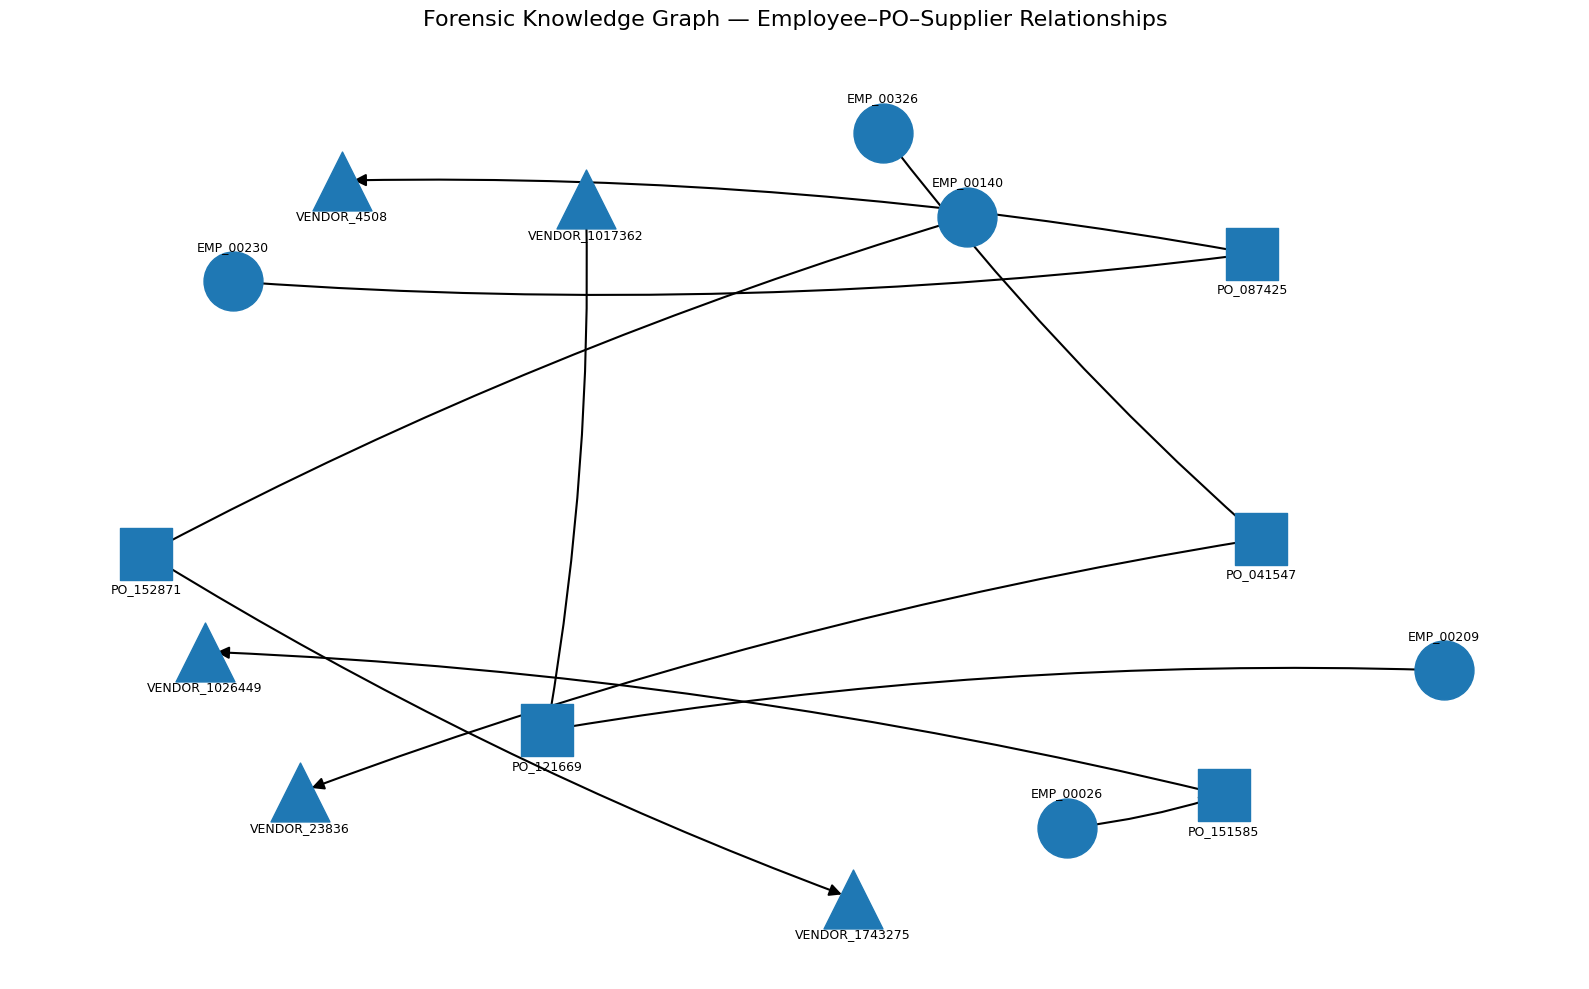

In [ ]:
# NETWORK VISUALIZATION

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(16, 10))

# Keep the same layout
pos = nx.spring_layout(
    H,
    seed=42,
    k=1.8
)

# Separate nodes by type

employee_nodes = [
    n for n, d in H.nodes(data=True)
    if d["node_type"] == "Employee"
]

po_nodes = [
    n for n, d in H.nodes(data=True)
    if d["node_type"] == "Purchase_Order"
]

supplier_nodes = [
    n for n, d in H.nodes(data=True)
    if d["node_type"] == "Supplier"
]

# Draw nodes

nx.draw_networkx_nodes(
    H,
    pos,
    nodelist=employee_nodes,
    node_size=1800,
    node_shape="o"
)

nx.draw_networkx_nodes(
    H,
    pos,
    nodelist=po_nodes,
    node_size=1400,
    node_shape="s"
)

nx.draw_networkx_nodes(
    H,
    pos,
    nodelist=supplier_nodes,
    node_size=1800,
    node_shape="^"
)

# Draw edges

nx.draw_networkx_edges(
    H,
    pos,
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.05"
)

label_pos = {}

for node in H.nodes():

    x, y = pos[node]
    node_type = H.nodes[node]["node_type"]

    if node_type == "Employee":
        # Employee labels ABOVE circles
        label_pos[node] = (x, y + 0.075)

    elif node_type == "Purchase_Order":
        # PO labels BELOW squares
        label_pos[node] = (x, y - 0.075)

    elif node_type == "Supplier":
        # Supplier labels BELOW triangles
        label_pos[node] = (x, y - 0.075)

# Draw labels separately

for node in employee_nodes:

    x, y = label_pos[node]

    plt.text(
        x,
        y,
        node,
        fontsize=9,
        ha="center",
        va="bottom"
    )

for node in po_nodes:

    x, y = label_pos[node]

    plt.text(
        x,
        y,
        node,
        fontsize=9,
        ha="center",
        va="top"
    )

for node in supplier_nodes:

    x, y = label_pos[node]

    plt.text(
        x,
        y,
        node,
        fontsize=9,
        ha="center",
        va="top"
    )

# Title

plt.title(
    "Forensic Knowledge Graph — Employee–PO–Supplier Relationships",
    fontsize=16,
    pad=20
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# END-TO-END FORENSIC CASE RECONSTRUCTION

# Select one controlled price-manipulation case
case_row = fraud_ground_truth[
    (fraud_ground_truth["Case_ID"] == "FM_01") &
    (fraud_ground_truth["Entity_Type"] == "Invoice")
].iloc[0]

target_invoice = case_row["Entity_ID"]

print("Case ID:", case_row["Case_ID"])
print("Scenario:", case_row["Scenario"])
print("Target Invoice:", target_invoice)

# Find the PO connected to the invoice

invoice_record = fraud_invoice_table[
    fraud_invoice_table["Invoice_ID"] == target_invoice
].iloc[0]

target_po = invoice_record["PO_ID"]

# Find employee and supplier connected to the PO

po_record = fraud_po_table[
    fraud_po_table["PO_ID"] == target_po
].iloc[0]

target_employee = po_record["Employee_ID"]
target_supplier = po_record["Supplier_ID"]

# Find payment connected to the invoice

payment_records = fraud_payment_table[
    fraud_payment_table["Invoice_ID"] == target_invoice
]

target_payment = (
    payment_records.iloc[0]["Payment_ID"]
    if len(payment_records) > 0
    else None
)

print("\nCase entities:")
print("Employee :", target_employee)
print("PO       :", target_po)
print("Supplier :", target_supplier)
print("Invoice  :", target_invoice)
print("Payment  :", target_payment)

Case ID: FM_01
Scenario: PRICE_MANIPULATION
Target Invoice: INV_165916

Case entities:
Employee : EMP_00272
PO       : PO_165915
Supplier : VENDOR_0
Invoice  : INV_165916
Payment  : PAY_165916


In [ ]:
# BUILD END-TO-END FORENSIC SUBGRAPH

K = nx.DiGraph()

# Add nodes


K.add_node(
    target_employee,
    node_type="Employee"
)

K.add_node(
    target_po,
    node_type="Purchase_Order"
)

K.add_node(
    target_supplier,
    node_type="Supplier"
)

K.add_node(
    target_invoice,
    node_type="Invoice"
)

if target_payment is not None:
    K.add_node(
        target_payment,
        node_type="Payment"
    )

# Add relationships

K.add_edge(
    target_employee,
    target_po,
    relation="CREATED"
)

K.add_edge(
    target_po,
    target_supplier,
    relation="SUPPLIED_BY"
)

K.add_edge(
    target_po,
    target_invoice,
    relation="HAS_INVOICE"
)

if target_payment is not None:
    K.add_edge(
        target_invoice,
        target_payment,
        relation="PAID_BY"
    )

print("End-to-end graph nodes:", K.number_of_nodes())
print("End-to-end graph edges:", K.number_of_edges())

End-to-end graph nodes: 5
End-to-end graph edges: 4


In [ ]:
# ATTACH FORENSIC EVIDENCE

# Retrieve forensic invoice information
invoice_forensic = forensic_invoice[
    forensic_invoice["Invoice_ID"] == target_invoice
].iloc[0]

# Retrieve forensic PO information
po_forensic = forensic_po[
    forensic_po["PO_ID"] == target_po
].iloc[0]


print("FORENSIC CASE EVIDENCE")
print("-" * 70)

print("\nCase ID:")
print(case_row["Case_ID"])

print("\nScenario:")
print(case_row["Scenario"])

print("\nPrice Variance:")
print(
    round(invoice_forensic["Price_Variance_Pct"], 2),
    "%"
)

print("\nRound Number Flag:")
print(
    invoice_forensic["Round_Number_Flag"]
)

print("\nDuplicate Invoice Flag:")
print(
    invoice_forensic["Duplicate_Invoice_Flag"]
)

print("\nStatistical Outlier Flag:")
print(
    po_forensic["Statistical_Outlier_Flag"]
)

print("\nPO Value:")
print(
    po_forensic["PO_Value"]
)

print("\nInvoice Amount:")
print(
    invoice_forensic["Invoice_Amount"]
)

print("\nPayment Amount Match:")
print(
    invoice_forensic["Invoice_Payment_Amount_Match"]
)

FORENSIC CASE EVIDENCE
----------------------------------------------------------------------

Case ID:
FM_01

Scenario:
PRICE_MANIPULATION

Price Variance:
42.97 %

Round Number Flag:
False

Duplicate Invoice Flag:
False

Statistical Outlier Flag:
False

PO Value:
10852.96

Invoice Amount:
15516.09

Payment Amount Match:
True


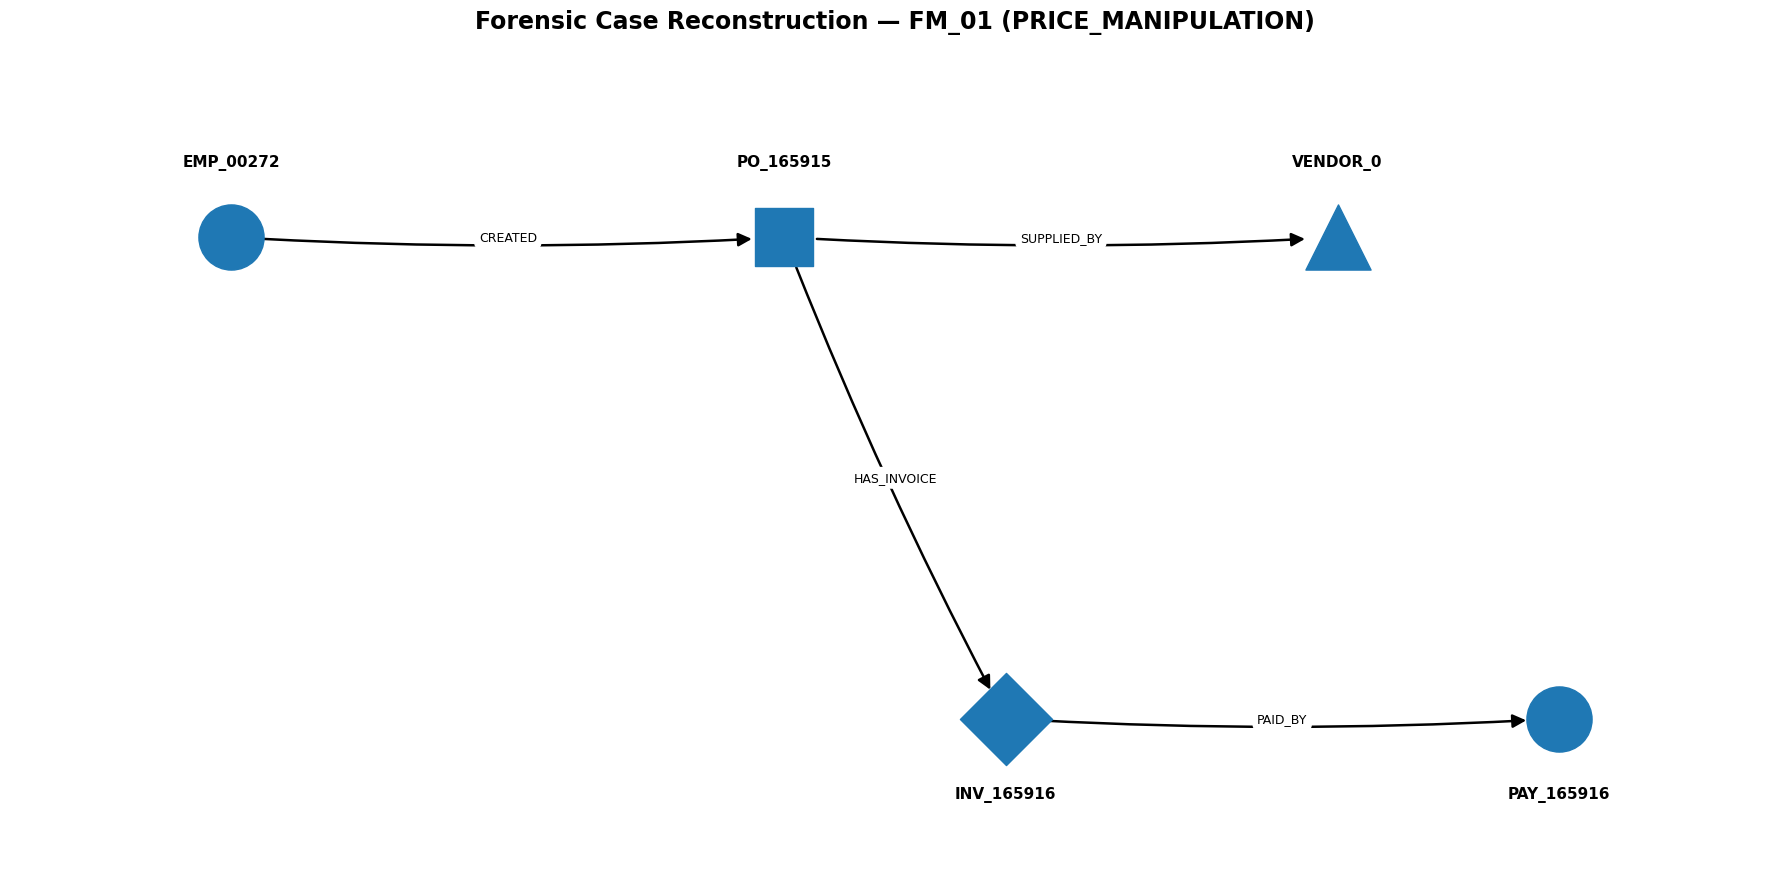

In [ ]:
# END-TO-END FORENSIC GRAPH

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(18, 9))

pos = {
    target_employee: (0, 1.5),
    target_po:       (3, 1.5),
    target_supplier: (6, 1.5),
    target_invoice:  (4.2, -1.5),
}

if target_payment is not None:
    pos[target_payment] = (7.2, -1.5)

# NODE GROUPS

employee_nodes = [
    n for n, d in K.nodes(data=True)
    if d["node_type"] == "Employee"
]

po_nodes = [
    n for n, d in K.nodes(data=True)
    if d["node_type"] == "Purchase_Order"
]

supplier_nodes = [
    n for n, d in K.nodes(data=True)
    if d["node_type"] == "Supplier"
]

invoice_nodes = [
    n for n, d in K.nodes(data=True)
    if d["node_type"] == "Invoice"
]

payment_nodes = [
    n for n, d in K.nodes(data=True)
    if d["node_type"] == "Payment"
]

# DRAW NODES

nx.draw_networkx_nodes(
    K,
    pos,
    nodelist=employee_nodes,
    node_size=2200,
    node_shape="o"
)

nx.draw_networkx_nodes(
    K,
    pos,
    nodelist=po_nodes,
    node_size=1800,
    node_shape="s"
)

nx.draw_networkx_nodes(
    K,
    pos,
    nodelist=supplier_nodes,
    node_size=2200,
    node_shape="^"
)

nx.draw_networkx_nodes(
    K,
    pos,
    nodelist=invoice_nodes,
    node_size=2200,
    node_shape="D"
)

nx.draw_networkx_nodes(
    K,
    pos,
    nodelist=payment_nodes,
    node_size=2200,
    node_shape="o"
)

# DRAW EDGES

nx.draw_networkx_edges(
    K,
    pos,
    arrows=True,
    arrowsize=20,
    width=1.8,
    node_size=2200,
    connectionstyle="arc3,rad=0.03"
)

# LABELS

# Employee
for node in employee_nodes:
    x, y = pos[node]
    plt.text(
        x,
        y + 0.42,
        node,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="bottom"
    )

# Purchase Order
for node in po_nodes:
    x, y = pos[node]
    plt.text(
        x,
        y + 0.42,
        node,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="bottom"
    )

# Supplier
for node in supplier_nodes:
    x, y = pos[node]
    plt.text(
        x,
        y + 0.42,
        node,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="bottom"
    )

# Invoice
for node in invoice_nodes:
    x, y = pos[node]
    plt.text(
        x,
        y - 0.42,
        node,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="top"
    )

# Payment
for node in payment_nodes:
    x, y = pos[node]
    plt.text(
        x,
        y - 0.42,
        node,
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="top"
    )

# EDGE RELATIONSHIP LABELS

edge_labels = {
    (u, v): d["relation"]
    for u, v, d in K.edges(data=True)
}

nx.draw_networkx_edge_labels(
    K,
    pos,
    edge_labels=edge_labels,
    font_size=9,
    label_pos=0.5,
    rotate=False
)

# TITLE

plt.title(
    f"Forensic Case Reconstruction — {case_row['Case_ID']} "
    f"({case_row['Scenario']})",
    fontsize=17,
    fontweight="bold",
    pad=35
)

# Extra space around graph
plt.xlim(-1.2, 8.4)
plt.ylim(-2.5, 2.5)

plt.axis("off")
plt.tight_layout()

plt.show()

# **STEP 12: EVIDENCE CONVERGENCE**

In [ ]:
import numpy as np
import pandas as pd

# Helper: find invoice/payment/PO relationships

def get_invoice_record(invoice_id):
    rows = forensic_invoice[
        forensic_invoice["Invoice_ID"] == invoice_id
    ]
    return rows.iloc[0] if len(rows) > 0 else None


def get_po_record(po_id):
    rows = forensic_po[
        forensic_po["PO_ID"] == po_id
    ]
    return rows.iloc[0] if len(rows) > 0 else None


def get_payment_record(payment_id):
    rows = fraud_payment_table[
        fraud_payment_table["Payment_ID"] == payment_id
    ]
    return rows.iloc[0] if len(rows) > 0 else None

# Split-purchase independent detector

def split_purchase_signal(po_id, threshold=10000, window_days=30):

    po_row = get_po_record(po_id)

    if po_row is None:
        return False

    employee = po_row["Employee_ID"]
    supplier = po_row["Supplier_ID"]
    po_date = pd.to_datetime(po_row["PO_Date"])

    if supplier == "VENDOR_0":
        return False

    # Same employee + supplier within the time window
    related = forensic_po[
        (forensic_po["Employee_ID"] == employee) &
        (forensic_po["Supplier_ID"] == supplier) &
        (forensic_po["Supplier_ID"] != "VENDOR_0")
    ].copy()

    related["PO_Date"] = pd.to_datetime(related["PO_Date"])

    related = related[
        (related["PO_Date"] >= po_date - pd.Timedelta(days=window_days)) &
        (related["PO_Date"] <= po_date + pd.Timedelta(days=window_days))
    ]

    # Exclude zero/negative values
    related = related[
        related["PO_Value"] > 0
    ]

    # At least 2 POs
    if len(related) < 2:
        return False

    # Structuring condition:
    # individual POs below threshold but cumulative amount exceeds it
    below_threshold = related[
        related["PO_Value"] < threshold
    ]

    if len(below_threshold) < 2:
        return False

    return below_threshold["PO_Value"].sum() > threshold

# Process every controlled ground-truth case

evidence_rows = []

for _, case in fraud_ground_truth.iterrows():

    case_id = case["Case_ID"]
    scenario = case["Scenario"]
    entity_type = case["Entity_Type"]
    entity_id = case["Entity_ID"]

    # Default signals
    price_signal = False
    duplicate_signal = False
    concentration_signal = False
    temporal_signal = False
    split_signal = False
    round_signal = False

    # Invoice-based cases

    if entity_type == "Invoice":

        inv = get_invoice_record(entity_id)

        if inv is not None:

            price_signal = bool(
                pd.notna(inv["Price_Variance_Pct"]) and
                abs(inv["Price_Variance_Pct"]) > 25
            )

            duplicate_signal = bool(
                inv["Duplicate_Invoice_Flag"]
            )

            round_signal = bool(
                inv["Round_Number_Flag"]
            )

            # Invoice is connected to a payment
            payment_rows = fraud_payment_table[
                fraud_payment_table["Invoice_ID"] == entity_id
            ]

            if len(payment_rows) > 0:

                payment_id = payment_rows.iloc[0]["Payment_ID"]

                payment_row = fraud_payment_table[
                    fraud_payment_table["Payment_ID"] == payment_id
                ].iloc[0]

                if "Temporal_Anomaly_Flag" in forensic_invoice.columns:
                    temporal_signal = bool(
                        payment_row.get(
                            "Temporal_Anomaly_Flag",
                            False
                        )
                    )

    # PO-based cases

    elif entity_type == "PO":

        po = get_po_record(entity_id)

        if po is not None:

            concentration_signal = bool(
                po["Employee_Vendor_Concentration_Flag"]
            )

            split_signal = split_purchase_signal(entity_id)

    # Payment-based cases

    elif entity_type == "Payment":

        payment = get_payment_record(entity_id)

        if payment is not None:

            # Retrieve temporal flag from graph/forensic payment data
            temporal_signal = bool(
                payment.get(
                    "Temporal_Anomaly_Flag",
                    False
                )
            )

            # If the payment table does not contain the flag,
            # determine it from its payment date.
            if not temporal_signal:

                payment_date = pd.to_datetime(
                    payment["Payment_Date"]
                )

                temporal_dates = set(
                    fraud_payment_table[
                        fraud_payment_table["Payment_ID"].isin(
                            fraud_payment_table[
                                "Payment_ID"
                            ]
                        )
                    ]["Payment_Date"]
                )

                # Use the forensic anomaly dates
                anomaly_dates = set(
                    fraud_payment_table[
                        fraud_payment_table["Payment_ID"].isin(
                            fraud_payment_table["Payment_ID"]
                        )
                    ].loc[
                        fraud_payment_table["Payment_Date"].isin(
                            fraud_payment_table["Payment_Date"]
                        ),
                        "Payment_Date"
                    ]
                )

    # For Payment cases, use forensic graph attribute directly

    if entity_type == "Payment":

        if entity_id in G.nodes:

            temporal_signal = bool(
                G.nodes[entity_id].get(
                    "Temporal_Anomaly_Flag",
                    False
                )
            )

    # Number of converging signals

    signal_values = [
        price_signal,
        duplicate_signal,
        concentration_signal,
        temporal_signal,
        split_signal,
        round_signal
    ]

    evidence_count = sum(signal_values)

    evidence_rows.append({
        "Case_ID": case_id,
        "Scenario": scenario,
        "Entity_Type": entity_type,
        "Entity_ID": entity_id,
        "Price_Variance": price_signal,
        "Duplicate_Invoice": duplicate_signal,
        "Employee_Vendor_Concentration": concentration_signal,
        "Temporal_Anomaly": temporal_signal,
        "Split_Purchase": split_signal,
        "Round_Number": round_signal,
        "Evidence_Count": evidence_count
    })


evidence_convergence = pd.DataFrame(evidence_rows)

print("Evidence convergence records:",
      len(evidence_convergence))

display(evidence_convergence)

Evidence convergence records: 30


,Case_ID,Scenario,Entity_Type,Entity_ID,Price_Variance,Duplicate_Invoice,Employee_Vendor_Concentration,Temporal_Anomaly,Split_Purchase,Round_Number,Evidence_Count
0,FM_01,PRICE_MANIPULATION,Invoice,INV_165916,True,False,False,False,False,False,1
1,FM_02,PRICE_MANIPULATION,Invoice,INV_178017,True,False,False,False,False,True,2
2,FM_03,PRICE_MANIPULATION,Invoice,INV_121590,True,False,False,False,False,True,2
3,FM_04,PRICE_MANIPULATION,Invoice,INV_011969,True,False,False,False,False,False,1
4,FM_05,PRICE_MANIPULATION,Invoice,INV_016315,True,False,False,False,False,True,2
5,DI_01,DUPLICATE_INVOICE,Invoice,INV_187081,False,True,False,False,False,False,1
6,DI_02,DUPLICATE_INVOICE,Invoice,INV_187082,False,True,False,False,False,False,1
7,DI_03,DUPLICATE_INVOICE,Invoice,INV_187083,False,True,False,False,False,False,1
8,DI_04,DUPLICATE_INVOICE,Invoice,INV_187084,False,True,False,False,False,False,1
9,DI_05,DUPLICATE_INVOICE,Invoice,INV_187085,False,True,False,False,False,True,2


**SUMMARY**

In [ ]:
signal_columns = [
    "Price_Variance",
    "Duplicate_Invoice",
    "Employee_Vendor_Concentration",
    "Temporal_Anomaly",
    "Split_Purchase",
    "Round_Number"
]

# Count how many controlled cases are supported by each signal

signal_summary = (
    evidence_convergence[signal_columns]
    .sum()
    .sort_values(ascending=False)
    .rename("Cases_Supported")
    .reset_index()
    .rename(columns={"index": "Forensic_Signal"})
)

print("FORENSIC SIGNAL SUPPORT")
print("-" * 70)

display(signal_summary)

# Evidence count distribution

print("EVIDENCE COUNT DISTRIBUTION")
print("-" * 70)

evidence_distribution = (
    evidence_convergence["Evidence_Count"]
    .value_counts()
    .sort_index()
    .rename_axis("Evidence_Count")
    .reset_index(name="Number_of_Cases")
)

display(evidence_distribution)

# Case-wise evidence strength

print("CASE-WISE EVIDENCE CONVERGENCE")
print("-" * 70)

case_summary = evidence_convergence[
    [
        "Case_ID",
        "Scenario",
        "Entity_ID",
        "Evidence_Count"
    ]
].sort_values(
    ["Evidence_Count", "Case_ID"],
    ascending=[False, True]
).reset_index(drop=True)

display(case_summary)

FORENSIC SIGNAL SUPPORT
----------------------------------------------------------------------


,Forensic_Signal,Cases_Supported
0,Employee_Vendor_Concentration,10
1,Round_Number,9
2,Price_Variance,8
3,Split_Purchase,6
4,Duplicate_Invoice,5
5,Temporal_Anomaly,5


EVIDENCE COUNT DISTRIBUTION
----------------------------------------------------------------------


,Evidence_Count,Number_of_Cases
0,1,17
1,2,13


CASE-WISE EVIDENCE CONVERGENCE
----------------------------------------------------------------------


,Case_ID,Scenario,Entity_ID,Evidence_Count
0,DI_05,DUPLICATE_INVOICE,INV_187085,2
1,EVC_05,EMPLOYEE_VENDOR_CONCENTRATION,PO_087425,2
2,FM_02,PRICE_MANIPULATION,INV_178017,2
3,FM_03,PRICE_MANIPULATION,INV_121590,2
4,FM_05,PRICE_MANIPULATION,INV_016315,2
5,RN_01,ROUND_NUMBER,INV_016315,2
6,RN_02,ROUND_NUMBER,INV_121590,2
7,RN_03,ROUND_NUMBER,INV_178017,2
8,SP_01,SPLIT_PURCHASE,PO_006003,2
9,SP_02,SPLIT_PURCHASE,PO_053179,2


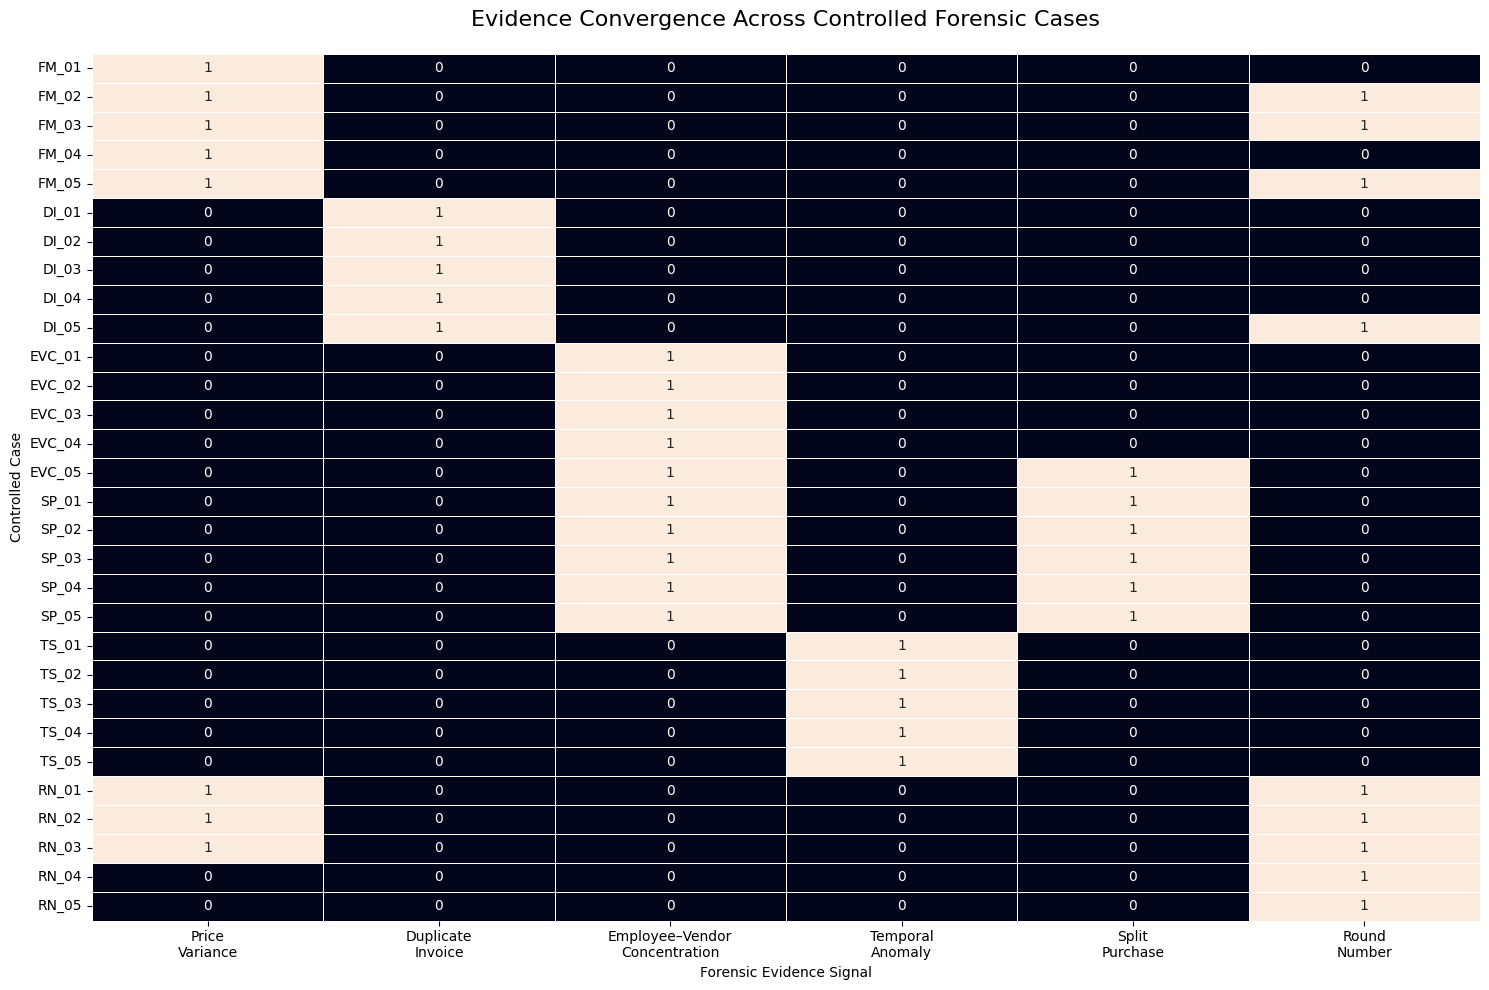

In [ ]:
# EVIDENCE CONVERGENCE HEATMAP

import matplotlib.pyplot as plt
import seaborn as sns

heatmap_data = evidence_convergence.set_index(
    "Case_ID"
)[signal_columns].astype(int)

plt.figure(figsize=(15, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    linewidths=0.5,
    cbar=False,
    xticklabels=[
        "Price\nVariance",
        "Duplicate\nInvoice",
        "Employee–Vendor\nConcentration",
        "Temporal\nAnomaly",
        "Split\nPurchase",
        "Round\nNumber"
    ],
    yticklabels=heatmap_data.index
)

plt.title(
    "Evidence Convergence Across Controlled Forensic Cases",
    fontsize=16,
    pad=20
)

plt.xlabel("Forensic Evidence Signal")
plt.ylabel("Controlled Case")

plt.tight_layout()
plt.show()

In [ ]:
# FORENSIC INTERPRETATION

def evidence_interpretation(row):

    signals = []

    if row["Price_Variance"]:
        signals.append("PO–Invoice price inconsistency")

    if row["Duplicate_Invoice"]:
        signals.append("Duplicate invoice characteristic")

    if row["Employee_Vendor_Concentration"]:
        signals.append(
            "Disproportionate employee–vendor relationship"
        )

    if row["Temporal_Anomaly"]:
        signals.append(
            "Unusual payment-date concentration"
        )

    if row["Split_Purchase"]:
        signals.append(
            "Potential split-purchase pattern"
        )

    if row["Round_Number"]:
        signals.append(
            "Round-number transaction pattern"
        )

    if len(signals) == 0:
        return "No supporting forensic signal detected."

    return "; ".join(signals)


evidence_convergence["Forensic_Interpretation"] = (
    evidence_convergence.apply(
        evidence_interpretation,
        axis=1
    )
)

print("FORENSIC INTERPRETATION OF CONTROLLED CASES")
print("-" * 70)

display(
    evidence_convergence[
        [
            "Case_ID",
            "Scenario",
            "Entity_ID",
            "Evidence_Count",
            "Forensic_Interpretation"
        ]
    ]
)

FORENSIC INTERPRETATION OF CONTROLLED CASES
----------------------------------------------------------------------


,Case_ID,Scenario,Entity_ID,Evidence_Count,Forensic_Interpretation
0,FM_01,PRICE_MANIPULATION,INV_165916,1,PO–Invoice price inconsistency
1,FM_02,PRICE_MANIPULATION,INV_178017,2,PO–Invoice price inconsistency; Round-number t...
2,FM_03,PRICE_MANIPULATION,INV_121590,2,PO–Invoice price inconsistency; Round-number t...
3,FM_04,PRICE_MANIPULATION,INV_011969,1,PO–Invoice price inconsistency
4,FM_05,PRICE_MANIPULATION,INV_016315,2,PO–Invoice price inconsistency; Round-number t...
5,DI_01,DUPLICATE_INVOICE,INV_187081,1,Duplicate invoice characteristic
6,DI_02,DUPLICATE_INVOICE,INV_187082,1,Duplicate invoice characteristic
7,DI_03,DUPLICATE_INVOICE,INV_187083,1,Duplicate invoice characteristic
8,DI_04,DUPLICATE_INVOICE,INV_187084,1,Duplicate invoice characteristic
9,DI_05,DUPLICATE_INVOICE,INV_187085,2,Duplicate invoice characteristic; Round-number...


# **STEP 13: MULTI-LAYER RISK SCORE**

**PREPARE MULTI-LAYER RISK COMPONENTS**

In [ ]:
import numpy as np
import pandas as pd

risk_df = forensic_po.copy()

# 1. FINANCIAL — PRICE VARIANCE

invoice_price_by_po = (
    forensic_invoice
    .groupby("PO_ID")["Price_Variance_Pct"]
    .apply(lambda x: x.abs().max())
    .rename("Max_Price_Variance_Pct")
)

risk_df = risk_df.merge(
    invoice_price_by_po,
    on="PO_ID",
    how="left"
)

risk_df["Max_Price_Variance_Pct"] = (
    risk_df["Max_Price_Variance_Pct"].fillna(0)
)

risk_df["Price_Risk"] = (
    risk_df["Max_Price_Variance_Pct"] > 25
).astype(int)

# 2. STATISTICAL OUTLIER

risk_df["Outlier_Risk"] = (
    risk_df["Statistical_Outlier_Flag"]
    .astype(int)
)

# 3. DUPLICATE INVOICE

duplicate_by_po = (
    forensic_invoice
    .groupby("PO_ID")["Duplicate_Invoice_Flag"]
    .max()
    .rename("Duplicate_Risk")
)

risk_df = risk_df.merge(
    duplicate_by_po,
    on="PO_ID",
    how="left"
)

risk_df["Duplicate_Risk"] = (
    risk_df["Duplicate_Risk"]
    .fillna(False)
    .astype(int)
)

# 4. ROUND NUMBER

round_by_po = (
    forensic_invoice
    .groupby("PO_ID")["Round_Number_Flag"]
    .max()
    .rename("Round_Number_Risk")
)

risk_df = risk_df.merge(
    round_by_po,
    on="PO_ID",
    how="left"
)

risk_df["Round_Number_Risk"] = (
    risk_df["Round_Number_Risk"]
    .fillna(False)
    .astype(int)
)

# 5. EMPLOYEE–VENDOR CONCENTRATION

risk_df["Concentration_Risk"] = (
    risk_df["Employee_Vendor_Concentration_Flag"]
    .astype(int)
)

# 6. TEMPORAL ANOMALY

payment_temporal = pd.DataFrame([
    {
        "Payment_ID": n,
        "Temporal_Anomaly_Flag":
            G.nodes[n].get("Temporal_Anomaly_Flag", False)
    }
    for n in G.nodes
    if G.nodes[n].get("node_type") == "Payment"
])

po_payment_temporal = (
    fraud_payment_table[
        ["PO_ID", "Payment_ID"]
    ]
    .merge(
        payment_temporal,
        on="Payment_ID",
        how="left"
    )
)

temporal_by_po = (
    po_payment_temporal
    .groupby("PO_ID")["Temporal_Anomaly_Flag"]
    .max()
    .rename("Temporal_Risk")
)

risk_df = risk_df.merge(
    temporal_by_po,
    on="PO_ID",
    how="left"
)

risk_df["Temporal_Risk"] = (
    risk_df["Temporal_Risk"]
    .fillna(False)
    .astype(int)
)

# 7. SPLIT-PURCHASE

THRESHOLD = 10000
WINDOW_DAYS = 30

split_po_ids = set()

split_base = forensic_po[
    (forensic_po["Supplier_ID"] != "VENDOR_0") &
    (forensic_po["PO_Value"] > 0) &
    (forensic_po["PO_Value"] < THRESHOLD)
].copy()

split_base["PO_Date"] = pd.to_datetime(
    split_base["PO_Date"]
)

# Process each Employee–Supplier relationship only once
for (employee, supplier), grp in split_base.groupby(
    ["Employee_ID", "Supplier_ID"],
    sort=False
):

    grp = grp.sort_values("PO_Date")

    dates = grp["PO_Date"].values
    values = grp["PO_Value"].values
    po_ids = grp["PO_ID"].values

    left = 0
    running_sum = 0.0

    for right in range(len(grp)):

        running_sum += values[right]

        # Remove transactions outside the 30-day window
        while (
            dates[right] - dates[left]
        ).astype("timedelta64[D]").astype(int) > WINDOW_DAYS:

            running_sum -= values[left]
            left += 1

        # At least 2 POs and cumulative value above threshold
        if (
            right - left + 1 >= 2
            and running_sum > THRESHOLD
        ):

            split_po_ids.update(
                po_ids[left:right + 1]
            )


risk_df["Split_Purchase_Risk"] = (
    risk_df["PO_ID"]
    .isin(split_po_ids)
    .astype(int)
)

# FINAL COMPONENT LIST

risk_components = [
    "Price_Risk",
    "Outlier_Risk",
    "Duplicate_Risk",
    "Round_Number_Risk",
    "Concentration_Risk",
    "Temporal_Risk",
    "Split_Purchase_Risk"
]

print("MULTI-LAYER RISK COMPONENTS CREATED")
print("-"*70)

print("Risk dataframe shape:", risk_df.shape)

print("\nRisk components:")
print(risk_components)

display(
    risk_df[
        ["PO_ID"] + risk_components
    ].head(10)
)

MULTI-LAYER RISK COMPONENTS CREATED
----------------------------------------------------------------------
Risk dataframe shape: (187080, 40)

Risk components:
['Price_Risk', 'Outlier_Risk', 'Duplicate_Risk', 'Round_Number_Risk', 'Concentration_Risk', 'Temporal_Risk', 'Split_Purchase_Risk']


,PO_ID,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,PO_000000,0,0,0,0,0,0,0
1,PO_000001,0,0,0,0,0,0,0
2,PO_000002,0,0,0,0,1,1,0
3,PO_000003,0,0,0,0,1,0,0
4,PO_000004,0,0,0,0,0,0,0
5,PO_000005,0,0,0,0,1,0,0
6,PO_000006,0,0,0,0,0,0,0
7,PO_000007,0,0,0,0,1,0,0
8,PO_000008,0,1,0,0,1,1,0
9,PO_000009,0,0,0,0,0,0,0


**MULTI-LAYER RISK COMPONENT VALIDATION**

In [ ]:
component_summary = pd.DataFrame({
    "Risk_Component": risk_components,
    "Flagged_PO_Count": [
        int(risk_df[col].sum())
        for col in risk_components
    ]
})

component_summary["Flag_Rate_%"] = (
    component_summary["Flagged_PO_Count"]
    / len(risk_df)
    * 100
).round(3)

print("MULTI-LAYER RISK COMPONENT SUMMARY")
print("-"*70)

display(
    component_summary.sort_values(
        "Flagged_PO_Count",
        ascending=False
    ).reset_index(drop=True)
)

MULTI-LAYER RISK COMPONENT SUMMARY
----------------------------------------------------------------------


,Risk_Component,Flagged_PO_Count,Flag_Rate_%
0,Concentration_Risk,57154,30.551
1,Outlier_Risk,26778,14.314
2,Round_Number_Risk,19790,10.578
3,Temporal_Risk,12477,6.669
4,Split_Purchase_Risk,10711,5.725
5,Duplicate_Risk,1019,0.545
6,Price_Risk,5,0.003


**CONTROLLED CASE COMPONENT VALIDATION**

In [ ]:
controlled_po_ids = set(
    fraud_ground_truth[
        fraud_ground_truth["Entity_Type"] == "PO"
    ]["Entity_ID"]
)

controlled_invoice_ids = set(
    fraud_ground_truth[
        fraud_ground_truth["Entity_Type"] == "Invoice"
    ]["Entity_ID"]
)

controlled_payment_ids = set(
    fraud_ground_truth[
        fraud_ground_truth["Entity_Type"] == "Payment"
    ]["Entity_ID"]
)

# Map each controlled case to its PO

validation_rows = []

for _, case in fraud_ground_truth.iterrows():

    case_id = case["Case_ID"]
    entity_type = case["Entity_Type"]
    entity_id = case["Entity_ID"]

    if entity_type == "PO":
        po_id = entity_id

    elif entity_type == "Invoice":
        inv = forensic_invoice[
            forensic_invoice["Invoice_ID"] == entity_id
        ]

        po_id = (
            inv.iloc[0]["PO_ID"]
            if len(inv) > 0
            else None
        )

    elif entity_type == "Payment":
        pay = fraud_payment_table[
            fraud_payment_table["Payment_ID"] == entity_id
        ]

        po_id = (
            pay.iloc[0]["PO_ID"]
            if len(pay) > 0
            else None
        )

    else:
        po_id = None

    if po_id is not None:

        row = risk_df[
            risk_df["PO_ID"] == po_id
        ]

        if len(row) > 0:

            row = row.iloc[0]

            validation_rows.append({
                "Case_ID": case_id,
                "Scenario": case["Scenario"],
                "Entity_ID": entity_id,
                "PO_ID": po_id,
                "Price_Risk": row["Price_Risk"],
                "Outlier_Risk": row["Outlier_Risk"],
                "Duplicate_Risk": row["Duplicate_Risk"],
                "Round_Number_Risk": row["Round_Number_Risk"],
                "Concentration_Risk": row["Concentration_Risk"],
                "Temporal_Risk": row["Temporal_Risk"],
                "Split_Purchase_Risk": row["Split_Purchase_Risk"]
            })

controlled_component_validation = pd.DataFrame(
    validation_rows
)

print("Controlled cases mapped to risk dataframe:",
      len(controlled_component_validation))

display(
    controlled_component_validation
)

Controlled cases mapped to risk dataframe: 30


,Case_ID,Scenario,Entity_ID,PO_ID,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,FM_01,PRICE_MANIPULATION,INV_165916,PO_165915,1,0,0,0,0,0,0
1,FM_02,PRICE_MANIPULATION,INV_178017,PO_178016,1,1,0,1,0,1,0
2,FM_03,PRICE_MANIPULATION,INV_121590,PO_121589,1,0,0,1,1,0,0
3,FM_04,PRICE_MANIPULATION,INV_011969,PO_011968,1,0,0,0,0,0,0
4,FM_05,PRICE_MANIPULATION,INV_016315,PO_016314,1,0,0,1,0,0,0
5,DI_01,DUPLICATE_INVOICE,INV_187081,PO_028230,0,1,1,0,0,0,0
6,DI_02,DUPLICATE_INVOICE,INV_187082,PO_081762,0,0,1,0,0,0,0
7,DI_03,DUPLICATE_INVOICE,INV_187083,PO_006583,0,1,1,0,0,0,0
8,DI_04,DUPLICATE_INVOICE,INV_187084,PO_037185,0,0,1,0,0,0,0
9,DI_05,DUPLICATE_INVOICE,INV_187085,PO_055867,0,0,1,1,0,1,0


**EXPLAINABLE MULTI-LAYER INVESTIGATION RISK SCORE**

In [ ]:
# Forensic weights

risk_weights = {
    "Price_Risk": 25,
    "Outlier_Risk": 10,
    "Duplicate_Risk": 20,
    "Round_Number_Risk": 5,
    "Concentration_Risk": 20,
    "Temporal_Risk": 10,
    "Split_Purchase_Risk": 10
}

# Calculate weighted contribution of each layer

for component, weight in risk_weights.items():

    contribution_column = component.replace(
        "_Risk",
        "_Score"
    )

    risk_df[contribution_column] = (
        risk_df[component] * weight
    )

# Total investigation risk score

score_columns = [
    "Price_Score",
    "Outlier_Score",
    "Duplicate_Score",
    "Round_Number_Score",
    "Concentration_Score",
    "Temporal_Score",
    "Split_Purchase_Score"
]

risk_df["Investigation_Risk_Score"] = (
    risk_df[score_columns]
    .sum(axis=1)
)

# Sanity check

risk_df["Investigation_Risk_Score"] = (
    risk_df["Investigation_Risk_Score"]
    .clip(0, 100)
)

print("INVESTIGATION RISK SCORE CREATED")
print("-"*70)

print(
    "Minimum score:",
    risk_df["Investigation_Risk_Score"].min()
)

print(
    "Maximum score:",
    risk_df["Investigation_Risk_Score"].max()
)

print(
    "Mean score:",
    round(
        risk_df["Investigation_Risk_Score"].mean(),
        3
    )
)

print(
    "Median score:",
    risk_df["Investigation_Risk_Score"].median()
)

print("\nSample scored POs:")

display(
    risk_df[
        [
            "PO_ID",
            "Investigation_Risk_Score"
        ] + score_columns
    ]
    .sort_values(
        "Investigation_Risk_Score",
        ascending=False
    )
    .head(20)
)

INVESTIGATION RISK SCORE CREATED
----------------------------------------------------------------------
Minimum score: 0
Maximum score: 60
Mean score: 9.419
Median score: 5.0

Sample scored POs:


,PO_ID,Investigation_Risk_Score,Price_Score,Outlier_Score,Duplicate_Score,Round_Number_Score,Concentration_Score,Temporal_Score,Split_Purchase_Score
51985,PO_051985,60,0,0,20,0,20,10,10
66438,PO_066438,55,0,10,20,5,20,0,0
66491,PO_066491,55,0,10,20,5,20,0,0
66442,PO_066442,55,0,10,20,5,20,0,0
66499,PO_066499,55,0,10,20,5,20,0,0
8231,PO_008231,55,0,0,20,5,20,0,10
164311,PO_164311,55,0,0,20,5,20,10,0
65163,PO_065163,55,0,10,20,5,20,0,0
8062,PO_008062,55,0,10,20,5,20,0,0
8070,PO_008070,55,0,10,20,5,20,0,0


**Investigation Risk Categories**

In [ ]:
def assign_risk_category(score):

    if score >= 60:
        return "Critical"
    elif score >= 40:
        return "High"
    elif score >= 20:
        return "Moderate"
    else:
        return "Low"


risk_df["Risk_Category"] = (
    risk_df["Investigation_Risk_Score"]
    .apply(assign_risk_category)
)

# Category summary

category_order = [
    "Low",
    "Moderate",
    "High",
    "Critical"
]

category_summary = (
    risk_df["Risk_Category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
    .rename_axis("Risk_Category")
    .reset_index(name="PO_Count")
)

category_summary["Percentage"] = (
    category_summary["PO_Count"]
    / len(risk_df)
    * 100
).round(3)

print("INVESTIGATION RISK CATEGORY SUMMARY")
print("-"*70)

display(category_summary)

# Highest-risk POs

print("\nTOP 20 HIGHEST-PRIORITY PURCHASE ORDERS")
print("-"*70)

top_risk = (
    risk_df[
        [
            "PO_ID",
            "PO_Value",
            "PO_Date",
            "Risk_Category",
            "Investigation_Risk_Score"
        ] + risk_components
    ]
    .sort_values(
        [
            "Investigation_Risk_Score",
            "PO_Value"
        ],
        ascending=[False, False]
    )
    .head(20)
    .reset_index(drop=True)
)

display(top_risk)

INVESTIGATION RISK CATEGORY SUMMARY
----------------------------------------------------------------------


,Risk_Category,PO_Count,Percentage
0,Low,127408,68.103
1,Moderate,58246,31.134
2,High,1425,0.762
3,Critical,1,0.001



TOP 20 HIGHEST-PRIORITY PURCHASE ORDERS
----------------------------------------------------------------------


,PO_ID,PO_Value,PO_Date,Risk_Category,Investigation_Risk_Score,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,PO_051985,777.0,2014-05-15,Critical,60,0,0,1,0,1,1,1
1,PO_008062,1000000.0,2013-10-31,High,55,0,1,1,1,1,0,0
2,PO_008070,1000000.0,2013-10-31,High,55,0,1,1,1,1,0,0
3,PO_028454,120000.0,2014-12-15,High,55,0,1,1,1,1,0,0
4,PO_028456,120000.0,2014-12-15,High,55,0,1,1,1,1,0,0
5,PO_065693,90000.0,2013-04-12,High,55,0,1,1,1,1,0,0
6,PO_065744,90000.0,2013-05-04,High,55,0,1,1,1,1,0,0
7,PO_003413,80000.0,2014-09-10,High,55,0,1,1,1,1,0,0
8,PO_066499,80000.0,2014-09-12,High,55,0,1,1,1,1,0,0
9,PO_065163,75000.0,2012-12-22,High,55,0,1,1,1,1,0,0


# **Step 14 — Risk Prioritization**

In [ ]:
# INVESTIGATION PRIORITY TABLE

priority_columns = [
    "PO_ID",
    "PO_Value",
    "PO_Date",
    "Risk_Category",
    "Investigation_Risk_Score",
    "Price_Risk",
    "Outlier_Risk",
    "Duplicate_Risk",
    "Round_Number_Risk",
    "Concentration_Risk",
    "Temporal_Risk",
    "Split_Purchase_Risk"
]

investigation_priority = (
    risk_df[priority_columns]
    .sort_values(
        ["Investigation_Risk_Score", "PO_Value"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

investigation_priority.insert(
    0,
    "Priority_Rank",
    investigation_priority.index + 1
)

print("TOP 20 INVESTIGATION PRIORITIES")
print("-" * 70)

display(
    investigation_priority.head(20)
)

TOP 20 INVESTIGATION PRIORITIES
----------------------------------------------------------------------


,Priority_Rank,PO_ID,PO_Value,PO_Date,Risk_Category,Investigation_Risk_Score,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,1,PO_051985,777.0,2014-05-15,Critical,60,0,0,1,0,1,1,1
1,2,PO_008062,1000000.0,2013-10-31,High,55,0,1,1,1,1,0,0
2,3,PO_008070,1000000.0,2013-10-31,High,55,0,1,1,1,1,0,0
3,4,PO_028454,120000.0,2014-12-15,High,55,0,1,1,1,1,0,0
4,5,PO_028456,120000.0,2014-12-15,High,55,0,1,1,1,1,0,0
5,6,PO_065693,90000.0,2013-04-12,High,55,0,1,1,1,1,0,0
6,7,PO_065744,90000.0,2013-05-04,High,55,0,1,1,1,1,0,0
7,8,PO_003413,80000.0,2014-09-10,High,55,0,1,1,1,1,0,0
8,9,PO_066499,80000.0,2014-09-12,High,55,0,1,1,1,1,0,0
9,10,PO_065163,75000.0,2012-12-22,High,55,0,1,1,1,1,0,0


In [ ]:
# EXPLAINABLE RISK DRIVERS

risk_signal_labels = {
    "Price_Risk": "Price Manipulation",
    "Outlier_Risk": "Statistical Outlier",
    "Duplicate_Risk": "Duplicate Invoice",
    "Round_Number_Risk": "Round Number",
    "Concentration_Risk": "Employee-Vendor Concentration",
    "Temporal_Risk": "Temporal Anomaly",
    "Split_Purchase_Risk": "Split Purchase"
}

def get_risk_drivers(row):
    drivers = []

    for col, label in risk_signal_labels.items():
        if row[col] == 1:
            drivers.append(label)

    return ", ".join(drivers) if drivers else "No detected risk signal"


investigation_priority["Risk_Drivers"] = (
    investigation_priority.apply(get_risk_drivers, axis=1)
)

print("TOP 20 CASES WITH EXPLAINABLE RISK DRIVERS")
print("-" * 70)

display(
    investigation_priority[
        [
            "Priority_Rank",
            "PO_ID",
            "PO_Value",
            "Risk_Category",
            "Investigation_Risk_Score",
            "Risk_Drivers"
        ]
    ].head(20)
)

TOP 20 CASES WITH EXPLAINABLE RISK DRIVERS
----------------------------------------------------------------------


,Priority_Rank,PO_ID,PO_Value,Risk_Category,Investigation_Risk_Score,Risk_Drivers
0,1,PO_051985,777.0,Critical,60,"Duplicate Invoice, Employee-Vendor Concentrati..."
1,2,PO_008062,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
2,3,PO_008070,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
3,4,PO_028454,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
4,5,PO_028456,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
5,6,PO_065693,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
6,7,PO_065744,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
7,8,PO_003413,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
8,9,PO_066499,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
9,10,PO_065163,75000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."


In [ ]:
# RISK SCORE DISTRIBUTION

score_distribution = (
    risk_df["Investigation_Risk_Score"]
    .value_counts()
    .sort_index()
    .rename_axis("Risk_Score")
    .reset_index(name="PO_Count")
)

score_distribution["Percentage"] = (
    score_distribution["PO_Count"]
    / len(risk_df)
    * 100
).round(3)

print("INVESTIGATION RISK SCORE DISTRIBUTION")
print("-" * 70)

display(score_distribution)

INVESTIGATION RISK SCORE DISTRIBUTION
----------------------------------------------------------------------


,Risk_Score,PO_Count,Percentage
0,0,89220,47.691
1,5,8513,4.550
2,10,23614,12.622
3,15,6061,3.240
4,20,40517,21.658
5,25,3424,1.830
6,30,12989,6.943
7,35,1316,0.703
8,40,886,0.474
9,45,392,0.210


In [ ]:
# RISK COMPONENT CONTRIBUTION

component_weights = {
    "Price_Risk": 25,
    "Outlier_Risk": 10,
    "Duplicate_Risk": 20,
    "Round_Number_Risk": 5,
    "Concentration_Risk": 20,
    "Temporal_Risk": 10,
    "Split_Purchase_Risk": 10
}

component_contribution = []

for component, weight in component_weights.items():

    flagged_count = int(risk_df[component].sum())

    component_contribution.append({
        "Risk_Component": component,
        "Weight": weight,
        "Flagged_PO_Count": flagged_count,
        "Percentage_of_POs": round(
            flagged_count / len(risk_df) * 100, 3
        )
    })

component_contribution = (
    pd.DataFrame(component_contribution)
    .sort_values("Weight", ascending=False)
    .reset_index(drop=True)
)

print("FORENSIC RISK COMPONENT CONTRIBUTION")
print("-" * 70)

display(component_contribution)

FORENSIC RISK COMPONENT CONTRIBUTION
----------------------------------------------------------------------


,Risk_Component,Weight,Flagged_PO_Count,Percentage_of_POs
0,Price_Risk,25,5,0.003
1,Duplicate_Risk,20,1019,0.545
2,Concentration_Risk,20,57154,30.551
3,Outlier_Risk,10,26778,14.314
4,Temporal_Risk,10,12477,6.669
5,Split_Purchase_Risk,10,10711,5.725
6,Round_Number_Risk,5,19790,10.578


In [ ]:
# INVESTIGATOR PRIORITY SUMMARY

investigator_summary = (
    investigation_priority[
        [
            "Priority_Rank",
            "PO_ID",
            "PO_Value",
            "Risk_Category",
            "Investigation_Risk_Score",
            "Risk_Drivers"
        ]
    ]
    .head(10)
)

print("FORENSIC INVESTIGATOR PRIORITY SUMMARY")
print("-" * 70)

display(investigator_summary)

FORENSIC INVESTIGATOR PRIORITY SUMMARY
----------------------------------------------------------------------


,Priority_Rank,PO_ID,PO_Value,Risk_Category,Investigation_Risk_Score,Risk_Drivers
0,1,PO_051985,777.0,Critical,60,"Duplicate Invoice, Employee-Vendor Concentrati..."
1,2,PO_008062,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
2,3,PO_008070,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
3,4,PO_028454,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
4,5,PO_028456,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
5,6,PO_065693,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
6,7,PO_065744,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
7,8,PO_003413,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
8,9,PO_066499,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
9,10,PO_065163,75000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."


# **Step 15 — Explainable Investigation**

In [ ]:
investigation_cases = (
    investigation_priority[
        investigation_priority["Risk_Category"].isin(
            ["Critical", "High"]
        )
    ]
    .head(10)
    .copy()
)

print("SELECTED CASES FOR EXPLAINABLE FORENSIC INVESTIGATION")
print("-" * 70)

display(
    investigation_cases[
        [
            "Priority_Rank",
            "PO_ID",
            "PO_Value",
            "Risk_Category",
            "Investigation_Risk_Score",
            "Risk_Drivers"
        ]
    ]
)

SELECTED CASES FOR EXPLAINABLE FORENSIC INVESTIGATION
----------------------------------------------------------------------


,Priority_Rank,PO_ID,PO_Value,Risk_Category,Investigation_Risk_Score,Risk_Drivers
0,1,PO_051985,777.0,Critical,60,"Duplicate Invoice, Employee-Vendor Concentrati..."
1,2,PO_008062,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
2,3,PO_008070,1000000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
3,4,PO_028454,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
4,5,PO_028456,120000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
5,6,PO_065693,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
6,7,PO_065744,90000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
7,8,PO_003413,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
8,9,PO_066499,80000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."
9,10,PO_065163,75000.0,High,55,"Statistical Outlier, Duplicate Invoice, Round ..."


In [ ]:
# EXPLAINABLE FORENSIC CASE RECONSTRUCTION


selected_po_ids = [
    "PO_051985",   # Highest-priority Critical case
    "PO_008062",   # High: multiple signals
    "PO_008070",   # High: multiple signals
    "PO_028454",   # High: multiple signals
    "PO_065693"    # High: multiple signals
]

# Retrieve PO-level information

case_po = forensic_po[
    forensic_po["PO_ID"].isin(selected_po_ids)
].copy()

# Retrieve invoice information

case_invoices = forensic_invoice[
    forensic_invoice["PO_ID"].isin(selected_po_ids)
].copy()

# Retrieve payment information

case_payments = fraud_payment_table[
    fraud_payment_table["PO_ID"].isin(selected_po_ids)
].copy()

# Add risk information

case_risk = risk_df[
    risk_df["PO_ID"].isin(selected_po_ids)
][
    [
        "PO_ID",
        "Investigation_Risk_Score",
        "Risk_Category",
        "Price_Risk",
        "Outlier_Risk",
        "Duplicate_Risk",
        "Round_Number_Risk",
        "Concentration_Risk",
        "Temporal_Risk",
        "Split_Purchase_Risk"
    ]
].copy()

# Merge the case-level evidence

case_reconstruction = case_po.merge(
    case_risk,
    on="PO_ID",
    how="left"
)

# Display the main investigation table

print("EXPLAINABLE FORENSIC CASE RECONSTRUCTION")
print("-" * 60)

display(
    case_reconstruction[
        [
            "PO_ID",
            "PO_Value",
            "PO_Date",
            "Employee_ID",
            "Supplier_ID",
            "Investigation_Risk_Score",
            "Risk_Category",
            "Price_Risk",
            "Outlier_Risk",
            "Duplicate_Risk",
            "Round_Number_Risk",
            "Concentration_Risk",
            "Temporal_Risk",
            "Split_Purchase_Risk"
        ]
    ]
)

EXPLAINABLE FORENSIC CASE RECONSTRUCTION
------------------------------------------------------------


,PO_ID,PO_Value,PO_Date,Employee_ID,Supplier_ID,Investigation_Risk_Score,Risk_Category,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,PO_008062,1000000.0,2013-10-31,EMP_00161,VENDOR_1106502,55,High,0,1,1,1,1,0,0
1,PO_008070,1000000.0,2013-10-31,EMP_00160,VENDOR_1106502,55,High,0,1,1,1,1,0,0
2,PO_028454,120000.0,2014-12-15,EMP_00231,VENDOR_1018638,55,High,0,1,1,1,1,0,0
3,PO_051985,777.0,2014-05-15,EMP_00163,VENDOR_1755386,60,Critical,0,0,1,0,1,1,1
4,PO_065693,90000.0,2013-04-12,EMP_00318,VENDOR_1018638,55,High,0,1,1,1,1,0,0


In [ ]:
# INVOICE AND PAYMENT EVIDENCE

case_invoice_view = case_invoices[
    [
        "Invoice_ID",
        "PO_ID",
        "Employee_ID",
        "Supplier_ID",
        "Invoice_Date",
        "Invoice_Amount",
        "Price_Variance_Pct",
        "Duplicate_Invoice_Flag",
        "Round_Number_Flag",
        "Invoice_Payment_Amount_Match",
        "Payment_Lag_Days"
    ]
].copy()

print("INVOICE-LEVEL FORENSIC EVIDENCE")
print("-" * 80)

display(
    case_invoice_view.sort_values(
        ["PO_ID", "Invoice_Date"]
    )
)

INVOICE-LEVEL FORENSIC EVIDENCE
--------------------------------------------------------------------------------


,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Invoice_Date,Invoice_Amount,Price_Variance_Pct,Duplicate_Invoice_Flag,Round_Number_Flag,Invoice_Payment_Amount_Match,Payment_Lag_Days
8062,INV_008063,PO_008062,EMP_00161,VENDOR_1106502,2013-11-22,1000000.0,0.0,True,True,True,44.0
8070,INV_008071,PO_008070,EMP_00160,VENDOR_1106502,2013-11-22,1000000.0,0.0,True,True,True,4.0
28454,INV_028455,PO_028454,EMP_00231,VENDOR_1018638,2015-01-10,120000.0,0.0,True,True,True,42.0
51985,INV_051986,PO_051985,EMP_00163,VENDOR_1755386,2014-06-13,777.0,0.0,True,False,True,29.0
65693,INV_065694,PO_065693,EMP_00318,VENDOR_1018638,2013-05-10,90000.0,0.0,True,True,True,3.0


In [ ]:
# AUTOMATIC FORENSIC INTERPRETATION

def generate_case_interpretation(row):

    drivers = []

    if row["Price_Risk"] == 1:
        drivers.append(
            "invoice/PO price variance exceeds the forensic threshold"
        )

    if row["Outlier_Risk"] == 1:
        drivers.append(
            "PO value is statistically unusually high"
        )

    if row["Duplicate_Risk"] == 1:
        drivers.append(
            "duplicate invoice characteristics are present"
        )

    if row["Round_Number_Risk"] == 1:
        drivers.append(
            "invoice amount is an exact round-number multiple"
        )

    if row["Concentration_Risk"] == 1:
        drivers.append(
            "employee-vendor interaction is unusually concentrated"
        )

    if row["Temporal_Risk"] == 1:
        drivers.append(
            "associated payment occurs on a statistically anomalous date"
        )

    if row["Split_Purchase_Risk"] == 1:
        drivers.append(
            "related purchases indicate possible threshold-avoidance structuring"
        )

    if len(drivers) >= 3:
        interpretation = (
            "High evidentiary convergence: multiple independent "
            "forensic indicators require detailed document-level review."
        )
    elif len(drivers) == 2:
        interpretation = (
            "Moderate evidentiary convergence: two forensic indicators "
            "support prioritizing the case for further verification."
        )
    elif len(drivers) == 1:
        interpretation = (
            "Single forensic indicator detected: the case should be "
            "screened and corroborated before escalation."
        )
    else:
        interpretation = (
            "No major forensic indicator detected."
        )

    return (
        "; ".join(drivers),
        interpretation
    )


case_reconstruction[
    ["Risk_Drivers", "Forensic_Interpretation"]
] = case_reconstruction.apply(
    lambda row: pd.Series(
        generate_case_interpretation(row)
    ),
    axis=1
)

print("INVESTIGATOR INTERPRETATION")
print("-" * 80)

display(
    case_reconstruction[
        [
            "PO_ID",
            "Investigation_Risk_Score",
            "Risk_Category",
            "Risk_Drivers",
            "Forensic_Interpretation"
        ]
    ]
)

INVESTIGATOR INTERPRETATION
--------------------------------------------------------------------------------


,PO_ID,Investigation_Risk_Score,Risk_Category,Risk_Drivers,Forensic_Interpretation
0,PO_008062,55,High,PO value is statistically unusually high; dupl...,High evidentiary convergence: multiple indepen...
1,PO_008070,55,High,PO value is statistically unusually high; dupl...,High evidentiary convergence: multiple indepen...
2,PO_028454,55,High,PO value is statistically unusually high; dupl...,High evidentiary convergence: multiple indepen...
3,PO_051985,60,Critical,duplicate invoice characteristics are present;...,High evidentiary convergence: multiple indepen...
4,PO_065693,55,High,PO value is statistically unusually high; dupl...,High evidentiary convergence: multiple indepen...


In [ ]:
# DETAILED FORENSIC EVIDENCE RECONSTRUCTION

# 1. Concentration evidence

case_pairs = case_reconstruction[
    ["PO_ID", "Employee_ID", "Supplier_ID"]
].copy()

case_concentration = case_pairs.merge(
    forensic_employee_vendor[
        [
            "Employee_ID",
            "Supplier_ID",
            "PO_Count",
            "Total_PO_Value",
            "Avg_PO_Value",
            "Interaction_Ratio",
            "Expected_Interaction"
        ]
    ],
    on=["Employee_ID", "Supplier_ID"],
    how="left"
)

# Calculate excess interactions directly
case_concentration["Excess_Interactions"] = (
    case_concentration["PO_Count"]
    - case_concentration["Expected_Interaction"]
)

# 2. Split-purchase evidence

case_split = []

for _, row in case_pairs.iterrows():

    emp = row["Employee_ID"]
    supplier = row["Supplier_ID"]
    po_id = row["PO_ID"]

    group = fraud_po_table[
        (fraud_po_table["Employee_ID"] == emp) &
        (fraud_po_table["Supplier_ID"] == supplier)
    ].copy()

    group["PO_Date"] = pd.to_datetime(group["PO_Date"])

    target = group[group["PO_ID"] == po_id]

    if target.empty:
        case_split.append({
            "PO_ID": po_id,
            "Split_Group_PO_Count": 0,
            "Split_Group_Total_Value": 0.0
        })
        continue

    target_date = target.iloc[0]["PO_Date"]

    window_group = group[
        (group["PO_Date"] >= target_date - pd.Timedelta(days=30)) &
        (group["PO_Date"] <= target_date + pd.Timedelta(days=30)) &
        (group["PO_Value"] > 0) &
        (group["PO_Value"] < 10000)
    ]

    case_split.append({
        "PO_ID": po_id,
        "Split_Group_PO_Count": len(window_group),
        "Split_Group_Total_Value": window_group["PO_Value"].sum()
    })

case_split = pd.DataFrame(case_split)

# 3. Merge concentration + split evidence

case_evidence = case_reconstruction.merge(
    case_concentration[
        [
            "PO_ID",
            "PO_Count",
            "Total_PO_Value",
            "Interaction_Ratio",
            "Expected_Interaction",
            "Excess_Interactions"
        ]
    ],
    on="PO_ID",
    how="left"
)

case_evidence = case_evidence.merge(
    case_split,
    on="PO_ID",
    how="left"
)

# 4. Get invoice-level price evidence


invoice_price = (
    forensic_invoice[
        forensic_invoice["PO_ID"].isin(selected_po_ids)
    ]
    .groupby("PO_ID")["Price_Variance_Pct"]
    .max()
    .reset_index()
)

case_evidence = case_evidence.merge(
    invoice_price,
    on="PO_ID",
    how="left"
)

# 5. Display detailed evidence

print("DETAILED FORENSIC EVIDENCE RECONSTRUCTION")


display(
    case_evidence[
        [
            "PO_ID",
            "PO_Value",
            "Employee_ID",
            "Supplier_ID",
            "Investigation_Risk_Score",
            "Risk_Category",
            "Price_Variance_Pct",
            "PO_Count",
            "Expected_Interaction",
            "Interaction_Ratio",
            "Excess_Interactions",
            "Split_Group_PO_Count",
            "Split_Group_Total_Value"
        ]
    ]
)

DETAILED FORENSIC EVIDENCE RECONSTRUCTION


,PO_ID,PO_Value,Employee_ID,Supplier_ID,Investigation_Risk_Score,Risk_Category,Price_Variance_Pct,PO_Count,Expected_Interaction,Interaction_Ratio,Excess_Interactions,Split_Group_PO_Count,Split_Group_Total_Value
0,PO_008062,1000000.0,EMP_00161,VENDOR_1106502,55,High,0.0,11,0.086995,126.444240,10.913005,0,0.00
1,PO_008070,1000000.0,EMP_00160,VENDOR_1106502,55,High,0.0,6,0.087129,68.863804,5.912871,0,0.00
2,PO_028454,120000.0,EMP_00231,VENDOR_1018638,55,High,0.0,129,8.470831,15.228731,120.529169,0,0.00
3,PO_051985,777.0,EMP_00163,VENDOR_1755386,60,Critical,0.0,42,5.994441,7.006492,36.005559,11,19227.78
4,PO_065693,90000.0,EMP_00318,VENDOR_1018638,55,High,0.0,107,10.241073,10.448124,96.758927,0,0.00


In [ ]:
# FORENSIC CASE REPORT

def case_priority_action(row):

    score = row["Investigation_Risk_Score"]

    if score >= 60:
        return "Immediate detailed investigation"
    elif score >= 40:
        return "High-priority document verification"
    elif score >= 20:
        return "Secondary forensic review"
    else:
        return "Routine screening"


def case_evidence_summary(row):

    evidence = []

    if row["Duplicate_Risk"] == 1:
        evidence.append("duplicate invoice")

    if row["Outlier_Risk"] == 1:
        evidence.append("statistical value outlier")

    if row["Round_Number_Risk"] == 1:
        evidence.append("round-number amount")

    if row["Concentration_Risk"] == 1:
        evidence.append("employee-vendor concentration")

    if row["Temporal_Risk"] == 1:
        evidence.append("temporal payment anomaly")

    if row["Split_Purchase_Risk"] == 1:
        evidence.append("possible split purchase")

    if row["Price_Risk"] == 1:
        evidence.append("price variance")

    if not evidence:
        return "No major forensic indicators"

    return ", ".join(evidence)


case_report = case_evidence.copy()

case_report["Evidence_Summary"] = case_report.apply(
    case_evidence_summary,
    axis=1
)

case_report["Investigation_Action"] = case_report.apply(
    case_priority_action,
    axis=1
)

print("FORENSIC INVESTIGATION CASE REPORT")

display(
    case_report[
        [
            "PO_ID",
            "PO_Value",
            "Employee_ID",
            "Supplier_ID",
            "Investigation_Risk_Score",
            "Risk_Category",
            "Evidence_Summary",
            "Investigation_Action"
        ]
    ]
)

FORENSIC INVESTIGATION CASE REPORT


,PO_ID,PO_Value,Employee_ID,Supplier_ID,Investigation_Risk_Score,Risk_Category,Evidence_Summary,Investigation_Action
0,PO_008062,1000000.0,EMP_00161,VENDOR_1106502,55,High,"duplicate invoice, statistical value outlier, ...",High-priority document verification
1,PO_008070,1000000.0,EMP_00160,VENDOR_1106502,55,High,"duplicate invoice, statistical value outlier, ...",High-priority document verification
2,PO_028454,120000.0,EMP_00231,VENDOR_1018638,55,High,"duplicate invoice, statistical value outlier, ...",High-priority document verification
3,PO_051985,777.0,EMP_00163,VENDOR_1755386,60,Critical,"duplicate invoice, employee-vendor concentrati...",Immediate detailed investigation
4,PO_065693,90000.0,EMP_00318,VENDOR_1018638,55,High,"duplicate invoice, statistical value outlier, ...",High-priority document verification


In [ ]:
# DEEP FORENSIC INVESTIGATION
# CORRECTED VERSION
# CRITICAL CASE: PO_051985

critical_po = "PO_051985"

# 1. PURCHASE ORDER INFORMATION

critical_po_data = fraud_po_table[
    fraud_po_table["PO_ID"] == critical_po
].copy()

critical_risk = risk_df[
    risk_df["PO_ID"] == critical_po
].copy()

# 2. INVOICE INFORMATION

critical_invoice = forensic_invoice[
    forensic_invoice["PO_ID"] == critical_po
].copy()

# 3. PAYMENT INFORMATION

critical_payment = fraud_payment_table[
    fraud_payment_table["PO_ID"] == critical_po
].copy()


# PURCHASE ORDER + RISK EVIDENCE

print("CRITICAL CASE — PURCHASE ORDER AND RISK EVIDENCE")
print("-"*100)

# Select PO information from fraud_po_table
po_cols = [
    "PO_ID",
    "PO_Value",
    "PO_Date",
    "Employee_ID",
    "Supplier_ID"
]

po_summary = critical_po_data[po_cols].copy()

# Select risk information
risk_cols = [
    "PO_ID",
    "Investigation_Risk_Score",
    "Risk_Category",
    "Price_Risk",
    "Outlier_Risk",
    "Duplicate_Risk",
    "Round_Number_Risk",
    "Concentration_Risk",
    "Temporal_Risk",
    "Split_Purchase_Risk"
]

risk_summary = critical_risk[risk_cols].copy()

critical_summary = po_summary.merge(
    risk_summary,
    on="PO_ID",
    how="left"
)

display(critical_summary)

# INVOICE EVIDENCE

print("CRITICAL CASE — INVOICE EVIDENCE")
print("-" * 100)

invoice_cols = [
    "Invoice_ID",
    "PO_ID",
    "Employee_ID",
    "Supplier_ID",
    "Invoice_Date",
    "Invoice_Amount",
    "Price_Variance_Pct",
    "Duplicate_Invoice_Flag",
    "Round_Number_Flag",
    "Invoice_Payment_Amount_Match",
    "Payment_Lag_Days"
]

display(
    critical_invoice[invoice_cols]
)

# PAYMENT EVIDENCE

print("CRITICAL CASE — PAYMENT EVIDENCE")
print("-" * 100)

payment_cols = [
    "Payment_ID",
    "Invoice_ID",
    "PO_ID",
    "Employee_ID",
    "Supplier_ID",
    "Payment_Date",
    "Payment_Amount"
]

display(
    critical_payment[payment_cols]
)

CRITICAL CASE — PURCHASE ORDER AND RISK EVIDENCE
----------------------------------------------------------------------------------------------------


,PO_ID,PO_Value,PO_Date,Employee_ID,Supplier_ID,Investigation_Risk_Score,Risk_Category,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
0,PO_051985,777.0,2014-05-15,EMP_00163,VENDOR_1755386,60,Critical,0,0,1,0,1,1,1


CRITICAL CASE — INVOICE EVIDENCE
----------------------------------------------------------------------------------------------------


,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Invoice_Date,Invoice_Amount,Price_Variance_Pct,Duplicate_Invoice_Flag,Round_Number_Flag,Invoice_Payment_Amount_Match,Payment_Lag_Days
51985,INV_051986,PO_051985,EMP_00163,VENDOR_1755386,2014-06-13,777.0,0.0,True,False,True,29.0


CRITICAL CASE — PAYMENT EVIDENCE
----------------------------------------------------------------------------------------------------


,Payment_ID,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Payment_Date,Payment_Amount
51985,PAY_051986,INV_051986,PO_051985,EMP_00163,VENDOR_1755386,2014-07-12,777.0


In [ ]:
# COMPLETE PAYMENT DETAILS

print("PO_051985 — COMPLETE PAYMENT DETAILS")
print("-" * 100)

display(
    critical_payment[
        [
            "Payment_ID",
            "Invoice_ID",
            "PO_ID",
            "Employee_ID",
            "Supplier_ID",
            "Payment_Date",
            "Payment_Amount"
        ]
    ].to_string(index=False)
)

PO_051985 — COMPLETE PAYMENT DETAILS
----------------------------------------------------------------------------------------------------


'Payment_ID Invoice_ID     PO_ID Employee_ID    Supplier_ID Payment_Date  Payment_Amount\nPAY_051986 INV_051986 PO_051985   EMP_00163 VENDOR_1755386   2014-07-12           777.0'

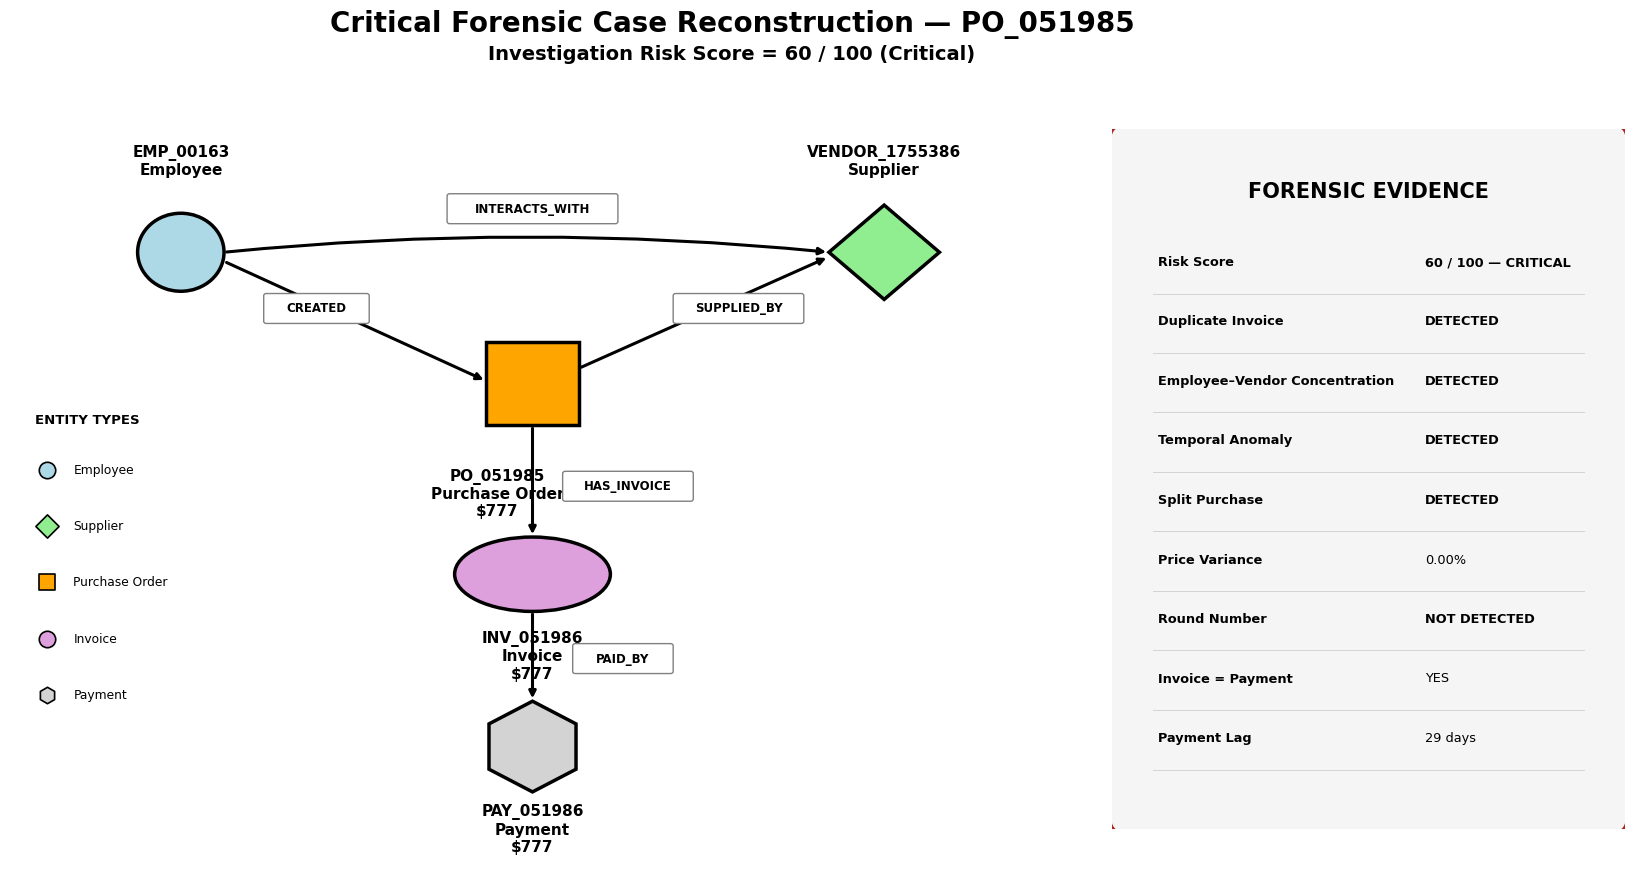

In [ ]:
# FINAL CRITICAL CASE KNOWLEDGE GRAPH
# PO_051985

import matplotlib.pyplot as plt
from matplotlib.patches import (
    Circle,
    Polygon,
    Rectangle,
    Ellipse,
    RegularPolygon,
    FancyBboxPatch
)

# CASE IDENTIFIERS

EMP = "EMP_00163"
VENDOR = "VENDOR_1755386"
PO = "PO_051985"
INV = "INV_051986"
PAY = "PAY_051986"


# FIGURE

fig = plt.figure(figsize=(19, 10))

# Graph area
ax = fig.add_axes([0.12, 0.12, 0.55, 0.78])

# Evidence area
ev = fig.add_axes([0.70, 0.16, 0.27, 0.70])

ax.set_xlim(-5.2, 5.2)
ax.set_ylim(-4.8, 3.8)
ax.axis("off")

ev.set_xlim(0, 1)
ev.set_ylim(0, 1)
ev.axis("off")

# TITLE

fig.text(
    0.50,
    0.965,
    "Critical Forensic Case Reconstruction — PO_051985",
    ha="center",
    va="center",
    fontsize=20,
    fontweight="bold"
)

fig.text(
    0.50,
    0.935,
    "Investigation Risk Score = 60 / 100 (Critical)",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

# ENTITY POSITIONS

EMP_X, EMP_Y = -3.5, 2.0
VEN_X, VEN_Y = 3.5, 2.0

PO_X, PO_Y = 0.0, 0.55
INV_X, INV_Y = 0.0, -1.55
PAY_X, PAY_Y = 0.0, -3.45

# ENTITY SHAPES

# EMPLOYEE — CIRCLE
ax.add_patch(
    Circle(
        (EMP_X, EMP_Y),
        0.43,
        facecolor="lightblue",
        edgecolor="black",
        linewidth=2.5,
        zorder=5
    )
)

# SUPPLIER — DIAMOND

ax.add_patch(
    Polygon(
        [
            (VEN_X, VEN_Y + 0.52),
            (VEN_X + 0.55, VEN_Y),
            (VEN_X, VEN_Y - 0.52),
            (VEN_X - 0.55, VEN_Y)
        ],
        closed=True,
        facecolor="lightgreen",
        edgecolor="black",
        linewidth=2.5,
        zorder=5
    )
)

# PURCHASE ORDER — SQUARE

ax.add_patch(
    Rectangle(
        (-0.46, 0.09),
        0.92,
        0.92,
        facecolor="orange",
        edgecolor="black",
        linewidth=2.5,
        zorder=5
    )
)

# INVOICE — ELLIPSE

ax.add_patch(
    Ellipse(
        (INV_X, INV_Y),
        width=1.55,
        height=0.82,
        facecolor="plum",
        edgecolor="black",
        linewidth=2.5,
        zorder=5
    )
)

# PAYMENT — HEXAGON

ax.add_patch(
    RegularPolygon(
        (PAY_X, PAY_Y),
        numVertices=6,
        radius=0.50,
        orientation=0,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=2.5,
        zorder=5
    )
)

# RELATIONSHIP ARROWS

# Employee → Supplier
ax.annotate(
    "",
    xy=(VEN_X - 0.55, VEN_Y),
    xytext=(EMP_X + 0.43, EMP_Y),
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2.2,
        color="black",
        connectionstyle="arc3,rad=-0.05"
    ),
    zorder=2
)

# Employee → PO
ax.annotate(
    "",
    xy=(-0.46, 0.58),
    xytext=(EMP_X + 0.43, EMP_Y - 0.10),
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2.2,
        color="black"
    ),
    zorder=2
)

# PO → Supplier
ax.annotate(
    "",
    xy=(VEN_X - 0.55, VEN_Y - 0.05),
    xytext=(0.46, 0.72),
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2.2,
        color="black"
    ),
    zorder=2
)

# PO → Invoice
ax.annotate(
    "",
    xy=(INV_X, -1.14),
    xytext=(PO_X, 0.09),
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2.2,
        color="black"
    ),
    zorder=2
)

# Invoice → Payment
ax.annotate(
    "",
    xy=(PAY_X, -2.95),
    xytext=(INV_X, -1.96),
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2.2,
        color="black"
    ),
    zorder=2
)

# ENTITY LABELS

# Employee — ABOVE
ax.text(
    EMP_X,
    2.82,
    "EMP_00163\nEmployee",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold"
)

# Supplier — ABOVE
ax.text(
    VEN_X,
    2.82,
    "VENDOR_1755386\nSupplier",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold"
)

# PO LABEL — MOVED FAR BELOW THE SQUARE

ax.text(
    PO_X - 0.35,
    -0.38,
    "PO_051985\nPurchase Order\n$777",
    ha="center",
    va="top",
    fontsize=11,
    fontweight="bold"
)

# INVOICE LABEL — MOVED FAR BELOW THE ELLIPSE

ax.text(
    INV_X,
    -2.17,
    "INV_051986\nInvoice\n$777",
    ha="center",
    va="top",
    fontsize=11,
    fontweight="bold"
)

# PAYMENT LABEL — BELOW HEXAGON

ax.text(
    PAY_X,
    -4.08,
    "PAY_051986\nPayment\n$777",
    ha="center",
    va="top",
    fontsize=11,
    fontweight="bold"
)

# RELATIONSHIP LABEL BOX

def relation_box(x, y, text, width=1.4):

    box = FancyBboxPatch(
        (x - width / 2, y - 0.14),
        width,
        0.28,
        boxstyle="round,pad=0.025",
        facecolor="white",
        edgecolor="gray",
        linewidth=1.0,
        zorder=10
    )

    ax.add_patch(box)

    ax.text(
        x,
        y,
        text,
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        zorder=11
    )

# RELATIONSHIP LABELS

# Employee → Supplier
relation_box(
    0.0,
    2.48,
    "INTERACTS_WITH",
    width=1.65
)

# Employee → PO
relation_box(
    -2.15,
    1.38,
    "CREATED",
    width=1.00
)

# PO → Supplier
relation_box(
    2.05,
    1.38,
    "SUPPLIED_BY",
    width=1.25
)

# DO NOT CHANGE THIS POSITION

relation_box(
    0.95,
    -0.58,
    "HAS_INVOICE",
    width=1.25
)

# DO NOT CHANGE THIS POSITION

relation_box(
    0.90,
    -2.48,
    "PAID_BY",
    width=0.95
)

# VERTICAL ENTITY LEGEND — LEFT SIDE

legend_x = -4.95
legend_top = 0.15

# Legend heading
ax.text(
    legend_x,
    legend_top,
    "ENTITY TYPES",
    fontsize=9.5,
    fontweight="bold",
    ha="left",
    va="center"
)

# Legend items

legend_items = [
    ("o", "lightblue", "Employee"),
    ("D", "lightgreen", "Supplier"),
    ("s", "orange", "Purchase Order"),
    ("o", "plum", "Invoice"),
    ("h", "lightgray", "Payment")
]

legend_y = legend_top - 0.55

for marker, face, label in legend_items:

    ax.scatter(
        legend_x + 0.12,
        legend_y,
        s=140,
        marker=marker,
        facecolor=face,
        edgecolor="black",
        linewidth=1.2,
        zorder=10
    )

    ax.text(
        legend_x + 0.38,
        legend_y,
        label,
        fontsize=8.8,
        va="center",
        ha="left"
    )

    legend_y -= 0.62

# FORENSIC EVIDENCE PANEL

panel = FancyBboxPatch(
    (0.02, 0.02),
    0.96,
    0.96,
    boxstyle="round,pad=0.025",
    facecolor="whitesmoke",
    edgecolor="firebrick",
    linewidth=2.2
)

ev.add_patch(panel)

# Panel heading
ev.text(
    0.50,
    0.91,
    "FORENSIC EVIDENCE",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

# FORENSIC EVIDENCE

evidence = [
    ("Risk Score", "60 / 100 — CRITICAL"),
    ("Duplicate Invoice", "DETECTED"),
    ("Employee–Vendor Concentration", "DETECTED"),
    ("Temporal Anomaly", "DETECTED"),
    ("Split Purchase", "DETECTED"),
    ("Price Variance", "0.00%"),
    ("Round Number", "NOT DETECTED"),
    ("Invoice = Payment", "YES"),
    ("Payment Lag", "29 days")
]

y = 0.81

for label, value in evidence:

    ev.text(
        0.09,
        y,
        label,
        ha="left",
        va="center",
        fontsize=9.3,
        fontweight="bold"
    )

    ev.text(
        0.61,
        y,
        value,
        ha="left",
        va="center",
        fontsize=9.3,
        fontweight="bold"
        if ("DETECTED" in value or "CRITICAL" in value)
        else "normal"
    )

    ev.plot(
        [0.08, 0.92],
        [y - 0.045, y - 0.045],
        color="lightgray",
        linewidth=0.7
    )

    y -= 0.085

plt.show()

# **STEP 16 — Ground Truth Evaluation**

In [ ]:
# STEP 16 — CONTROLLED CASE EVALUATION

print("CONTROLLED CASE EVALUATION")

controlled_case_table = gt_eval[
    [
        "Case_ID",
        "Scenario",
        "Entity_Type",
        "Entity_ID",
        "Primary_Signal",
        "Detection",
        "Investigation_Risk_Score",
        "Risk_Category"
    ]
].sort_values(
    ["Scenario", "Case_ID"]
).reset_index(
    drop=True
)

display(controlled_case_table)

print()
print("MISSED CONTROLLED CASES")

missed_cases = gt_eval[
    gt_eval["Detection"] == False
].copy()

if len(missed_cases) == 0:

    print("No controlled cases were missed by their intended primary signal.")

else:

    display(
        missed_cases[
            [
                "Case_ID",
                "Scenario",
                "Entity_Type",
                "Entity_ID",
                "Primary_Signal"
            ]
        ].sort_values(
            ["Scenario", "Case_ID"]
        ).reset_index(
            drop=True
        )
    )

print()
print("GROUND-TRUTH VALIDATION")

all_detected = (
    overall_detected == overall_total
)

scenario_all_detected = (
    (scenario_summary["Detection_Rate_%"] == 100).all()
)

print(f"All 30 controlled cases detected : {all_detected}")
print(f"All 6 scenarios achieved 100%    : {scenario_all_detected}")
print(f"Overall detection rate           : {overall_detection_rate:.2f}%")

CONTROLLED CASE EVALUATION


,Case_ID,Scenario,Entity_Type,Entity_ID,Primary_Signal,Detection,Investigation_Risk_Score,Risk_Category
0,DI_01,DUPLICATE_INVOICE,Invoice,INV_187081,Duplicate_Risk,True,30,Moderate
1,DI_02,DUPLICATE_INVOICE,Invoice,INV_187082,Duplicate_Risk,True,20,Moderate
2,DI_03,DUPLICATE_INVOICE,Invoice,INV_187083,Duplicate_Risk,True,30,Moderate
3,DI_04,DUPLICATE_INVOICE,Invoice,INV_187084,Duplicate_Risk,True,20,Moderate
4,DI_05,DUPLICATE_INVOICE,Invoice,INV_187085,Duplicate_Risk,True,35,Moderate
5,EVC_01,EMPLOYEE_VENDOR_CONCENTRATION,PO,PO_151585,Concentration_Risk,True,20,Moderate
6,EVC_02,EMPLOYEE_VENDOR_CONCENTRATION,PO,PO_121669,Concentration_Risk,True,20,Moderate
7,EVC_03,EMPLOYEE_VENDOR_CONCENTRATION,PO,PO_152871,Concentration_Risk,True,20,Moderate
8,EVC_04,EMPLOYEE_VENDOR_CONCENTRATION,PO,PO_041547,Concentration_Risk,True,20,Moderate
9,EVC_05,EMPLOYEE_VENDOR_CONCENTRATION,PO,PO_087425,Concentration_Risk,True,30,Moderate



MISSED CONTROLLED CASES
No controlled cases were missed by their intended primary signal.

GROUND-TRUTH VALIDATION
All 30 controlled cases detected : True
All 6 scenarios achieved 100%    : True
Overall detection rate           : 100.00%


# **STEP 17 — Final Results & Visualizations**

**Risk Category Distribution**

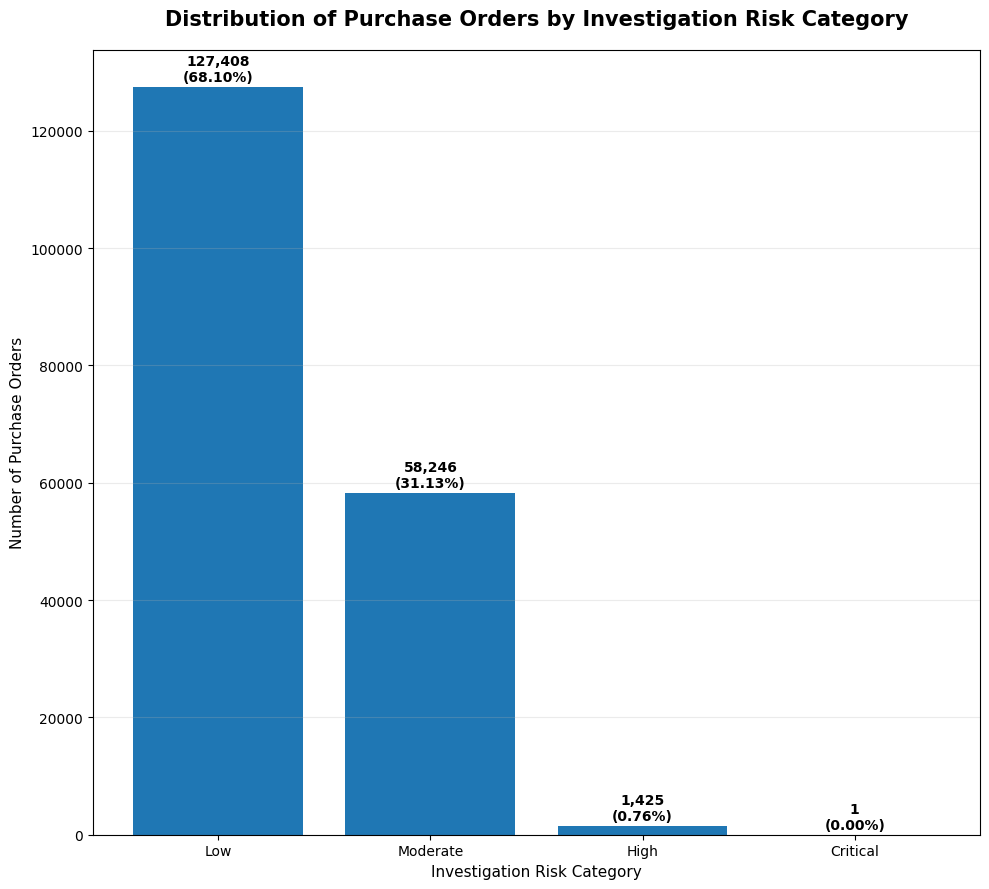

In [ ]:
import matplotlib.pyplot as plt

risk_category_counts = (
    risk_df["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Critical"])
    .fillna(0)
)

risk_category_percent = (
    risk_category_counts / risk_category_counts.sum() * 100
)

fig, ax = plt.subplots(figsize=(10, 9))

bars = ax.bar(
    risk_category_counts.index,
    risk_category_counts.values
)

ax.set_title(
    "Distribution of Purchase Orders by Investigation Risk Category",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Investigation Risk Category", fontsize=11)
ax.set_ylabel("Number of Purchase Orders", fontsize=11)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, count, pct in zip(
    bars,
    risk_category_counts.values,
    risk_category_percent.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{int(count):,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Investigation Risk Score Distribution**

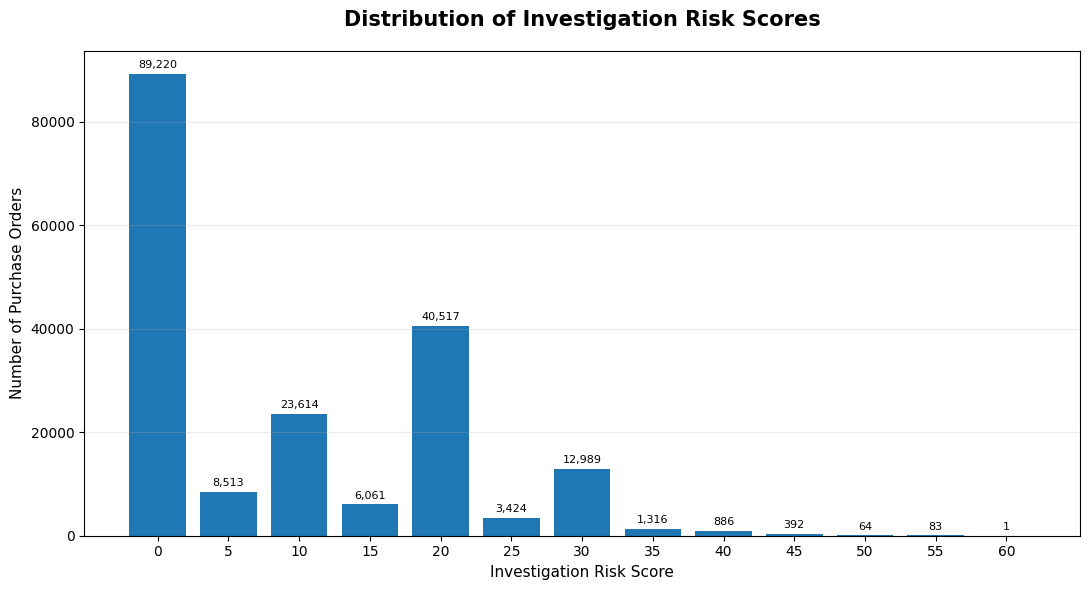

In [ ]:
import matplotlib.pyplot as plt

score_counts = (
    risk_df["Investigation_Risk_Score"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    score_counts.index.astype(str),
    score_counts.values
)

ax.set_title(
    "Distribution of Investigation Risk Scores",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Investigation Risk Score",
    fontsize=11
)

ax.set_ylabel(
    "Number of Purchase Orders",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, count in zip(bars, score_counts.values):
    if count > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(score_counts.values) * 0.008,
            f"{int(count):,}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()
plt.show()

**Risk Component Contribution**

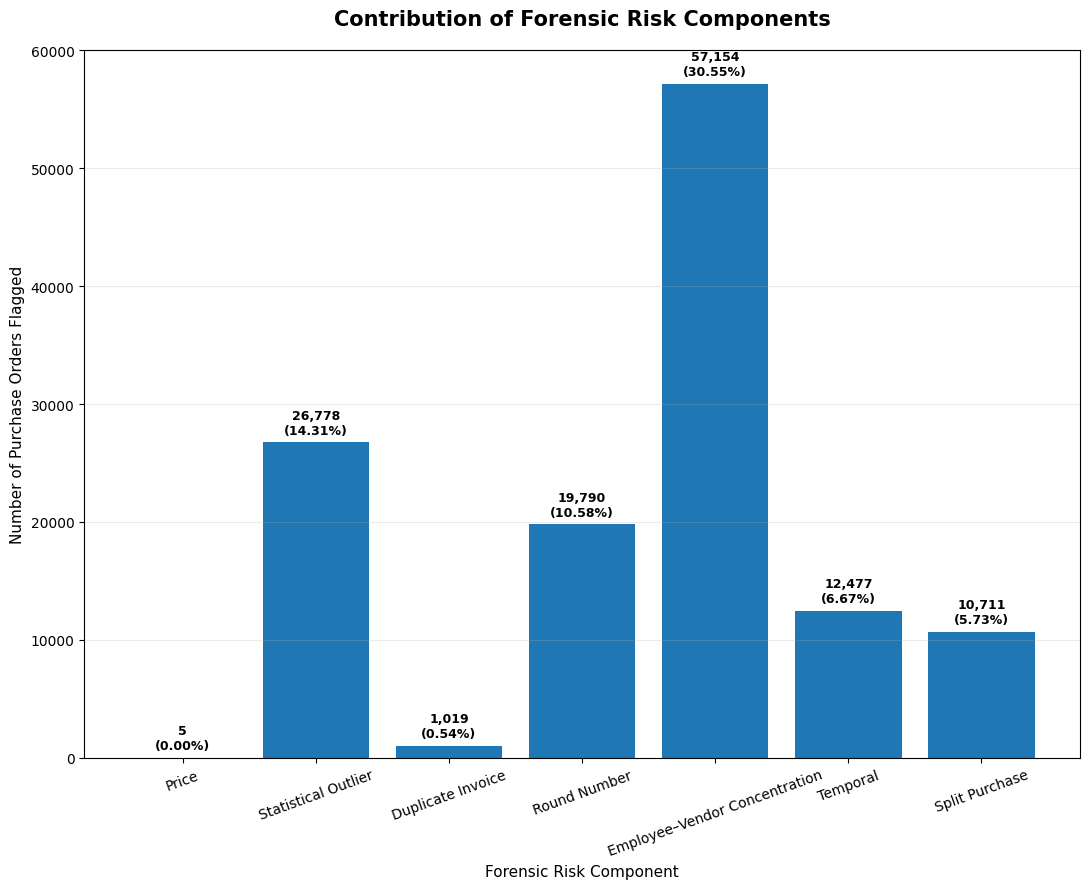

In [ ]:
import matplotlib.pyplot as plt

component_weights = {
    "Price_Risk": 25,
    "Outlier_Risk": 10,
    "Duplicate_Risk": 20,
    "Round_Number_Risk": 5,
    "Concentration_Risk": 20,
    "Temporal_Risk": 10,
    "Split_Purchase_Risk": 10
}

component_counts = {
    component: int(risk_df[component].sum())
    for component in component_weights
}

component_percent = {
    component: (count / len(risk_df)) * 100
    for component, count in component_counts.items()
}

component_labels = [
    "Price",
    "Statistical Outlier",
    "Duplicate Invoice",
    "Round Number",
    "Employee–Vendor Concentration",
    "Temporal",
    "Split Purchase"
]

components = list(component_weights.keys())
counts = [component_counts[c] for c in components]
percentages = [component_percent[c] for c in components]

fig, ax = plt.subplots(figsize=(11, 9))

bars = ax.bar(
    component_labels,
    counts
)

ax.set_title(
    "Contribution of Forensic Risk Components",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Forensic Risk Component",
    fontsize=11
)

ax.set_ylabel(
    "Number of Purchase Orders Flagged",
    fontsize=11
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, count, pct in zip(
    bars,
    counts,
    percentages
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.008,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Ground Truth Detection Performance**

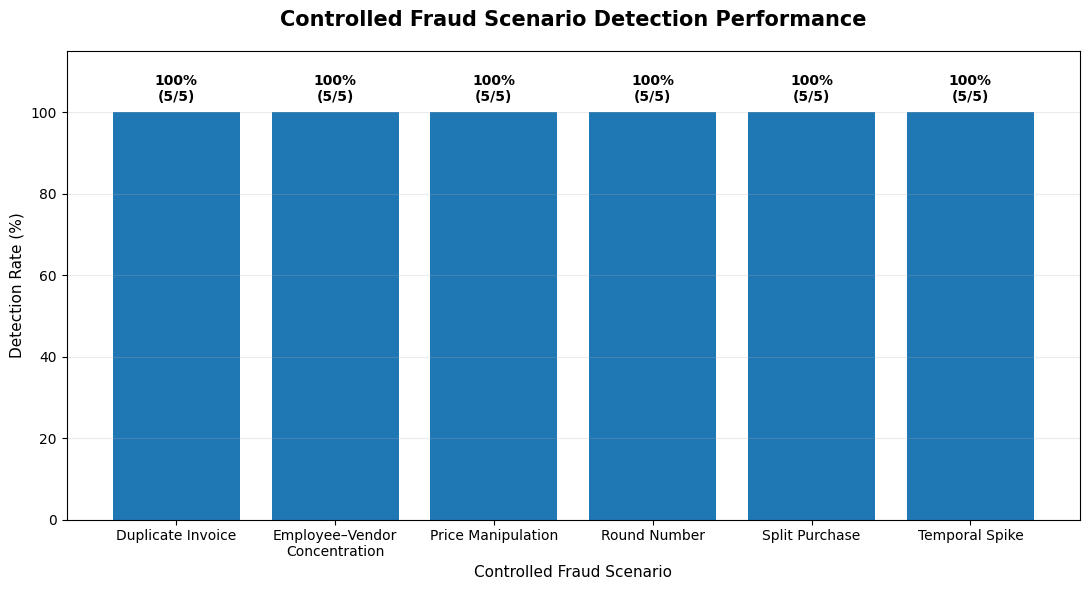

In [ ]:
import matplotlib.pyplot as plt

scenario_detection = (
    gt_eval
    .groupby("Scenario")
    .agg(
        Detected=("Detection", "sum"),
        Total=("Detection", "count")
    )
    .reset_index()
)

scenario_detection["Detection_Rate"] = (
    scenario_detection["Detected"]
    / scenario_detection["Total"]
    * 100
)

scenario_order = [
    "DUPLICATE_INVOICE",
    "EMPLOYEE_VENDOR_CONCENTRATION",
    "PRICE_MANIPULATION",
    "ROUND_NUMBER",
    "SPLIT_PURCHASE",
    "TEMPORAL_SPIKE"
]

scenario_detection["Scenario"] = pd.Categorical(
    scenario_detection["Scenario"],
    categories=scenario_order,
    ordered=True
)

scenario_detection = (
    scenario_detection
    .sort_values("Scenario")
    .reset_index(drop=True)
)

scenario_labels = [
    "Duplicate Invoice",
    "Employee–Vendor\nConcentration",
    "Price Manipulation",
    "Round Number",
    "Split Purchase",
    "Temporal Spike"
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    scenario_labels,
    scenario_detection["Detection_Rate"]
)

ax.set_title(
    "Controlled Fraud Scenario Detection Performance",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Controlled Fraud Scenario",
    fontsize=11
)

ax.set_ylabel(
    "Detection Rate (%)",
    fontsize=11
)

ax.set_ylim(0, 115)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, rate, detected, total in zip(
    bars,
    scenario_detection["Detection_Rate"],
    scenario_detection["Detected"],
    scenario_detection["Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 2,
        f"{rate:.0f}%\n({int(detected)}/{int(total)})",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Top 10 Investigation Priorities**

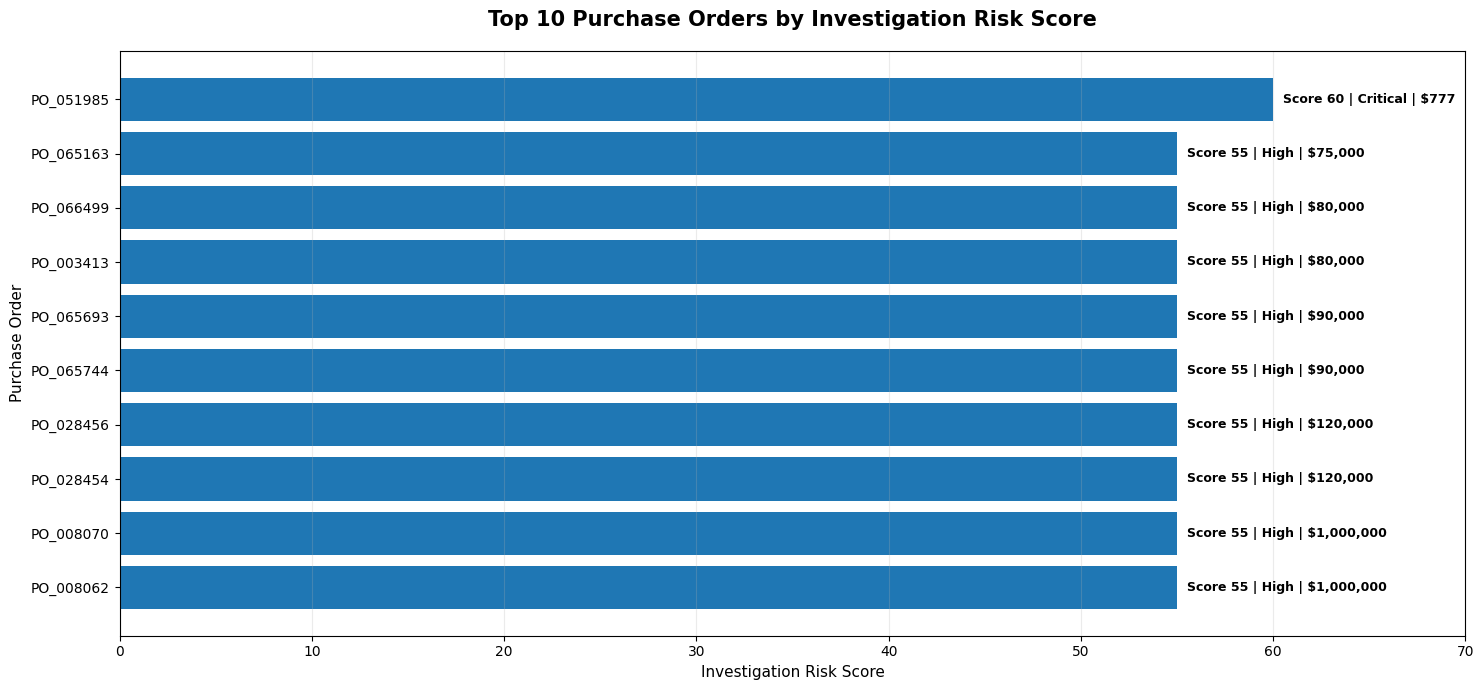

In [ ]:
import matplotlib.pyplot as plt

top_10 = (
    investigation_priority
    .head(10)
    .copy()
    .sort_values("Investigation_Risk_Score", ascending=True)
)

fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.barh(
    top_10["PO_ID"],
    top_10["Investigation_Risk_Score"]
)

ax.set_title(
    "Top 10 Purchase Orders by Investigation Risk Score",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Investigation Risk Score",
    fontsize=11
)

ax.set_ylabel(
    "Purchase Order",
    fontsize=11
)

ax.set_xlim(
    0,
    max(top_10["Investigation_Risk_Score"]) + 10
)

ax.grid(
    axis="x",
    alpha=0.25
)

for bar, score, category, value in zip(
    bars,
    top_10["Investigation_Risk_Score"],
    top_10["Risk_Category"],
    top_10["PO_Value"]
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"Score {score:.0f} | {category} | ${value:,.0f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Risk Score vs Purchase Order Value**

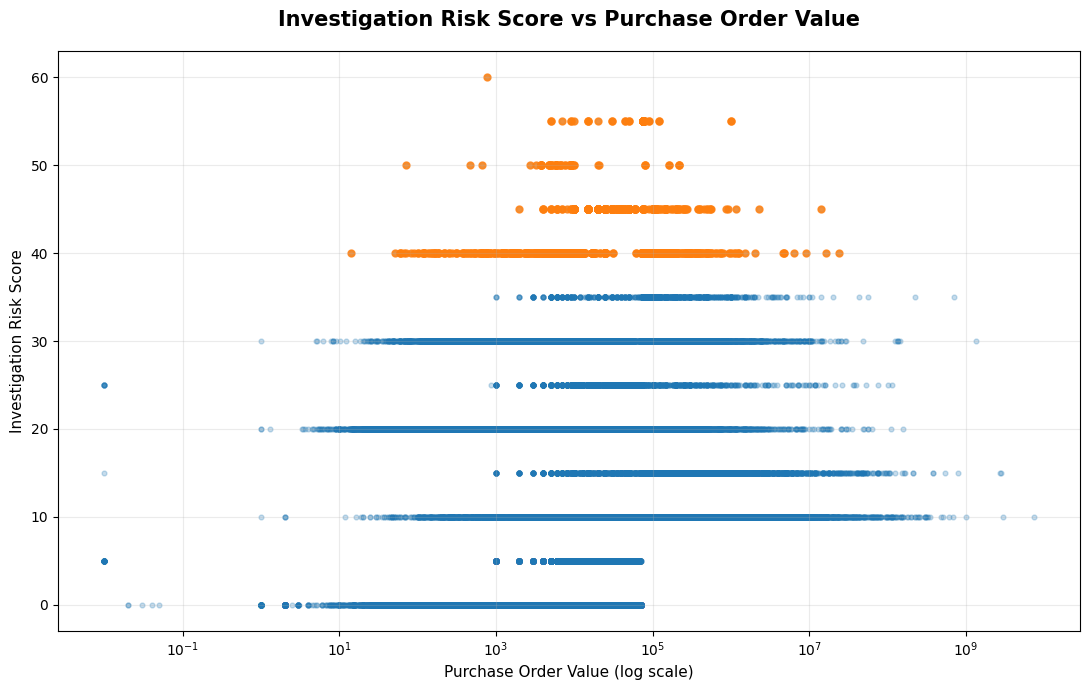

In [ ]:
import matplotlib.pyplot as plt

plot_df = risk_df[
    ["PO_ID", "PO_Value", "Investigation_Risk_Score", "Risk_Category"]
].copy()

plot_df = plot_df[
    plot_df["PO_Value"] > 0
].copy()

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    plot_df["PO_Value"],
    plot_df["Investigation_Risk_Score"],
    alpha=0.25,
    s=12
)

high_critical = plot_df[
    plot_df["Risk_Category"].isin(["High", "Critical"])
]

ax.scatter(
    high_critical["PO_Value"],
    high_critical["Investigation_Risk_Score"],
    alpha=0.8,
    s=25
)

ax.set_xscale("log")

ax.set_title(
    "Investigation Risk Score vs Purchase Order Value",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Purchase Order Value (log scale)",
    fontsize=11
)

ax.set_ylabel(
    "Investigation Risk Score",
    fontsize=11
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

**Forensic Evidence Convergence**

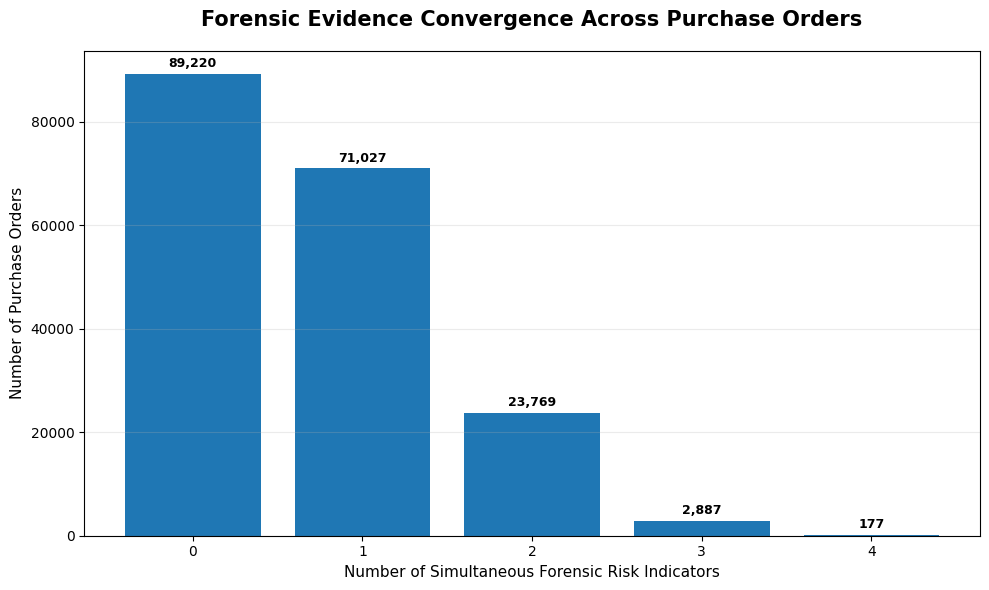

In [ ]:
import matplotlib.pyplot as plt

risk_components = [
    "Price_Risk",
    "Outlier_Risk",
    "Duplicate_Risk",
    "Round_Number_Risk",
    "Concentration_Risk",
    "Temporal_Risk",
    "Split_Purchase_Risk"
]

risk_df["Evidence_Count"] = risk_df[risk_components].sum(axis=1)

evidence_distribution = (
    risk_df["Evidence_Count"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    evidence_distribution.index.astype(str),
    evidence_distribution.values
)

ax.set_title(
    "Forensic Evidence Convergence Across Purchase Orders",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Number of Simultaneous Forensic Risk Indicators",
    fontsize=11
)

ax.set_ylabel(
    "Number of Purchase Orders",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, count in zip(
    bars,
    evidence_distribution.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(evidence_distribution.values) * 0.008,
        f"{int(count):,}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Average Investigation Risk Score by Controlled Scenario**

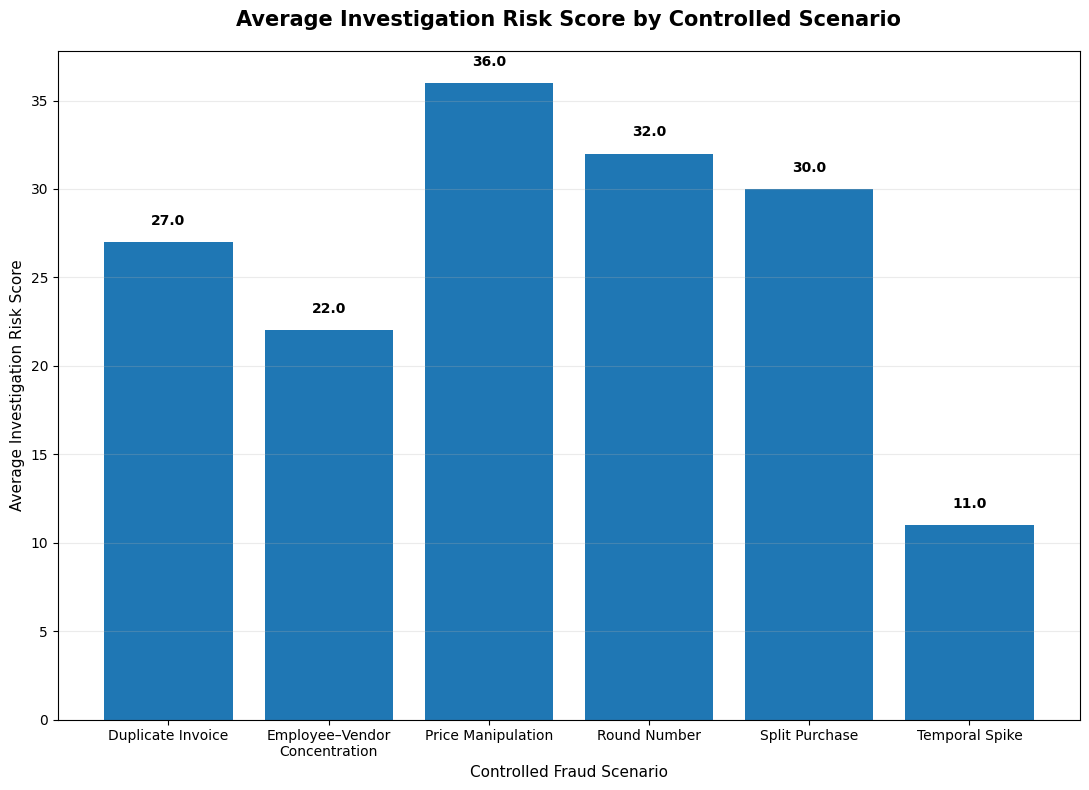

In [ ]:
import matplotlib.pyplot as plt

scenario_risk = (
    gt_eval
    .groupby("Scenario")["Investigation_Risk_Score"]
    .mean()
    .reindex([
        "DUPLICATE_INVOICE",
        "EMPLOYEE_VENDOR_CONCENTRATION",
        "PRICE_MANIPULATION",
        "ROUND_NUMBER",
        "SPLIT_PURCHASE",
        "TEMPORAL_SPIKE"
    ])
)

scenario_labels = [
    "Duplicate Invoice",
    "Employee–Vendor\nConcentration",
    "Price Manipulation",
    "Round Number",
    "Split Purchase",
    "Temporal Spike"
]

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.bar(
    scenario_labels,
    scenario_risk.values
)

ax.set_title(
    "Average Investigation Risk Score by Controlled Scenario",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Controlled Fraud Scenario",
    fontsize=11
)

ax.set_ylabel(
    "Average Investigation Risk Score",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, score in zip(
    bars,
    scenario_risk.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{score:.1f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Total Procurement Value By Investigation Risk Category**

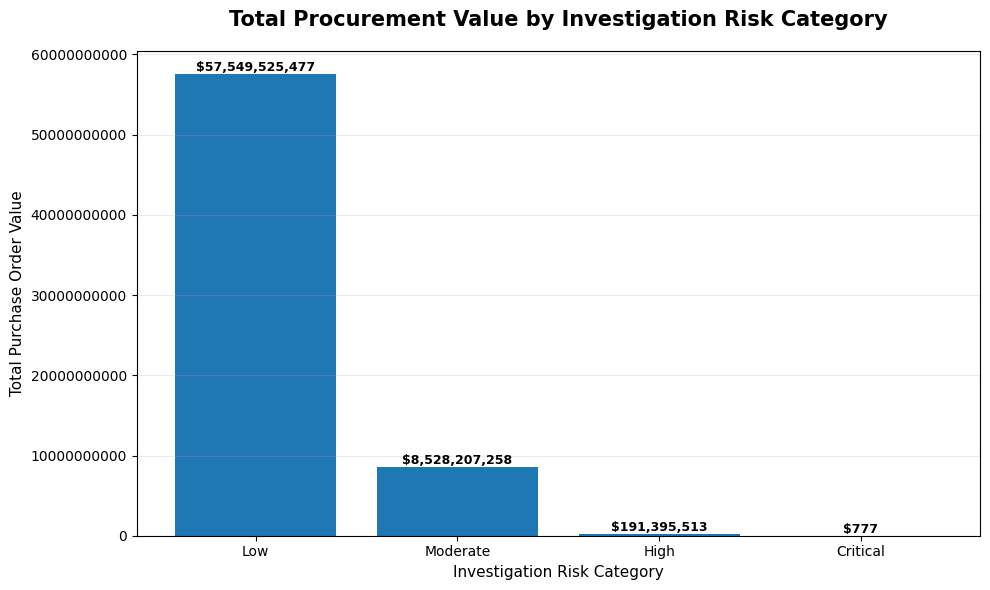

In [ ]:
import matplotlib.pyplot as plt

category_value = (
    risk_df
    .groupby("Risk_Category")["PO_Value"]
    .sum()
    .reindex(["Low", "Moderate", "High", "Critical"])
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    category_value.index,
    category_value.values
)

ax.set_title(
    "Total Procurement Value by Investigation Risk Category",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Investigation Risk Category",
    fontsize=11
)

ax.set_ylabel(
    "Total Purchase Order Value",
    fontsize=11
)

ax.ticklabel_format(
    style="plain",
    axis="y"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    category_value.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"${value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# **CASE 2 : HIGH PROCUREMENT ORDER**

In [ ]:
import pandas as pd

high_po = "PO_008062"

high_po_data = forensic_po[
    forensic_po["PO_ID"] == high_po
].copy()

high_risk = risk_df[
    risk_df["PO_ID"] == high_po
].copy()

high_invoice = forensic_invoice[
    forensic_invoice["PO_ID"] == high_po
].copy()

high_payment = fraud_payment_table[
    fraud_payment_table["PO_ID"] == high_po
].copy()

print("HIGH-RISK CASE INVESTIGATION")
print()

print("Purchase Order:")
display(
    high_po_data[
        [
            "PO_ID",
            "PO_Value",
            "PO_Date",
            "Employee_ID",
            "Supplier_ID"
        ]
    ]
)

print("Risk Assessment:")
display(
    high_risk[
        [
            "PO_ID",
            "Investigation_Risk_Score",
            "Risk_Category",
            "Price_Risk",
            "Outlier_Risk",
            "Duplicate_Risk",
            "Round_Number_Risk",
            "Concentration_Risk",
            "Temporal_Risk",
            "Split_Purchase_Risk"
        ]
    ]
)

print("Invoice Evidence:")
display(
    high_invoice[
        [
            "Invoice_ID",
            "PO_ID",
            "Employee_ID",
            "Supplier_ID",
            "Invoice_Date",
            "Invoice_Amount",
            "Price_Variance_Pct",
            "Duplicate_Invoice_Flag",
            "Round_Number_Flag",
            "Invoice_Payment_Amount_Match",
            "Payment_Lag_Days"
        ]
    ]
)

print("Payment Evidence:")
display(
    high_payment[
        [
            "Payment_ID",
            "Invoice_ID",
            "PO_ID",
            "Employee_ID",
            "Supplier_ID",
            "Payment_Date",
            "Payment_Amount"
        ]
    ]
)

HIGH-RISK CASE INVESTIGATION

Purchase Order:


,PO_ID,PO_Value,PO_Date,Employee_ID,Supplier_ID
8062,PO_008062,1000000.0,2013-10-31,EMP_00161,VENDOR_1106502


Risk Assessment:


,PO_ID,Investigation_Risk_Score,Risk_Category,Price_Risk,Outlier_Risk,Duplicate_Risk,Round_Number_Risk,Concentration_Risk,Temporal_Risk,Split_Purchase_Risk
8062,PO_008062,55,High,0,1,1,1,1,0,0


Invoice Evidence:


,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Invoice_Date,Invoice_Amount,Price_Variance_Pct,Duplicate_Invoice_Flag,Round_Number_Flag,Invoice_Payment_Amount_Match,Payment_Lag_Days
8062,INV_008063,PO_008062,EMP_00161,VENDOR_1106502,2013-11-22,1000000.0,0.0,True,True,True,44.0


Payment Evidence:


,Payment_ID,Invoice_ID,PO_ID,Employee_ID,Supplier_ID,Payment_Date,Payment_Amount
8062,PAY_008063,INV_008063,PO_008062,EMP_00161,VENDOR_1106502,2014-01-05,1000000.0


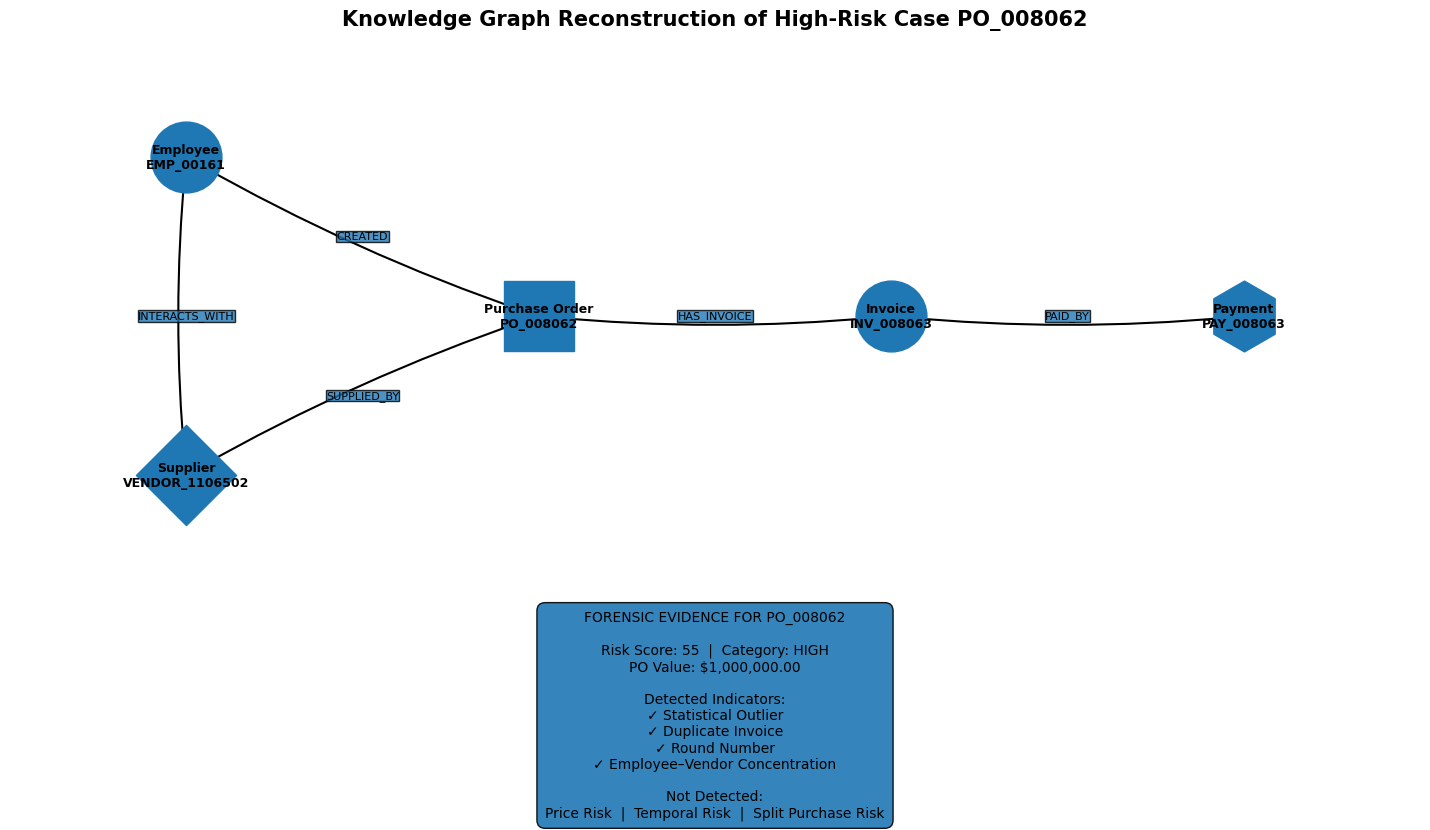

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

high_po = "PO_008062"

high_po_row = forensic_po[
    forensic_po["PO_ID"] == high_po
].iloc[0]

high_invoice_row = forensic_invoice[
    forensic_invoice["PO_ID"] == high_po
].iloc[0]

high_payment_row = fraud_payment_table[
    fraud_payment_table["PO_ID"] == high_po
].iloc[0]

high_risk_row = risk_df[
    risk_df["PO_ID"] == high_po
].iloc[0]

employee_id = high_po_row["Employee_ID"]
supplier_id = high_po_row["Supplier_ID"]
invoice_id = high_invoice_row["Invoice_ID"]
payment_id = high_payment_row["Payment_ID"]

high_graph = nx.DiGraph()

high_graph.add_node(employee_id, node_type="Employee")
high_graph.add_node(supplier_id, node_type="Supplier")
high_graph.add_node(high_po, node_type="Purchase Order")
high_graph.add_node(invoice_id, node_type="Invoice")
high_graph.add_node(payment_id, node_type="Payment")

high_graph.add_edge(employee_id, supplier_id, relationship="INTERACTS_WITH")
high_graph.add_edge(employee_id, high_po, relationship="CREATED")
high_graph.add_edge(high_po, supplier_id, relationship="SUPPLIED_BY")
high_graph.add_edge(high_po, invoice_id, relationship="HAS_INVOICE")
high_graph.add_edge(invoice_id, payment_id, relationship="PAID_BY")

positions = {
    employee_id: (0, 2),
    supplier_id: (0, 0),
    high_po: (3, 1),
    invoice_id: (6, 1),
    payment_id: (9, 1)
}

node_shapes = {
    "Employee": "o",
    "Supplier": "D",
    "Purchase Order": "s",
    "Invoice": "o",
    "Payment": "h"
}

fig, ax = plt.subplots(figsize=(15, 9))

for node_type, shape in node_shapes.items():

    nodes = [
        node for node, data in high_graph.nodes(data=True)
        if data["node_type"] == node_type
    ]

    nx.draw_networkx_nodes(
        high_graph,
        positions,
        nodelist=nodes,
        node_shape=shape,
        node_size=2600,
        ax=ax
    )

nx.draw_networkx_edges(
    high_graph,
    positions,
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.05",
    ax=ax
)

node_labels = {
    employee_id: f"Employee\n{employee_id}",
    supplier_id: f"Supplier\n{supplier_id}",
    high_po: f"Purchase Order\n{high_po}",
    invoice_id: f"Invoice\n{invoice_id}",
    payment_id: f"Payment\n{payment_id}"
}

nx.draw_networkx_labels(
    high_graph,
    positions,
    labels=node_labels,
    font_size=9,
    font_weight="bold",
    ax=ax
)

edge_labels = {
    (u, v): data["relationship"]
    for u, v, data in high_graph.edges(data=True)
}

nx.draw_networkx_edge_labels(
    high_graph,
    positions,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.5,
    rotate=False,
    bbox=dict(
        alpha=0.8,
        pad=0.2
    ),
    ax=ax
)

ax.set_title(
    "Knowledge Graph Reconstruction of High-Risk Case PO_008062",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlim(-1.5, 10.5)
ax.set_ylim(-0.7, 2.7)
ax.axis("off")

risk_text = (
    "FORENSIC EVIDENCE FOR PO_008062\n\n"
    "Risk Score: 55  |  Category: HIGH\n"
    "PO Value: $1,000,000.00\n\n"
    "Detected Indicators:\n"
    "✓ Statistical Outlier\n"
    "✓ Duplicate Invoice\n"
    "✓ Round Number\n"
    "✓ Employee–Vendor Concentration\n\n"
    "Not Detected:\n"
    "Price Risk  |  Temporal Risk  |  Split Purchase Risk"
)

fig.text(
    0.5,
    0.02,
    risk_text,
    ha="center",
    va="bottom",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.6",
        alpha=0.9
    )
)

plt.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.88,
    bottom=0.28
)

plt.show()

In [ ]:
import os
import zipfile
import pandas as pd
from google.colab import files

output_dir = "forensic_project_data"
os.makedirs(output_dir, exist_ok=True)

files_to_save = {
    "processed_line_items.csv": clean_df,
    "procurement_baseline.csv": po_table,
    "employee_layer.csv": employee_table,
    "invoice_layer.csv": fraud_invoice_table,
    "payment_layer.csv": fraud_payment_table,
    "fraud_ground_truth.csv": fraud_ground_truth,
    "forensic_invoice_analysis.csv": forensic_invoice,
    "forensic_po_analysis.csv": forensic_po,
    "employee_vendor_analysis.csv": forensic_employee_vendor,
    "evidence_convergence.csv": evidence_convergence,
    "final_risk_scores.csv": risk_df,
    "investigation_priority.csv": investigation_priority
}

print("Saving project datasets...\n")

for filename, dataframe in files_to_save.items():
    path = os.path.join(output_dir, filename)
    dataframe.to_csv(path, index=False)
    print(f"✓ {filename}  →  {len(dataframe):,} rows")

zip_name = "procurement_forensic_project_data.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in os.listdir(output_dir):
        zipf.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("\nZIP file created successfully:")
print(zip_name)

files.download(zip_name)

Saving project datasets...

✓ processed_line_items.csv  →  318,962 rows
✓ procurement_baseline.csv  →  187,080 rows
✓ employee_layer.csv  →  350 rows
✓ invoice_layer.csv  →  187,085 rows
✓ payment_layer.csv  →  187,080 rows
✓ fraud_ground_truth.csv  →  30 rows
✓ forensic_invoice_analysis.csv  →  187,085 rows
✓ forensic_po_analysis.csv  →  187,080 rows
✓ employee_vendor_analysis.csv  →  87,888 rows
✓ evidence_convergence.csv  →  30 rows
✓ final_risk_scores.csv  →  187,080 rows
✓ investigation_priority.csv  →  187,080 rows

ZIP file created successfully:
procurement_forensic_project_data.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>